# import

In [36]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import paramiko
from scp import SCPClient
import os
import pandas as pd
import numpy as np
import re
import time
import subprocess
import ast
from datetime import datetime
import shutil
from datetime import datetime
import rdkit

from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem
from sklearn.model_selection import train_test_split,KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,make_scorer, mean_squared_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import xgboost as xgb
from sklearn.preprocessing import MinMaxScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import MessagePassing, global_mean_pool
from torch_geometric.data import Data, DataLoader
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
from sklearn.metrics import log_loss
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
import gc
import shutil
import posixpath
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, ttest_ind, ks_2samp
import inspect
import glob
from sklearn.linear_model import Ridge
from rdkit import DataStructs
import itertools
from rdkit.Chem import rdFingerprintGenerator
from matplotlib.lines import Line2D

# 各モデルの成功MD＋nonMD

In [6]:
import os
import pandas as pd

save_dir = "/Users/teraimao/experiment/data/解析結果"

NONMD_CSV = "/Users/teraimao/experiment/data/解析結果/スライド検証用/baselineB_dataset.csv"

md_files = {
    "gbsw": "gbsw_common_successID.csv",
    "hdgb": "hdgb_common_successID.csv",
    "hdgbvdw": "hdgbvdw_common_successID.csv",
}

output_files = {
    "gbsw": "gbsw_common_successID_baselineB.csv",
    "hdgb": "hdgb_common_successID_baselineB.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB.csv",
}

id_col = "ID"
target_col = "Permeability"

# =========================
# baselineB 読み込み
# =========================

nonmd = pd.read_csv(NONMD_CSV)

nonmd[id_col] = nonmd[id_col].astype(int)

print("===== baselineB =====")
print("path:", NONMD_CSV)
print("shape:", nonmd.shape)
print("unique IDs:", nonmd[id_col].nunique())
print("duplicate IDs:", nonmd.duplicated(id_col).sum())
print("target NaN:", nonmd[target_col].isna().sum())

# 念のためID重複があった場合だけ除去
if nonmd.duplicated(id_col).sum() > 0:
    nonmd = nonmd.drop_duplicates(subset=[id_col], keep="first").copy()

# =========================
# MD + baselineB 結合
# =========================

for model, md_fname in md_files.items():
    print("\n" + "="*80)
    print("model:", model)

    md_path = os.path.join(save_dir, md_fname)
    out_path = os.path.join(save_dir, output_files[model])

    md = pd.read_csv(md_path)

    md[id_col] = md[id_col].astype(int)
    md["Pos_Num"] = md["Pos_Num"].astype(int)

    print("MD path:", md_path)
    print("MD rows:", len(md))
    print("MD unique IDs:", md[id_col].nunique())
    print("MD Status counts:")
    print(md["Status"].value_counts(dropna=False))

    merged = md.merge(
        nonmd,
        on=id_col,
        how="inner",
        suffixes=("", "_baselineB")
    )

    print("merged rows:", len(merged))
    print("merged unique IDs:", merged[id_col].nunique())
    print("target NaN:", merged[target_col].isna().sum())
    print("duplicate ID/Pos:", merged.duplicated([id_col, "Pos_Num"]).sum())

    pos_count = merged.groupby(id_col)["Pos_Num"].nunique()
    print("pos count distribution:")
    print(pos_count.value_counts().sort_index())

    missing_ids = sorted(set(md[id_col].unique()) - set(merged[id_col].unique()))
    print("missing IDs from baselineB:", len(missing_ids))
    if len(missing_ids) > 0:
        print("missing ID examples:", missing_ids[:20])

    merged.to_csv(out_path, index=False)
    print("saved:", out_path)

print("\n✅ MD + baselineB merged CSVs created")

===== baselineB =====
path: /Users/teraimao/experiment/data/解析結果/スライド検証用/baselineB_dataset.csv
shape: (8466, 142)
unique IDs: 8466
duplicate IDs: 0
target NaN: 0

model: gbsw
MD path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID.csv
MD rows: 37630
MD unique IDs: 7526
MD Status counts:
Status
Success    37630
Name: count, dtype: int64
merged rows: 37630
merged unique IDs: 7526
target NaN: 0
duplicate ID/Pos: 0
pos count distribution:
Pos_Num
5    7526
Name: count, dtype: int64
missing IDs from baselineB: 0
saved: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB.csv

model: hdgb
MD path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID.csv
MD rows: 37630
MD unique IDs: 7526
MD Status counts:
Status
Success    37630
Name: count, dtype: int64
merged rows: 37630
merged unique IDs: 7526
target NaN: 0
duplicate ID/Pos: 0
pos count distribution:
Pos_Num
5    7526
Name: count, dtype: int64
missing IDs from baselineB: 0
saved: /Users/teraimao/experimen

In [7]:
import os
import pandas as pd

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "gbsw": "gbsw_common_successID_baselineB.csv",
    "hdgb": "hdgb_common_successID_baselineB.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB.csv",
}

id_col = "ID"
pos_col = "Pos_Num"

md_feature_cols = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

# IDごとに1つだけ残すnonMD列
# ここに入っていないMD由来の管理列・パス列・状態列は基本的に落とす
md_metadata_cols = [
    "Model",
    "Date",
    "t_end_ps",
    "Cons_Label",
    "Pos_Num",
    "Z",
    "WorkDir",
    "LogPath",
    "HB_Path",
    "SASA_Path",
    "Status",
    "Message",
    "skip_ps",
    "dt_ps",
    "tolerance_frames",
    "Normal_Termination",
] + md_feature_cols

for model, fname in files.items():
    print("\n" + "="*80)
    print("model:", model)

    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path)

    print("input path:", path)
    print("input rows:", len(df))
    print("input unique IDs:", df[id_col].nunique())

    df[id_col] = df[id_col].astype(int)
    df[pos_col] = df[pos_col].astype(int)

    # 念のため確認
    pos_count = df.groupby(id_col)[pos_col].nunique()
    print("pos count distribution before:")
    print(pos_count.value_counts().sort_index())

    if not (pos_count == 5).all():
        raise ValueError(f"{model}: pos 1〜5 がそろっていないIDがあります")

    if df.duplicated([id_col, pos_col]).sum() > 0:
        raise ValueError(f"{model}: duplicate ID/Pos があります")

    # =========================
    # 1. nonMD部分をIDごとに1行だけ残す
    # =========================

    nonmd_cols = [c for c in df.columns if c not in md_metadata_cols]

    # IDは必ず入れる
    if id_col not in nonmd_cols:
        nonmd_cols = [id_col] + nonmd_cols

    nonmd = df[nonmd_cols].drop_duplicates(subset=[id_col], keep="first").copy()

    print("nonMD columns:", len(nonmd.columns))
    print("nonMD rows:", len(nonmd))

    # =========================
    # 2. MD特徴量をposごとに横展開
    # =========================

    md = df[[id_col, pos_col] + md_feature_cols].copy()

    md_wide = md.pivot(
        index=id_col,
        columns=pos_col,
        values=md_feature_cols
    )

    # 列名を HB_Avg_pos1 の形にする
    md_wide.columns = [
        f"{feature}_pos{pos}"
        for feature, pos in md_wide.columns
    ]

    md_wide = md_wide.reset_index()

    print("MD wide shape:", md_wide.shape)

    # =========================
    # 3. nonMD + 横展開MD を結合
    # =========================

    wide = nonmd.merge(md_wide, on=id_col, how="inner")

    wide = wide.sort_values(id_col).reset_index(drop=True)

    print("output rows:", len(wide))
    print("output unique IDs:", wide[id_col].nunique())
    print("output columns:", len(wide.columns))

    # 確認
    if "Permeability" in wide.columns:
        print("Permeability NaN:", wide["Permeability"].isna().sum())

    md_wide_cols = [c for c in wide.columns if any(c.startswith(f"{m}_pos") for m in md_feature_cols)]
    print("MD wide feature columns:", len(md_wide_cols))
    print("MD wide NaN total:", wide[md_wide_cols].isna().sum().sum())

    assert len(wide) == df[id_col].nunique()
    assert wide[id_col].duplicated().sum() == 0
    assert wide[md_wide_cols].isna().sum().sum() == 0

    # =========================
    # 4. 既存ファイルを消して、同じ名前で保存
    # =========================

    if os.path.exists(path):
        os.remove(path)
        print("deleted old file:", path)

    wide.to_csv(path, index=False)
    print("saved new wide file:", path)

print("\n✅ All files were replaced with ID-level wide CSVs")


model: gbsw
input path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB.csv
input rows: 37630
input unique IDs: 7526
pos count distribution before:
Pos_Num
5    7526
Name: count, dtype: int64
nonMD columns: 142
nonMD rows: 7526
MD wide shape: (7526, 26)
output rows: 7526
output unique IDs: 7526
output columns: 167
Permeability NaN: 0
MD wide feature columns: 25
MD wide NaN total: 0
deleted old file: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB.csv
saved new wide file: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB.csv

model: hdgb
input path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB.csv
input rows: 37630
input unique IDs: 7526
pos count distribution before:
Pos_Num
5    7526
Name: count, dtype: int64
nonMD columns: 142
nonMD rows: 7526
MD wide shape: (7526, 26)
output rows: 7526
output unique IDs: 7526
output columns: 167
Permeability NaN: 0
MD wide feature columns: 25
MD wide NaN total: 0
d

# （PAMPA -10などの制限なし）３モデルMDのみ比較

In [9]:
# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB.csv",
    "HDGB": "hdgb_common_successID_baselineB.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB.csv",
}

id_col = "ID"
target_col = "Permeability"

base_md_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

feature_cols = [
    f"{feat}_pos{pos}"
    for feat in base_md_features
    for pos in [1, 2, 3, 4, 5]
]

random_state = 42
test_size = 0.2

# =========================
# 評価関数：Pearson修正版
# =========================

def calc_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    pearson = np.corrcoef(y_true, y_pred)[0, 1]
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return {
        "Pearson_R": pearson,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    }

# =========================
# データ読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path)

    df[id_col] = df[id_col].astype(int)

    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{model_name}: MD特徴量が足りません: {missing}")

    if target_col not in df.columns:
        raise ValueError(f"{model_name}: {target_col} がありません")

    use_df = df[[id_col, target_col] + feature_cols].copy()

    use_df[target_col] = pd.to_numeric(use_df[target_col], errors="coerce")
    for c in feature_cols:
        use_df[c] = pd.to_numeric(use_df[c], errors="coerce")

    before = len(use_df)
    use_df = use_df.dropna(subset=[target_col] + feature_cols).copy()
    after = len(use_df)

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("rows before:", before)
    print("rows used  :", after)
    print("unique IDs :", use_df[id_col].nunique())
    print("features   :", len(feature_cols))
    print("target min/max/mean/std:")
    print(use_df[target_col].describe())

    datasets[model_name] = use_df

# =========================
# 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)
    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# =========================
# 同一 train/test split
# =========================

train_ids, test_ids = train_test_split(
    common_ids,
    test_size=test_size,
    random_state=random_state
)

train_ids = set(train_ids)
test_ids = set(test_ids)

print("\ntrain IDs:", len(train_ids))
print("test IDs :", len(test_ids))

# =========================
# Random Forestで比較
# =========================

results = []
predictions = []
feature_importances = []

for model_name, df in datasets.items():
    print("\n" + "="*80)
    print("Training:", model_name)

    train_df = df[df[id_col].isin(train_ids)].copy()
    test_df = df[df[id_col].isin(test_ids)].copy()

    X_train = train_df[feature_cols]
    y_train = train_df[target_col]

    X_test = test_df[feature_cols]
    y_test = test_df[target_col]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=random_state,
        n_jobs=-1,
        min_samples_leaf=3
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    metrics = calc_metrics(y_test, y_pred)

    results.append({
        "MD_model": model_name,
        "N_total": len(df),
        "N_train": len(train_df),
        "N_test": len(test_df),
        "N_features": len(feature_cols),
        **metrics,
    })

    print(f"Pearson R: {metrics['Pearson_R']:.4f}")
    print(f"R2       : {metrics['R2']:.4f}")
    print(f"MAE      : {metrics['MAE']:.4f}")
    print(f"RMSE     : {metrics['RMSE']:.4f}")

    predictions.append(pd.DataFrame({
        id_col: test_df[id_col].values,
        "MD_model": model_name,
        "y_true": np.asarray(y_test),
        "y_pred": y_pred,
    }))

    feature_importances.append(pd.DataFrame({
        "MD_model": model_name,
        "Feature": feature_cols,
        "Importance": rf.feature_importances_,
    }).sort_values("Importance", ascending=False))

# =========================
# 保存
# =========================

results_df = pd.DataFrame(results)
predictions_df = pd.concat(predictions, ignore_index=True)
importance_df = pd.concat(feature_importances, ignore_index=True)

metrics_out = os.path.join(save_dir, "rf_3model_MD25_only_metrics_fixedPearson.csv")
pred_out = os.path.join(save_dir, "rf_3model_MD25_only_predictions_fixedPearson.csv")
imp_out = os.path.join(save_dir, "rf_3model_MD25_only_feature_importance_fixedPearson.csv")

results_df.to_csv(metrics_out, index=False)
predictions_df.to_csv(pred_out, index=False)
importance_df.to_csv(imp_out, index=False)

print("\n" + "="*80)
print("Saved:")
print(metrics_out)
print(pred_out)
print(imp_out)

print("\n===== 3 model comparison: MD25 only =====")
display(results_df.sort_values("R2", ascending=False))

print("\n===== Top 10 feature importance per MD model =====")
display(importance_df.groupby("MD_model").head(10))


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB.csv
rows before: 7526
rows used  : 7526
unique IDs : 7526
features   : 25
target min/max/mean/std:
count    7526.000000
mean       -5.947189
std         1.083099
min       -10.000000
25%        -6.330000
50%        -5.740000
75%        -5.290000
max        -3.900000
Name: Permeability, dtype: float64

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB.csv
rows before: 7526
rows used  : 7526
unique IDs : 7526
features   : 25
target min/max/mean/std:
count    7526.000000
mean       -5.947189
std         1.083099
min       -10.000000
25%        -6.330000
50%        -5.740000
75%        -5.290000
max        -3.900000
Name: Permeability, dtype: float64

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB.csv
rows before: 7526
rows used  : 7526
unique IDs : 7526
features   : 25
target min/max/mean/std:
count    7526.000000
mean       -5.947189
std   

,MD_model,N_total,N_train,N_test,N_features,Pearson_R,R2,MAE,RMSE
0,GBSW,7526,6020,1506,25,0.381047,0.140545,0.693532,1.013991
2,HDGBvdW,7526,6020,1506,25,0.378784,0.137959,0.694613,1.015515
1,HDGB,7526,6020,1506,25,0.366185,0.128015,0.705032,1.021355



===== Top 10 feature importance per MD model =====


,MD_model,Feature,Importance
0,GBSW,HB_Avg_pos1,0.049773
1,GBSW,SASA_Avg_pos1,0.045543
2,GBSW,vdW_Avg_pos5,0.045160
3,GBSW,HB_Avg_pos2,0.045073
4,GBSW,Coul_Avg_pos3,0.044610
5,GBSW,vdW_Avg_pos1,0.044333
6,GBSW,Solv_Free_Avg_pos2,0.043312
7,GBSW,Coul_Avg_pos1,0.043225
8,GBSW,vdW_Avg_pos2,0.042325
9,GBSW,vdW_Avg_pos3,0.041795


# PAMPA,-10などを除いたcsv

In [10]:
save_dir = "/Users/teraimao/experiment/data/解析結果"

DB_CSV = "/Users/teraimao/experiment/data/all_csv_data/strict_this_is_CycPeptMPDB_PAMPA.csv"

input_files = {
    "gbsw": "gbsw_common_successID_baselineB.csv",
    "hdgb": "hdgb_common_successID_baselineB.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB.csv",
}

output_files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
}

id_col = "ID"
strict_target_col = "PAMPA"
new_target_col = "PAMPA_logPm"

md25_cols = [
    f"{feat}_pos{pos}"
    for feat in ["HB_Avg", "SASA_Avg", "Solv_Free_Avg", "vdW_Avg", "Coul_Avg"]
    for pos in [1, 2, 3, 4, 5]
]

def is_blank_value(x):
    if pd.isna(x):
        return True
    s = str(x).strip()
    return s == "" or s.lower() in ["nan", "none", "null", "na", "n/a", "<na>"]

# =========================
# 1. strict PAMPA target作成
# =========================

db = pd.read_csv(DB_CSV, low_memory=False)

print("===== strict PAMPA DB =====")
print("path:", DB_CSV)
print("shape:", db.shape)
print("columns:", db.columns.tolist())

if id_col not in db.columns:
    raise ValueError("DBにID列がありません")

if strict_target_col not in db.columns:
    raise ValueError("DBにPAMPA列がありません")

target = db.copy()

target[id_col] = pd.to_numeric(target[id_col], errors="coerce")
target[strict_target_col] = pd.to_numeric(target[strict_target_col], errors="coerce")

before = len(target)
target = target.dropna(subset=[id_col, strict_target_col]).copy()
target[id_col] = target[id_col].astype(int)
print("\nafter dropna ID/PAMPA:", len(target), "removed:", before - len(target))

# Detection Limitが残っていたら除外
for dl_col in ["Detection_Limit_1", "Detection_Limit_2"]:
    if dl_col in target.columns:
        before = len(target)
        target = target[target[dl_col].apply(is_blank_value)].copy()
        print(f"after remove {dl_col} not blank:", len(target), "removed:", before - len(target))
    else:
        print(f"{dl_col}: column not found")

# PAMPA=-10を除外
before = len(target)
target = target[target[strict_target_col] != -10].copy()
print("after remove PAMPA=-10:", len(target), "removed:", before - len(target))

# ID重複除去
before = len(target)
target = target[[id_col, strict_target_col]].drop_duplicates(subset=[id_col], keep="first").copy()
target = target.rename(columns={strict_target_col: new_target_col})
print("after drop duplicate IDs:", len(target), "removed:", before - len(target))

print("\nstrict target summary:")
print("unique IDs:", target[id_col].nunique())
print("target NaN:", target[new_target_col].isna().sum())
print(target[new_target_col].describe())

# =========================
# 2. 各MD wide CSVにstrict PAMPAを結合
# =========================

target_like_exact_cols = [
    "Permeability",
    "permeability",
    "PAMPA",
    "PAMPA_logPm",
    "logPm",
    "LogPm",
    "logPapp",
    "LogPapp",
    "PAMPA_logPapp",
]

for model, fname in input_files.items():
    print("\n" + "="*80)
    print("model:", model)

    in_path = os.path.join(save_dir, fname)
    out_path = os.path.join(save_dir, output_files[model])

    df = pd.read_csv(in_path, low_memory=False)
    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df = df.dropna(subset=[id_col]).copy()
    df[id_col] = df[id_col].astype(int)

    print("input:", in_path)
    print("input shape:", df.shape)
    print("input unique IDs:", df[id_col].nunique())
    print("input duplicate IDs:", df[id_col].duplicated().sum())

    # 念のため、今入っているPermeabilityとstrict PAMPAの違いを確認
    if "Permeability" in df.columns:
        old_y = df[[id_col, "Permeability"]].drop_duplicates(subset=[id_col], keep="first").copy()
        old_y["Permeability"] = pd.to_numeric(old_y["Permeability"], errors="coerce")
        check = old_y.merge(target, on=id_col, how="inner")

        print("\nold Permeability vs strict PAMPA:")
        print("common IDs for check:", len(check))
        if len(check) > 0:
            print("corr:", check["Permeability"].corr(check[new_target_col]))
            print("mean old Permeability:", check["Permeability"].mean())
            print("mean strict PAMPA    :", check[new_target_col].mean())
            print("max abs diff:", (check["Permeability"] - check[new_target_col]).abs().max())

    # 古い目的変数っぽい列は落として、strict PAMPAだけを目的変数にする
    drop_cols = [c for c in target_like_exact_cols if c in df.columns and c != id_col]
    print("\ndrop old target-like columns:", drop_cols)

    df_no_target = df.drop(columns=drop_cols).copy()

    # strict PAMPAを結合
    merged = target.merge(df_no_target, on=id_col, how="inner")

    # 列順を整える
    other_cols = [c for c in merged.columns if c not in [id_col, new_target_col]]
    merged = merged[[id_col, new_target_col] + other_cols].copy()

    print("\nmerged shape:", merged.shape)
    print("merged unique IDs:", merged[id_col].nunique())
    print("target NaN:", merged[new_target_col].isna().sum())
    print("duplicate IDs:", merged[id_col].duplicated().sum())

    missing_md = [c for c in md25_cols if c not in merged.columns]
    if missing_md:
        raise ValueError(f"{model}: MD25列が足りません: {missing_md}")

    print("MD25 NaN total:", merged[md25_cols].isna().sum().sum())

    # 保存
    merged.to_csv(out_path, index=False)
    print("saved:", out_path)

print("\n✅ strict PAMPA CSVs created")

===== strict PAMPA DB =====
path: /Users/teraimao/experiment/data/all_csv_data/strict_this_is_CycPeptMPDB_PAMPA.csv
shape: (6925, 265)
columns: ['ID', 'Source', 'Year', 'Version', 'Original_Name_in_Source_Literature', 'Structurally_Unique_ID', 'Same_Peptides_ID', 'Same_Peptides_Source', 'Same_Peptides_Permeability', 'Same_Peptides_Assay', 'SMILES', 'HELM', 'N-number', 'C-number', 'HELM_URL', 'Sequence', 'Modifier', 'Patch_From_Modifier', 'Clean_Sequence', 'Cycle_Length', 'newN_number', 'newC_number', 'Modifier_Warning', 'Cyc_Patch', 'Sequence_LogP', 'Sequence_TPSA', 'Monomer_Length', 'Monomer_Length_in_Main_Chain', 'Molecule_Shape', 'Permeability', 'PAMPA', 'Caco2', 'MDCK', 'RRCK', 'Detection_Limit_1', 'Detection_Limit_2', 'R_PAMAP', 'R_Caco2', 'R_MDCK', 'R_RRCK', 'T_PAMPA', 'EPSA', 'PSA', '_3DPSA', 'NULL', 'MaxEStateIndex', 'MinEStateIndex', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'qed', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'NumRadicalElectrons', 'MaxParti

# 予測条件

# 3つのモデル比較 MDのみ

In [12]:
# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
}

id_col = "ID"
target_col = "PAMPA_logPm"

base_md_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

feature_cols = [
    f"{feat}_pos{pos}"
    for feat in base_md_features
    for pos in [1, 2, 3, 4, 5]
]

RANDOM_STATE = 42
TEST_SIZE = 0.2

# 全strict PAMPA共通IDを使う
MAX_ID = None

# 前回のID<=1000条件に寄せたい場合だけこちらに変更
# MAX_ID = 1000

# =========================
# データ読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, target_col]).copy()
    df[id_col] = df[id_col].astype(int)

    if MAX_ID is not None:
        df = df[df[id_col] <= MAX_ID].copy()

    missing_cols = [c for c in feature_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{model_name}: 足りないMD特徴量があります: {missing_cols}")

    for c in feature_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    before = len(df)
    df = df.dropna(subset=feature_cols).copy()
    after = len(df)

    df = df.drop_duplicates(subset=[id_col], keep="first").copy()

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("rows before dropna:", before)
    print("rows used:", after)
    print("unique IDs:", df[id_col].nunique())
    print("target describe:")
    print(df[target_col].describe())

    datasets[model_name] = df[[id_col, target_col] + feature_cols].copy()

# =========================
# 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# =========================
# 同一train/test split
# =========================

indices = np.arange(len(common_ids))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("\n===== split =====")
print("n train:", len(train_idx))
print("n test :", len(test_idx))

# =========================
# Random Forest Regressorで評価
# =========================

results = []
predictions = []
importances = []

for model_name, df in datasets.items():
    print("\n" + "="*80)
    print("Training:", model_name)

    X = df[feature_cols].copy()
    y = df[target_col].copy()
    ids = df[id_col].copy()

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    id_test = ids.iloc[test_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r, p = pearsonr(np.asarray(y_test), np.asarray(y_pred))
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print("n features:", X.shape[1])
    print("n train   :", len(y_train))
    print("n test    :", len(y_test))
    print("Pearson R :", round(r, 4))
    print("R2        :", round(r2, 4))
    print("MAE       :", round(mae, 4))
    print("RMSE      :", round(rmse, 4))

    results.append({
        "MD_model": model_name,
        "Dataset": "strict_PAMPA",
        "ID_filter": f"ID<={MAX_ID}" if MAX_ID is not None else "all_common_ID",
        "N_total_common_ID": len(df),
        "N_train": len(y_train),
        "N_test": len(y_test),
        "N_features": X.shape[1],
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    })

    pred_df = pd.DataFrame({
        "ID": id_test.values,
        "MD_model": model_name,
        "y_true_PAMPA_logPm": y_test.values,
        "y_pred_PAMPA_logPm": y_pred,
        "error": y_pred - y_test.values,
        "abs_error": np.abs(y_pred - y_test.values),
    })
    predictions.append(pred_df)

    imp_df = pd.DataFrame({
        "MD_model": model_name,
        "Feature": feature_cols,
        "Importance": rf.feature_importances_,
    }).sort_values("Importance", ascending=False)
    importances.append(imp_df)

# =========================
# 保存
# =========================

results_df = pd.DataFrame(results)
predictions_df = pd.concat(predictions, ignore_index=True)
importances_df = pd.concat(importances, ignore_index=True)

suffix = "ID1000" if MAX_ID is not None else "allIDs"

metrics_out = os.path.join(save_dir, f"rf_3model_MD25_only_strictPAMPA_{suffix}_metrics.csv")
pred_out = os.path.join(save_dir, f"rf_3model_MD25_only_strictPAMPA_{suffix}_predictions.csv")
imp_out = os.path.join(save_dir, f"rf_3model_MD25_only_strictPAMPA_{suffix}_feature_importance.csv")

results_df.to_csv(metrics_out, index=False)
predictions_df.to_csv(pred_out, index=False)
importances_df.to_csv(imp_out, index=False)

print("\n" + "="*80)
print("Saved:")
print(metrics_out)
print(pred_out)
print(imp_out)

print("\n===== 3 model comparison: MD25 only / strict PAMPA =====")
display(results_df.sort_values("R2", ascending=False))

print("\n===== Top 10 feature importance per model =====")
display(importances_df.groupby("MD_model").head(10))


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA.csv
rows before dropna: 6441
rows used: 6441
unique IDs: 6441
target describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
max        -3.900000
Name: PAMPA_logPm, dtype: float64

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA.csv
rows before dropna: 6441
rows used: 6441
unique IDs: 6441
target describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
max        -3.900000
Name: PAMPA_logPm, dtype: float64

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA.csv
rows before dropna: 6441
rows used: 6441
unique IDs: 6441
target describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        

,MD_model,Dataset,ID_filter,N_total_common_ID,N_train,N_test,N_features,R,R2,MAE,RMSE
2,HDGBvdW,strict_PAMPA,all_common_ID,6441,5152,1289,25,0.667227,0.432938,0.441581,0.574912
0,GBSW,strict_PAMPA,all_common_ID,6441,5152,1289,25,0.664154,0.427966,0.445897,0.577426
1,HDGB,strict_PAMPA,all_common_ID,6441,5152,1289,25,0.649061,0.409235,0.450879,0.586804



===== Top 10 feature importance per model =====


,MD_model,Feature,Importance
0,GBSW,vdW_Avg_pos1,0.054129
1,GBSW,SASA_Avg_pos3,0.053159
2,GBSW,SASA_Avg_pos5,0.051392
3,GBSW,vdW_Avg_pos2,0.050782
4,GBSW,vdW_Avg_pos5,0.050071
5,GBSW,vdW_Avg_pos3,0.048882
6,GBSW,SASA_Avg_pos4,0.048789
7,GBSW,vdW_Avg_pos4,0.047940
8,GBSW,SASA_Avg_pos1,0.047786
9,GBSW,SASA_Avg_pos2,0.047630


# フィンガープリントのみ

## 使用Morgan fingerprint

## 予測

In [15]:

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

# 3つとも同じID・同じPAMPA_logPmなので、代表としてGBSW版を使う
INPUT_CSV = os.path.join(save_dir, "gbsw_common_successID_baselineB_strictPAMPA.csv")

id_col = "ID"
smiles_col = "SMILES"
target_col = "PAMPA_logPm"

RANDOM_STATE = 42
TEST_SIZE = 0.2

# Morgan fingerprint設定
FP_RADIUS = 2
FP_BITS = 2048

# =========================
# fingerprint作成関数
# =========================

def smiles_to_morgan_fp(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )

    arr = np.zeros((n_bits,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr

# =========================
# データ読み込み
# =========================

df = pd.read_csv(INPUT_CSV, low_memory=False)

print("===== input =====")
print("path:", INPUT_CSV)
print("shape:", df.shape)
print("unique IDs:", df[id_col].nunique())

required_cols = [id_col, smiles_col, target_col]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"必要な列がありません: {missing}")

df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

df = df.dropna(subset=[id_col, smiles_col, target_col]).copy()
df[id_col] = df[id_col].astype(int)

# ID重複なしのはずだが念のため
df = df.drop_duplicates(subset=[id_col], keep="first").copy()
df = df.sort_values(id_col).reset_index(drop=True)

print("\n===== after cleaning =====")
print("rows:", len(df))
print("unique IDs:", df[id_col].nunique())
print("target describe:")
print(df[target_col].describe())

# =========================
# fingerprint作成
# =========================

fps = []
valid_indices = []

for i, smi in enumerate(df[smiles_col]):
    arr = smiles_to_morgan_fp(smi, radius=FP_RADIUS, n_bits=FP_BITS)

    if arr is not None:
        fps.append(arr)
        valid_indices.append(i)

print("\n===== fingerprint =====")
print("valid molecules:", len(valid_indices))
print("invalid molecules:", len(df) - len(valid_indices))

df_valid = df.iloc[valid_indices].copy().reset_index(drop=True)
X = np.vstack(fps)
y = df_valid[target_col].values
ids = df_valid[id_col].values

print("X shape:", X.shape)
print("y shape:", y.shape)

# =========================
# train/test split
# =========================

indices = np.arange(len(df_valid))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]
id_test = ids[test_idx]

print("\n===== split =====")
print("n train:", len(train_idx))
print("n test :", len(test_idx))

# =========================
# Random Forest Regressor
# =========================

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=2,
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

r, p = pearsonr(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n" + "="*80)
print("Morgan fingerprint only")
print("n samples :", len(df_valid))
print("n features:", X.shape[1])
print("n train   :", len(y_train))
print("n test    :", len(y_test))
print("Pearson R :", round(r, 4))
print("R2        :", round(r2, 4))
print("MAE       :", round(mae, 4))
print("RMSE      :", round(rmse, 4))

# =========================
# 保存
# =========================

metrics_df = pd.DataFrame([{
    "Feature_set": "Morgan fingerprint only",
    "Dataset": "strict_PAMPA",
    "N_total_common_ID": len(df_valid),
    "N_train": len(y_train),
    "N_test": len(y_test),
    "N_features": X.shape[1],
    "FP_radius": FP_RADIUS,
    "FP_bits": FP_BITS,
    "R": r,
    "R2": r2,
    "MAE": mae,
    "RMSE": rmse,
}])

pred_df = pd.DataFrame({
    "ID": id_test,
    "y_true_PAMPA_logPm": y_test,
    "y_pred_PAMPA_logPm": y_pred,
    "error": y_pred - y_test,
    "abs_error": np.abs(y_pred - y_test),
})

metrics_out = os.path.join(save_dir, "rf_fingerprint_only_strictPAMPA_metrics.csv")
pred_out = os.path.join(save_dir, "rf_fingerprint_only_strictPAMPA_predictions.csv")

metrics_df.to_csv(metrics_out, index=False)
pred_df.to_csv(pred_out, index=False)

print("\n===== saved =====")
print(metrics_out)
print(pred_out)

display(metrics_df)

===== input =====
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA.csv
shape: (6441, 167)
unique IDs: 6441

===== after cleaning =====
rows: 6441
unique IDs: 6441
target describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
max        -3.900000
Name: PAMPA_logPm, dtype: float64

===== fingerprint =====
valid molecules: 6441
invalid molecules: 0


[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerator
[16:30:56] DEPRECATION WARNING: please use MorganGenerat

X shape: (6441, 2048)
y shape: (6441,)

===== split =====
n train: 5152
n test : 1289

Morgan fingerprint only
n samples : 6441
n features: 2048
n train   : 5152
n test    : 1289
Pearson R : 0.7858
R2        : 0.6048
MAE       : 0.3683
RMSE      : 0.4799

===== saved =====
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_only_strictPAMPA_metrics.csv
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_only_strictPAMPA_predictions.csv


,Feature_set,Dataset,N_total_common_ID,N_train,N_test,N_features,FP_radius,FP_bits,R,R2,MAE,RMSE
0,Morgan fingerprint only,strict_PAMPA,6441,5152,1289,2048,2,2048,0.785792,0.604845,0.368293,0.479921


# Fingerprint + MD特徴量

In [16]:

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
}

id_col = "ID"
smiles_col = "SMILES"
target_col = "PAMPA_logPm"

base_md_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

md25_cols = [
    f"{feat}_pos{pos}"
    for feat in base_md_features
    for pos in [1, 2, 3, 4, 5]
]

RANDOM_STATE = 42
TEST_SIZE = 0.2

FP_RADIUS = 2
FP_BITS = 2048

# =========================
# Fingerprint作成関数
# =========================

def smiles_to_morgan_fp(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )

    arr = np.zeros((n_bits,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr


def calc_metrics(y_true, y_pred):
    r, p = pearsonr(np.asarray(y_true), np.asarray(y_pred))
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return {
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    }


def evaluate_rf(X, y, ids, train_idx, test_idx, feature_set_name):
    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]
    id_test = ids[test_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    metrics = calc_metrics(y_test, y_pred)

    print("\n" + "="*80)
    print(feature_set_name)
    print("n features:", X.shape[1])
    print("n train   :", len(y_train))
    print("n test    :", len(y_test))
    print("Pearson R :", round(metrics["R"], 4))
    print("R2        :", round(metrics["R2"], 4))
    print("MAE       :", round(metrics["MAE"], 4))
    print("RMSE      :", round(metrics["RMSE"], 4))

    result = {
        "Feature_set": feature_set_name,
        "Dataset": "strict_PAMPA",
        "N_total_common_ID": len(y),
        "N_train": len(y_train),
        "N_test": len(y_test),
        "N_features": X.shape[1],
        "FP_radius": FP_RADIUS if "Fingerprint" in feature_set_name else "",
        "FP_bits": FP_BITS if "Fingerprint" in feature_set_name else "",
        **metrics,
    }

    pred_df = pd.DataFrame({
        "ID": id_test,
        "Feature_set": feature_set_name,
        "y_true_PAMPA_logPm": y_test,
        "y_pred_PAMPA_logPm": y_pred,
        "error": y_pred - y_test,
        "abs_error": np.abs(y_pred - y_test),
    })

    return result, pred_df, rf


# =========================
# 1. 各CSV読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, target_col, smiles_col]).copy()
    df[id_col] = df[id_col].astype(int)
    df = df.drop_duplicates(subset=[id_col], keep="first").copy()

    missing_md = [c for c in md25_cols if c not in df.columns]
    if missing_md:
        raise ValueError(f"{model_name}: MD25列が足りません: {missing_md}")

    for c in md25_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=md25_cols).copy()
    df = df.sort_values(id_col).reset_index(drop=True)

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("rows:", len(df))
    print("unique IDs:", df[id_col].nunique())
    print("PAMPA_logPm describe:")
    print(df[target_col].describe())

    datasets[model_name] = df[[id_col, smiles_col, target_col] + md25_cols].copy()

# =========================
# 2. 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)
    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# 代表としてGBSWからSMILESと目的変数を取る
base_df = datasets["GBSW"][[id_col, smiles_col, target_col]].copy()

# =========================
# 3. Fingerprint作成
# =========================

fps = []
valid_indices = []

for i, smi in enumerate(base_df[smiles_col]):
    arr = smiles_to_morgan_fp(smi, radius=FP_RADIUS, n_bits=FP_BITS)
    if arr is not None:
        fps.append(arr)
        valid_indices.append(i)

print("\n" + "="*80)
print("fingerprint")
print("valid molecules:", len(valid_indices))
print("invalid molecules:", len(base_df) - len(valid_indices))

base_df_valid = base_df.iloc[valid_indices].copy().reset_index(drop=True)

X_fp = np.vstack(fps).astype(float)
y = base_df_valid[target_col].values.astype(float)
ids = base_df_valid[id_col].values.astype(int)

valid_ids = set(ids)

print("X_fp shape:", X_fp.shape)
print("y shape   :", y.shape)

# 各MDデータもvalid_idsに合わせる
for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(valid_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    # ID順がfingerprint側と一致しているか確認
    assert np.array_equal(datasets[model_name][id_col].values, ids)

# =========================
# 4. 同一train/test split
# =========================

indices = np.arange(len(ids))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("\n===== split =====")
print("n train:", len(train_idx))
print("n test :", len(test_idx))

# =========================
# 5. Fingerprint only / Fingerprint + MD25 比較
# =========================

results = []
predictions = []

# Fingerprint only
res, pred, rf = evaluate_rf(
    X=X_fp,
    y=y,
    ids=ids,
    train_idx=train_idx,
    test_idx=test_idx,
    feature_set_name="Fingerprint only"
)
results.append(res)
predictions.append(pred)

# Fingerprint + each MD model
for model_name, df in datasets.items():
    X_md = df[md25_cols].values.astype(float)

    X_combo = np.hstack([X_fp, X_md])

    feature_set_name = f"Fingerprint + {model_name} MD25"

    res, pred, rf = evaluate_rf(
        X=X_combo,
        y=y,
        ids=ids,
        train_idx=train_idx,
        test_idx=test_idx,
        feature_set_name=feature_set_name
    )

    results.append(res)
    predictions.append(pred)

# =========================
# 6. 保存
# =========================

results_df = pd.DataFrame(results)
predictions_df = pd.concat(predictions, ignore_index=True)

metrics_out = os.path.join(save_dir, "rf_fingerprint_plus_3model_MD25_strictPAMPA_metrics.csv")
pred_out = os.path.join(save_dir, "rf_fingerprint_plus_3model_MD25_strictPAMPA_predictions.csv")

results_df.to_csv(metrics_out, index=False)
predictions_df.to_csv(pred_out, index=False)

print("\n" + "="*80)
print("Saved:")
print(metrics_out)
print(pred_out)

print("\n===== Fingerprint vs Fingerprint + MD25 =====")
display(results_df.sort_values("R2", ascending=False))


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
PAMPA_logPm describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
max        -3.900000
Name: PAMPA_logPm, dtype: float64

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
PAMPA_logPm describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
max        -3.900000
Name: PAMPA_logPm, dtype: float64

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
PAMPA_logPm describe:
count    6441.000000
mean       -5.733863
std         0.756894
min        -9.290000
25%        -6.140000
50%        -5.650000
75%        -5.230000
ma

[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerator
[16:40:15] DEPRECATION WARNING: please use MorganGenerat


fingerprint
valid molecules: 6441
invalid molecules: 0
X_fp shape: (6441, 2048)
y shape   : (6441,)

===== split =====
n train: 5152
n test : 1289

Fingerprint only
n features: 2048
n train   : 5152
n test    : 1289
Pearson R : 0.7858
R2        : 0.6048
MAE       : 0.3683
RMSE      : 0.4799

Fingerprint + GBSW MD25
n features: 2073
n train   : 5152
n test    : 1289
Pearson R : 0.7878
R2        : 0.6024
MAE       : 0.3695
RMSE      : 0.4814

Fingerprint + HDGB MD25
n features: 2073
n train   : 5152
n test    : 1289
Pearson R : 0.7892
R2        : 0.6038
MAE       : 0.3679
RMSE      : 0.4806

Fingerprint + HDGBvdW MD25
n features: 2073
n train   : 5152
n test    : 1289
Pearson R : 0.7931
R2        : 0.6093
MAE       : 0.3649
RMSE      : 0.4772

Saved:
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_plus_3model_MD25_strictPAMPA_metrics.csv
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_plus_3model_MD25_strictPAMPA_predictions.csv

===== Fingerprint vs Fingerprint + MD25 =====


,Feature_set,Dataset,N_total_common_ID,N_train,N_test,N_features,FP_radius,FP_bits,R,R2,MAE,RMSE
3,Fingerprint + HDGBvdW MD25,strict_PAMPA,6441,5152,1289,2073,2,2048,0.793111,0.609279,0.364915,0.477221
0,Fingerprint only,strict_PAMPA,6441,5152,1289,2048,2,2048,0.785792,0.604845,0.368293,0.479921
2,Fingerprint + HDGB MD25,strict_PAMPA,6441,5152,1289,2073,2,2048,0.789207,0.603764,0.367886,0.480577
1,Fingerprint + GBSW MD25,strict_PAMPA,6441,5152,1289,2073,2,2048,0.787756,0.602432,0.369474,0.481384


# 20回分の平均で比較

## MDのみ

In [18]:

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
}

id_col = "ID"
target_col = "PAMPA_logPm"

base_md_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

feature_cols = [
    f"{feat}_pos{pos}"
    for feat in base_md_features
    for pos in [1, 2, 3, 4, 5]
]

TEST_SIZE = 0.2

# 20回評価
SEEDS = list(range(20))

# =========================
# データ読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, target_col]).copy()
    df[id_col] = df[id_col].astype(int)

    missing_cols = [c for c in feature_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{model_name}: 足りないMD特徴量があります: {missing_cols}")

    for c in feature_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=feature_cols).copy()
    df = df.drop_duplicates(subset=[id_col], keep="first").copy()
    df = df.sort_values(id_col).reset_index(drop=True)

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("rows:", len(df))
    print("unique IDs:", df[id_col].nunique())
    print("target NaN:", df[target_col].isna().sum())
    print("MD25 NaN total:", df[feature_cols].isna().sum().sum())

    datasets[model_name] = df[[id_col, target_col] + feature_cols].copy()

# =========================
# 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# ID順が全モデルで一致しているか確認
base_ids = datasets["GBSW"][id_col].values
for model_name in datasets:
    assert np.array_equal(datasets[model_name][id_col].values, base_ids)

# =========================
# 評価関数
# =========================

def evaluate_one_model(df, model_name, seed):
    X = df[feature_cols].values.astype(float)
    y = df[target_col].values.astype(float)
    ids = df[id_col].values.astype(int)

    indices = np.arange(len(df))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=seed
    )

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r, p = pearsonr(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    return {
        "MD_model": model_name,
        "seed": seed,
        "Feature_set": f"{model_name} MD25 only",
        "Dataset": "strict_PAMPA",
        "N_total_common_ID": len(df),
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "N_features": X.shape[1],
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    }

# =========================
# 20 seeds × 3モデル
# =========================

all_results = []

for seed in SEEDS:
    print("\n" + "="*80)
    print("seed:", seed)

    for model_name, df in datasets.items():
        result = evaluate_one_model(df, model_name, seed)
        all_results.append(result)

        print(
            f"{model_name:7s} "
            f"R={result['R']:.4f} "
            f"R2={result['R2']:.4f} "
            f"MAE={result['MAE']:.4f} "
            f"RMSE={result['RMSE']:.4f}"
        )

results_df = pd.DataFrame(all_results)

# =========================
# 平均±標準偏差
# =========================

summary_df = (
    results_df
    .groupby(["MD_model", "Feature_set"], as_index=False)
    .agg(
        N_runs=("seed", "count"),
        N_total_common_ID=("N_total_common_ID", "first"),
        N_train=("N_train", "first"),
        N_test=("N_test", "first"),
        N_features=("N_features", "first"),

        R_mean=("R", "mean"),
        R_std=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )
)

summary_df = summary_df.sort_values("R2_mean", ascending=False).reset_index(drop=True)

# 表示用
display_df = summary_df.copy()

for metric in ["R", "R2", "MAE", "RMSE"]:
    display_df[f"{metric}_mean±std"] = (
        display_df[f"{metric}_mean"].round(4).astype(str)
        + " ± "
        + display_df[f"{metric}_std"].round(4).astype(str)
    )

display_cols = [
    "MD_model",
    "N_runs",
    "N_total_common_ID",
    "N_train",
    "N_test",
    "N_features",
    "R_mean±std",
    "R2_mean±std",
    "MAE_mean±std",
    "RMSE_mean±std",
]

print("\n" + "="*80)
print("===== 20 seeds summary: each MD model only =====")
display(display_df[display_cols])

# =========================
# 保存
# =========================

eachrun_out = os.path.join(
    save_dir,
    "rf_3model_MD25_only_strictPAMPA_20seeds_eachrun.csv"
)

summary_out = os.path.join(
    save_dir,
    "rf_3model_MD25_only_strictPAMPA_20seeds_summary.csv"
)

results_df.to_csv(eachrun_out, index=False)
summary_df.to_csv(summary_out, index=False)

print("\nSaved:")
print(eachrun_out)
print(summary_out)


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

common IDs: 6441
GBSW rows after common ID filter: 6441
HDGB rows after common ID filter: 6441
HDGBvdW rows after common ID filter: 6441

seed: 0
GBSW    R=0.6551 R2=0.4186 MAE=0.4400 RMSE=0.5835
HDGB    R=0.6541 R2=0.4151 MAE=0.4436 RMSE=0.5853
HDGBvdW R=0.6481 R2=0.4118 MAE=0.4382 RMSE=0.5869

seed: 1
GBSW    R=0.6168 R2=0.3767 MAE=0.4389 RMSE=0.5739
HDGB    R=0.5996 R2=0.3562 MAE=0.4452 RMSE=0.5833
HDGBvdW R=0.6137 R2=0.3731 MAE=0.4369 RMSE=0.5756

seed: 2
GBSW    R=0.6551 R2=0.4185 MAE=0.4387 RMSE=0.5869
HDGB    

,MD_model,N_runs,N_total_common_ID,N_train,N_test,N_features,R_mean±std,R2_mean±std,MAE_mean±std,RMSE_mean±std
0,GBSW,20,6441,5152,1289,25,0.6435 ± 0.014,0.4078 ± 0.0163,0.4396 ± 0.0077,0.5799 ± 0.0111
1,HDGBvdW,20,6441,5152,1289,25,0.6363 ± 0.015,0.4 ± 0.0177,0.4388 ± 0.0088,0.5837 ± 0.0122
2,HDGB,20,6441,5152,1289,25,0.6308 ± 0.0164,0.3915 ± 0.0188,0.4454 ± 0.0079,0.5878 ± 0.0118



Saved:
/Users/teraimao/experiment/data/解析結果/rf_3model_MD25_only_strictPAMPA_20seeds_eachrun.csv
/Users/teraimao/experiment/data/解析結果/rf_3model_MD25_only_strictPAMPA_20seeds_summary.csv


## Fingerprint + MD特徴量

In [19]:

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
}

id_col = "ID"
smiles_col = "SMILES"
target_col = "PAMPA_logPm"

base_md_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

md25_cols = [
    f"{feat}_pos{pos}"
    for feat in base_md_features
    for pos in [1, 2, 3, 4, 5]
]

TEST_SIZE = 0.2
SEEDS = list(range(20))

FP_RADIUS = 2
FP_BITS = 2048

# =========================
# Fingerprint作成関数
# =========================

def smiles_to_morgan_fp(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )

    arr = np.zeros((n_bits,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr


def calc_metrics(y_true, y_pred):
    r, p = pearsonr(np.asarray(y_true), np.asarray(y_pred))
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return r, r2, mae, rmse


def run_rf(X, y, seed):
    indices = np.arange(len(y))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=seed
    )

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r, r2, mae, rmse = calc_metrics(y_test, y_pred)

    return {
        "seed": seed,
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    }

# =========================
# 1. データ読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, smiles_col, target_col]).copy()
    df[id_col] = df[id_col].astype(int)
    df = df.drop_duplicates(subset=[id_col], keep="first").copy()

    missing_md = [c for c in md25_cols if c not in df.columns]
    if missing_md:
        raise ValueError(f"{model_name}: MD25列が足りません: {missing_md}")

    for c in md25_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=md25_cols).copy()
    df = df.sort_values(id_col).reset_index(drop=True)

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("rows:", len(df))
    print("unique IDs:", df[id_col].nunique())
    print("target NaN:", df[target_col].isna().sum())
    print("MD25 NaN total:", df[md25_cols].isna().sum().sum())

    datasets[model_name] = df[[id_col, smiles_col, target_col] + md25_cols].copy()

# =========================
# 2. 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# ID順確認
base_ids = datasets["GBSW"][id_col].values
for model_name in datasets:
    assert np.array_equal(datasets[model_name][id_col].values, base_ids)

# =========================
# 3. Fingerprint作成
# =========================

base_df = datasets["GBSW"][[id_col, smiles_col, target_col]].copy()

fps = []
valid_indices = []

for i, smi in enumerate(base_df[smiles_col]):
    arr = smiles_to_morgan_fp(smi, radius=FP_RADIUS, n_bits=FP_BITS)

    if arr is not None:
        fps.append(arr)
        valid_indices.append(i)

print("\n" + "="*80)
print("fingerprint")
print("valid molecules:", len(valid_indices))
print("invalid molecules:", len(base_df) - len(valid_indices))

base_df_valid = base_df.iloc[valid_indices].copy().reset_index(drop=True)

X_fp = np.vstack(fps).astype(float)
y = base_df_valid[target_col].values.astype(float)
ids = base_df_valid[id_col].values.astype(int)

valid_ids = set(ids)

print("X_fp shape:", X_fp.shape)
print("y shape   :", y.shape)

# MD側もfingerprint作成成功IDに合わせる
for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(valid_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    assert np.array_equal(datasets[model_name][id_col].values, ids)

# =========================
# 4. 20 seeds 評価
# =========================

all_results = []

for seed in SEEDS:
    print("\n" + "="*80)
    print("seed:", seed)

    # Fingerprint only
    res = run_rf(X_fp, y, seed)
    res.update({
        "Feature_set": "Fingerprint only",
        "MD_model": "None",
        "Dataset": "strict_PAMPA",
        "N_total_common_ID": len(y),
        "N_features": X_fp.shape[1],
        "FP_radius": FP_RADIUS,
        "FP_bits": FP_BITS,
    })
    all_results.append(res)

    print(
        f"{'Fingerprint only':30s} "
        f"R={res['R']:.4f} "
        f"R2={res['R2']:.4f} "
        f"MAE={res['MAE']:.4f} "
        f"RMSE={res['RMSE']:.4f}"
    )

    # Fingerprint + each MD25
    for model_name, df in datasets.items():
        X_md = df[md25_cols].values.astype(float)
        X_combo = np.hstack([X_fp, X_md])

        feature_set = f"Fingerprint + {model_name} MD25"

        res = run_rf(X_combo, y, seed)
        res.update({
            "Feature_set": feature_set,
            "MD_model": model_name,
            "Dataset": "strict_PAMPA",
            "N_total_common_ID": len(y),
            "N_features": X_combo.shape[1],
            "FP_radius": FP_RADIUS,
            "FP_bits": FP_BITS,
        })
        all_results.append(res)

        print(
            f"{feature_set:30s} "
            f"R={res['R']:.4f} "
            f"R2={res['R2']:.4f} "
            f"MAE={res['MAE']:.4f} "
            f"RMSE={res['RMSE']:.4f}"
        )

results_df = pd.DataFrame(all_results)

# =========================
# 5. 平均±標準偏差
# =========================

summary_df = (
    results_df
    .groupby(["Feature_set", "MD_model"], as_index=False)
    .agg(
        N_runs=("seed", "count"),
        N_total_common_ID=("N_total_common_ID", "first"),
        N_train=("N_train", "first"),
        N_test=("N_test", "first"),
        N_features=("N_features", "first"),
        FP_radius=("FP_radius", "first"),
        FP_bits=("FP_bits", "first"),

        R_mean=("R", "mean"),
        R_std=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )
)

summary_df = summary_df.sort_values("R2_mean", ascending=False).reset_index(drop=True)

display_df = summary_df.copy()

for metric in ["R", "R2", "MAE", "RMSE"]:
    display_df[f"{metric}_mean±std"] = (
        display_df[f"{metric}_mean"].round(4).astype(str)
        + " ± "
        + display_df[f"{metric}_std"].round(4).astype(str)
    )

display_cols = [
    "Feature_set",
    "MD_model",
    "N_runs",
    "N_total_common_ID",
    "N_train",
    "N_test",
    "N_features",
    "R_mean±std",
    "R2_mean±std",
    "MAE_mean±std",
    "RMSE_mean±std",
]

print("\n" + "="*80)
print("===== 20 seeds summary: Fingerprint only / Fingerprint + each MD25 =====")
display(display_df[display_cols])

# =========================
# 6. Fingerprint onlyとの差分
# =========================

fp_row = summary_df[summary_df["Feature_set"] == "Fingerprint only"].iloc[0]

diff_df = summary_df.copy()
for metric in ["R", "R2", "MAE", "RMSE"]:
    diff_df[f"delta_{metric}_mean_vs_FP"] = diff_df[f"{metric}_mean"] - fp_row[f"{metric}_mean"]

print("\n" + "="*80)
print("===== Difference from Fingerprint only =====")
display(diff_df[
    [
        "Feature_set",
        "MD_model",
        "R2_mean",
        "delta_R2_mean_vs_FP",
        "MAE_mean",
        "delta_MAE_mean_vs_FP",
        "RMSE_mean",
        "delta_RMSE_mean_vs_FP",
    ]
].sort_values("delta_R2_mean_vs_FP", ascending=False))

# =========================
# 7. 保存
# =========================

eachrun_out = os.path.join(
    save_dir,
    "rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_eachrun.csv"
)

summary_out = os.path.join(
    save_dir,
    "rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_summary.csv"
)

diff_out = os.path.join(
    save_dir,
    "rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_diff_from_FP.csv"
)

results_df.to_csv(eachrun_out, index=False)
summary_df.to_csv(summary_out, index=False)
diff_df.to_csv(diff_out, index=False)

print("\nSaved:")
print(eachrun_out)
print(summary_out)
print(diff_out)


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA.csv
rows: 6441
unique IDs: 6441
target NaN: 0
MD25 NaN total: 0

common IDs: 6441
GBSW rows after common ID filter: 6441
HDGB rows after common ID filter: 6441
HDGBvdW rows after common ID filter: 6441


[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerator
[17:02:06] DEPRECATION WARNING: please use MorganGenerat


fingerprint
valid molecules: 6441
invalid molecules: 0
X_fp shape: (6441, 2048)
y shape   : (6441,)

seed: 0
Fingerprint only               R=0.7702 R2=0.5836 MAE=0.3699 RMSE=0.4938
Fingerprint + GBSW MD25        R=0.7690 R2=0.5774 MAE=0.3727 RMSE=0.4975
Fingerprint + HDGB MD25        R=0.7681 R2=0.5749 MAE=0.3747 RMSE=0.4989
Fingerprint + HDGBvdW MD25     R=0.7723 R2=0.5797 MAE=0.3731 RMSE=0.4961

seed: 1
Fingerprint only               R=0.7476 R2=0.5536 MAE=0.3652 RMSE=0.4857
Fingerprint + GBSW MD25        R=0.7483 R2=0.5504 MAE=0.3677 RMSE=0.4874
Fingerprint + HDGB MD25        R=0.7504 R2=0.5522 MAE=0.3676 RMSE=0.4865
Fingerprint + HDGBvdW MD25     R=0.7546 R2=0.5589 MAE=0.3638 RMSE=0.4828

seed: 2
Fingerprint only               R=0.7770 R2=0.5921 MAE=0.3683 RMSE=0.4915
Fingerprint + GBSW MD25        R=0.7814 R2=0.5913 MAE=0.3689 RMSE=0.4920
Fingerprint + HDGB MD25        R=0.7823 R2=0.5917 MAE=0.3705 RMSE=0.4917
Fingerprint + HDGBvdW MD25     R=0.7845 R2=0.5955 MAE=0.3664 RMSE=0.4

,Feature_set,MD_model,N_runs,N_total_common_ID,N_train,N_test,N_features,R_mean±std,R2_mean±std,MAE_mean±std,RMSE_mean±std
0,Fingerprint + HDGBvdW MD25,HDGBvdW,20,6441,5152,1289,2073,0.7663 ± 0.012,0.5754 ± 0.0158,0.3675 ± 0.0074,0.491 ± 0.0111
1,Fingerprint only,None,20,6441,5152,1289,2048,0.7621 ± 0.0111,0.5735 ± 0.0156,0.368 ± 0.0081,0.4921 ± 0.0117
2,Fingerprint + GBSW MD25,GBSW,20,6441,5152,1289,2073,0.7647 ± 0.0127,0.573 ± 0.0171,0.3698 ± 0.0075,0.4924 ± 0.0113
3,Fingerprint + HDGB MD25,HDGB,20,6441,5152,1289,2073,0.7639 ± 0.0122,0.5715 ± 0.0165,0.3699 ± 0.0074,0.4932 ± 0.0112



===== Difference from Fingerprint only =====


,Feature_set,MD_model,R2_mean,delta_R2_mean_vs_FP,MAE_mean,delta_MAE_mean_vs_FP,RMSE_mean,delta_RMSE_mean_vs_FP
0,Fingerprint + HDGBvdW MD25,HDGBvdW,0.575439,0.001914,0.367512,-0.000456,0.490976,-0.001126
1,Fingerprint only,None,0.573525,0.000000,0.367968,0.000000,0.492103,0.000000
2,Fingerprint + GBSW MD25,GBSW,0.572987,-0.000537,0.369758,0.001790,0.492373,0.000270
3,Fingerprint + HDGB MD25,HDGB,0.571543,-0.001981,0.369924,0.001956,0.493215,0.001113



Saved:
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_eachrun.csv
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_summary.csv
/Users/teraimao/experiment/data/解析結果/rf_fingerprint_plus_eachMD25_strictPAMPA_20seeds_diff_from_FP.csv


# コメント

# ペプチド縦横比の検証

## MDだけと比較

In [3]:
# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv",
}

id_col = "ID"
target_col = "PAMPA_logPm"

md_base_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

md25_cols = [
    f"{feat}_pos{pos}"
    for feat in md_base_features
    for pos in [1, 2, 3, 4, 5]
]

shape_base_features = [
    "Aspect_Ratio_3D_Avg",
    "Aspect_Ratio_3D_Std",
    "Theta_LongAxis_Z_Avg",
    "Theta_LongAxis_Z_Std",
    "Z_over_XY_Avg",
    "Z_over_XY_Std",
]

shape30_cols = [
    f"{feat}_pos{pos}"
    for feat in shape_base_features
    for pos in [1, 2, 3, 4, 5]
]

TEST_SIZE = 0.2
SEEDS = list(range(20))

# =========================
# データ読み込み
# =========================

datasets = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, target_col]).copy()
    df[id_col] = df[id_col].astype(int)

    missing_md = [c for c in md25_cols if c not in df.columns]
    missing_shape = [c for c in shape30_cols if c not in df.columns]

    if missing_md:
        raise ValueError(f"{model_name}: MD25列が足りません: {missing_md}")
    if missing_shape:
        raise ValueError(f"{model_name}: shape30列が足りません: {missing_shape}")

    for c in md25_cols + shape30_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=md25_cols + shape30_cols).copy()
    df = df.drop_duplicates(subset=[id_col], keep="first").copy()
    df = df.sort_values(id_col).reset_index(drop=True)

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("shape:", df.shape)
    print("unique IDs:", df[id_col].nunique())
    print("target NaN:", df[target_col].isna().sum())
    print("MD25 NaN:", df[md25_cols].isna().sum().sum())
    print("shape30 NaN:", df[shape30_cols].isna().sum().sum())

    datasets[model_name] = df[[id_col, target_col] + md25_cols + shape30_cols].copy()

# =========================
# 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)

    print(model_name, "rows after common ID filter:", len(datasets[model_name]))

# ID順確認
base_ids = datasets["GBSW"][id_col].values
for model_name in datasets:
    assert np.array_equal(datasets[model_name][id_col].values, base_ids)

# =========================
# 評価関数
# =========================

def evaluate_rf(df, model_name, feature_set_name, feature_cols, seed):
    X = df[feature_cols].values.astype(float)
    y = df[target_col].values.astype(float)

    indices = np.arange(len(df))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=seed
    )

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r, p = pearsonr(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    return {
        "MD_model": model_name,
        "Feature_set": feature_set_name,
        "seed": seed,
        "Dataset": "strict_PAMPA",
        "N_total_common_ID": len(df),
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "N_features": X.shape[1],
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    }

# =========================
# 20 seeds評価
# =========================

all_results = []

for seed in SEEDS:
    print("\n" + "="*80)
    print("seed:", seed)

    for model_name, df in datasets.items():
        feature_sets = {
            f"{model_name} MD25 only": md25_cols,
            f"{model_name} MD25 + Shape30": md25_cols + shape30_cols,
            f"{model_name} Shape30 only": shape30_cols,
        }

        for feature_set_name, feature_cols in feature_sets.items():
            res = evaluate_rf(
                df=df,
                model_name=model_name,
                feature_set_name=feature_set_name,
                feature_cols=feature_cols,
                seed=seed
            )

            all_results.append(res)

            print(
                f"{feature_set_name:28s} "
                f"R={res['R']:.4f} "
                f"R2={res['R2']:.4f} "
                f"MAE={res['MAE']:.4f} "
                f"RMSE={res['RMSE']:.4f}"
            )

results_df = pd.DataFrame(all_results)

# =========================
# 平均±標準偏差
# =========================

summary_df = (
    results_df
    .groupby(["MD_model", "Feature_set"], as_index=False)
    .agg(
        N_runs=("seed", "count"),
        N_total_common_ID=("N_total_common_ID", "first"),
        N_train=("N_train", "first"),
        N_test=("N_test", "first"),
        N_features=("N_features", "first"),

        R_mean=("R", "mean"),
        R_std=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )
)

summary_df = summary_df.sort_values(["MD_model", "R2_mean"], ascending=[True, False]).reset_index(drop=True)

display_df = summary_df.copy()

for metric in ["R", "R2", "MAE", "RMSE"]:
    display_df[f"{metric}_mean±std"] = (
        display_df[f"{metric}_mean"].round(4).astype(str)
        + " ± "
        + display_df[f"{metric}_std"].round(4).astype(str)
    )

display_cols = [
    "MD_model",
    "Feature_set",
    "N_runs",
    "N_total_common_ID",
    "N_train",
    "N_test",
    "N_features",
    "R_mean±std",
    "R2_mean±std",
    "MAE_mean±std",
    "RMSE_mean±std",
]

print("\n" + "="*80)
print("===== 20 seeds summary: MD25 / Shape30 / MD25 + Shape30 =====")
display(display_df[display_cols])

# =========================
# MD25 onlyとの差分
# =========================

diff_rows = []

for model_name in ["GBSW", "HDGB", "HDGBvdW"]:
    model_summary = summary_df[summary_df["MD_model"] == model_name].copy()

    base_row = model_summary[
        model_summary["Feature_set"] == f"{model_name} MD25 only"
    ].iloc[0]

    for _, row in model_summary.iterrows():
        d = row.to_dict()

        for metric in ["R", "R2", "MAE", "RMSE"]:
            d[f"delta_{metric}_mean_vs_MD25"] = row[f"{metric}_mean"] - base_row[f"{metric}_mean"]

        diff_rows.append(d)

diff_df = pd.DataFrame(diff_rows)

print("\n" + "="*80)
print("===== Difference from MD25 only =====")
display(diff_df[
    [
        "MD_model",
        "Feature_set",
        "N_features",
        "R2_mean",
        "delta_R2_mean_vs_MD25",
        "MAE_mean",
        "delta_MAE_mean_vs_MD25",
        "RMSE_mean",
        "delta_RMSE_mean_vs_MD25",
    ]
].sort_values(["MD_model", "delta_R2_mean_vs_MD25"], ascending=[True, False]))

# =========================
# 保存
# =========================

eachrun_out = os.path.join(
    save_dir,
    "rf_MD25_shape30_3model_strictPAMPA_20seeds_eachrun.csv"
)

summary_out = os.path.join(
    save_dir,
    "rf_MD25_shape30_3model_strictPAMPA_20seeds_summary.csv"
)

diff_out = os.path.join(
    save_dir,
    "rf_MD25_shape30_3model_strictPAMPA_20seeds_diff_from_MD25.csv"
)

results_df.to_csv(eachrun_out, index=False)
summary_df.to_csv(summary_out, index=False)
diff_df.to_csv(diff_out, index=False)

print("\nSaved:")
print(eachrun_out)
print(summary_out)
print(diff_out)


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 197)
unique IDs: 6441
target NaN: 0
MD25 NaN: 0
shape30 NaN: 0

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 197)
unique IDs: 6441
target NaN: 0
MD25 NaN: 0
shape30 NaN: 0

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 197)
unique IDs: 6441
target NaN: 0
MD25 NaN: 0
shape30 NaN: 0

common IDs: 6441
GBSW rows after common ID filter: 6441
HDGB rows after common ID filter: 6441
HDGBvdW rows after common ID filter: 6441

seed: 0
GBSW MD25 only               R=0.6551 R2=0.4186 MAE=0.4400 RMSE=0.5835
GBSW MD25 + Shape30          R=0.6417 R2=0.3927 MAE=0.4509 RMSE=0.5964
GBSW Shape30 only            R=0.2423 R2=0.0563 MAE=0.5676 RMSE=0.7434
HDGB MD25 only               R=0.6541 R2=0.4151 MAE=0.4436 RMSE=0.5853
HDGB MD25 + Shape

,MD_model,Feature_set,N_runs,N_total_common_ID,N_train,N_test,N_features,R_mean±std,R2_mean±std,MAE_mean±std,RMSE_mean±std
0,GBSW,GBSW MD25 only,20,6441,5152,1289,25,0.6435 ± 0.014,0.4078 ± 0.0163,0.4396 ± 0.0077,0.5799 ± 0.0111
1,GBSW,GBSW MD25 + Shape30,20,6441,5152,1289,55,0.6283 ± 0.0154,0.3818 ± 0.0165,0.4509 ± 0.0077,0.5925 ± 0.0122
2,GBSW,GBSW Shape30 only,20,6441,5152,1289,30,0.2103 ± 0.022,0.0431 ± 0.0092,0.5689 ± 0.0102,0.7373 ± 0.0151
3,HDGB,HDGB MD25 only,20,6441,5152,1289,25,0.6308 ± 0.0164,0.3915 ± 0.0188,0.4454 ± 0.0079,0.5878 ± 0.0118
4,HDGB,HDGB MD25 + Shape30,20,6441,5152,1289,55,0.6119 ± 0.0164,0.3616 ± 0.0166,0.4583 ± 0.0079,0.6021 ± 0.012
5,HDGB,HDGB Shape30 only,20,6441,5152,1289,30,0.1806 ± 0.0172,0.0314 ± 0.0067,0.5713 ± 0.0106,0.7418 ± 0.0155
6,HDGBvdW,HDGBvdW MD25 only,20,6441,5152,1289,25,0.6363 ± 0.015,0.4 ± 0.0177,0.4388 ± 0.0088,0.5837 ± 0.0122
7,HDGBvdW,HDGBvdW MD25 + Shape30,20,6441,5152,1289,55,0.6196 ± 0.0155,0.373 ± 0.0166,0.4523 ± 0.008,0.5967 ± 0.0121
8,HDGBvdW,HDGBvdW Shape30 only,20,6441,5152,1289,30,0.123 ± 0.0213,0.0101 ± 0.008,0.5782 ± 0.0106,0.7499 ± 0.0156



===== Difference from MD25 only =====


,MD_model,Feature_set,N_features,R2_mean,delta_R2_mean_vs_MD25,MAE_mean,delta_MAE_mean_vs_MD25,RMSE_mean,delta_RMSE_mean_vs_MD25
0,GBSW,GBSW MD25 only,25,0.407841,0.000000,0.439601,0.000000,0.579886,0.000000
1,GBSW,GBSW MD25 + Shape30,55,0.381803,-0.026037,0.450911,0.011311,0.592521,0.012634
2,GBSW,GBSW Shape30 only,30,0.043077,-0.364763,0.568936,0.129335,0.737298,0.157411
3,HDGB,HDGB MD25 only,25,0.391477,0.000000,0.445402,0.000000,0.587829,0.000000
4,HDGB,HDGB MD25 + Shape30,55,0.361585,-0.029892,0.458320,0.012918,0.602130,0.014301
5,HDGB,HDGB Shape30 only,30,0.031436,-0.360041,0.571307,0.125905,0.741782,0.153953
6,HDGBvdW,HDGBvdW MD25 only,25,0.399964,0.000000,0.438822,0.000000,0.583735,0.000000
7,HDGBvdW,HDGBvdW MD25 + Shape30,55,0.372964,-0.027000,0.452291,0.013469,0.596741,0.013006
8,HDGBvdW,HDGBvdW Shape30 only,30,0.010139,-0.389825,0.578195,0.139373,0.749889,0.166154



Saved:
/Users/teraimao/experiment/data/解析結果/rf_MD25_shape30_3model_strictPAMPA_20seeds_eachrun.csv
/Users/teraimao/experiment/data/解析結果/rf_MD25_shape30_3model_strictPAMPA_20seeds_summary.csv
/Users/teraimao/experiment/data/解析結果/rf_MD25_shape30_3model_strictPAMPA_20seeds_diff_from_MD25.csv


## 比較２

In [4]:

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv",
}

id_col = "ID"
target_col = "PAMPA_logPm"

TEST_SIZE = 0.2
SEEDS = list(range(20))
N_ESTIMATORS = 500

# 重ければ一旦300にしてスクリーニングしてもOK
# N_ESTIMATORS = 300

md_base_features = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
]

md25_cols = [
    f"{feat}_pos{pos}"
    for feat in md_base_features
    for pos in [1, 2, 3, 4, 5]
]

avg_shape_bases = [
    "Aspect_Ratio_3D_Avg",
    "Theta_LongAxis_Z_Avg",
    "Z_over_XY_Avg",
]

std_shape_bases = [
    "Aspect_Ratio_3D_Std",
    "Theta_LongAxis_Z_Std",
    "Z_over_XY_Std",
]

avg15_cols = [
    f"{feat}_pos{pos}"
    for feat in avg_shape_bases
    for pos in [1, 2, 3, 4, 5]
]

std15_cols = [
    f"{feat}_pos{pos}"
    for feat in std_shape_bases
    for pos in [1, 2, 3, 4, 5]
]

shape30_cols = avg15_cols + std15_cols


# =========================
# 差分特徴量を作る関数
# =========================

def add_engineered_shape_features(df):
    df = df.copy()

    # pos5 - pos1: 膜外側から膜中心側に向かってどれだけ変わったか
    delta_5_1_cols = []

    for feat in avg_shape_bases + std_shape_bases:
        new_col = f"{feat}_delta_pos5_minus_pos1"
        df[new_col] = df[f"{feat}_pos5"] - df[f"{feat}_pos1"]
        delta_5_1_cols.append(new_col)

    # Avgだけの隣接差分: pos2-pos1, pos3-pos2, pos4-pos3, pos5-pos4
    adjacent_delta_avg_cols = []

    for feat in avg_shape_bases:
        for p in [2, 3, 4, 5]:
            new_col = f"{feat}_delta_pos{p}_minus_pos{p-1}"
            df[new_col] = df[f"{feat}_pos{p}"] - df[f"{feat}_pos{p-1}"]
            adjacent_delta_avg_cols.append(new_col)

    # Avgだけのpos方向range: 5つの位置でどれだけ変化幅があるか
    range_avg_cols = []

    for feat in avg_shape_bases:
        pos_cols = [f"{feat}_pos{p}" for p in [1, 2, 3, 4, 5]]
        new_col = f"{feat}_range_across_pos"
        df[new_col] = df[pos_cols].max(axis=1) - df[pos_cols].min(axis=1)
        range_avg_cols.append(new_col)

    return df, delta_5_1_cols, adjacent_delta_avg_cols, range_avg_cols


# =========================
# 読み込み
# =========================

datasets = {}
feature_info = {}

for model_name, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    # 必要列を数値化
    for c in md25_cols + shape30_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df, delta_5_1_cols, adjacent_delta_avg_cols, range_avg_cols = add_engineered_shape_features(df)

    all_candidate_cols = (
        md25_cols
        + shape30_cols
        + delta_5_1_cols
        + adjacent_delta_avg_cols
        + range_avg_cols
    )

    df = df.dropna(subset=[id_col, target_col] + all_candidate_cols).copy()
    df[id_col] = df[id_col].astype(int)
    df = df.drop_duplicates(subset=[id_col], keep="first")
    df = df.sort_values(id_col).reset_index(drop=True)

    datasets[model_name] = df
    feature_info[model_name] = {
        "delta_5_1_cols": delta_5_1_cols,
        "adjacent_delta_avg_cols": adjacent_delta_avg_cols,
        "range_avg_cols": range_avg_cols,
    }

    print("\n" + "="*80)
    print(model_name)
    print("path:", path)
    print("shape:", df.shape)
    print("unique IDs:", df[id_col].nunique())
    print("MD25 NaN:", df[md25_cols].isna().sum().sum())
    print("shape30 NaN:", df[shape30_cols].isna().sum().sum())


# =========================
# 3モデル共通IDにそろえる
# =========================

common_ids = None

for model_name, df in datasets.items():
    ids = set(df[id_col].unique())
    common_ids = ids if common_ids is None else common_ids & ids

common_ids = sorted(common_ids)

print("\n" + "="*80)
print("common IDs:", len(common_ids))

for model_name in datasets:
    datasets[model_name] = datasets[model_name][
        datasets[model_name][id_col].isin(common_ids)
    ].copy()
    datasets[model_name] = datasets[model_name].sort_values(id_col).reset_index(drop=True)
    print(model_name, datasets[model_name].shape)

base_ids = datasets["GBSW"][id_col].values

for model_name, df in datasets.items():
    assert np.array_equal(df[id_col].values, base_ids)


# =========================
# 評価関数
# =========================

def make_rf(seed):
    return RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=seed,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=2,
    )


def calc_metrics(y_test, y_pred):
    r, _ = pearsonr(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    return r, r2, mae, rmse


def evaluate_static(df, model_name, feature_set_name, feature_cols, train_idx, test_idx, seed):
    X = df[feature_cols].values.astype(float)
    y = df[target_col].values.astype(float)

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    rf = make_rf(seed)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r, r2, mae, rmse = calc_metrics(y_test, y_pred)

    return {
        "MD_model": model_name,
        "Feature_set": feature_set_name,
        "seed": seed,
        "N_total_common_ID": len(df),
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "N_features": len(feature_cols),
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Selected_shape_features": "",
    }


def evaluate_topk_shape(df, model_name, shape_pool_cols, k, train_idx, test_idx, seed):
    """
    trainデータだけでshape特徴量の重要度を見てTopKを選び、
    MD25 + selected shapeで再学習・test評価する。
    """
    y = df[target_col].values.astype(float)

    # 重要度選択用
    selector_cols = md25_cols + shape_pool_cols
    X_selector = df[selector_cols].values.astype(float)

    X_train_selector = X_selector[train_idx]
    y_train = y[train_idx]

    selector_rf = make_rf(seed)
    selector_rf.fit(X_train_selector, y_train)

    importances = pd.Series(selector_rf.feature_importances_, index=selector_cols)

    selected_shape = (
        importances.loc[shape_pool_cols]
        .sort_values(ascending=False)
        .head(k)
        .index
        .tolist()
    )

    final_cols = md25_cols + selected_shape

    X_final = df[final_cols].values.astype(float)
    X_train = X_final[train_idx]
    X_test = X_final[test_idx]
    y_test = y[test_idx]

    final_rf = make_rf(seed)
    final_rf.fit(X_train, y_train)
    y_pred = final_rf.predict(X_test)

    r, r2, mae, rmse = calc_metrics(y_test, y_pred)

    return {
        "MD_model": model_name,
        "Feature_set": f"MD25 + train-only Top{k} shape",
        "seed": seed,
        "N_total_common_ID": len(df),
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "N_features": len(final_cols),
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Selected_shape_features": ";".join(selected_shape),
    }


# =========================
# 20 seedsで比較
# =========================

all_results = []

for seed in SEEDS:
    print("\n" + "="*80)
    print("seed:", seed)

    indices = np.arange(len(common_ids))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=seed,
    )

    for model_name, df in datasets.items():
        delta_5_1_cols = feature_info[model_name]["delta_5_1_cols"]
        adjacent_delta_avg_cols = feature_info[model_name]["adjacent_delta_avg_cols"]
        range_avg_cols = feature_info[model_name]["range_avg_cols"]

        avg_delta_5_1_cols = [
            c for c in delta_5_1_cols
            if "_Avg_delta_" in c
        ]

        std_delta_5_1_cols = [
            c for c in delta_5_1_cols
            if "_Std_delta_" in c
        ]

        # 重要度選択の候補にするshape系プール
        shape_pool_cols = (
            avg15_cols
            + std15_cols
            + avg_delta_5_1_cols
            + std_delta_5_1_cols
            + adjacent_delta_avg_cols
            + range_avg_cols
        )

        feature_sets = {
            "MD25 only": md25_cols,
            "MD25 + Avg15": md25_cols + avg15_cols,
            "MD25 + Std15": md25_cols + std15_cols,
            "MD25 + Shape30": md25_cols + shape30_cols,
            "MD25 + Avg pos5-pos1 delta3": md25_cols + avg_delta_5_1_cols,
            "MD25 + Avg adjacent delta12": md25_cols + adjacent_delta_avg_cols,
            "MD25 + Avg range3": md25_cols + range_avg_cols,
            "MD25 + Avg15 + avg delta3": md25_cols + avg15_cols + avg_delta_5_1_cols,
            "MD25 + Avg15 + adjacent delta12": md25_cols + avg15_cols + adjacent_delta_avg_cols,
            "Avg15 only": avg15_cols,
            "Avg delta3 only": avg_delta_5_1_cols,
            "Avg adjacent delta12 only": adjacent_delta_avg_cols,
        }

        for feature_set_name, feature_cols in feature_sets.items():
            res = evaluate_static(
                df=df,
                model_name=model_name,
                feature_set_name=feature_set_name,
                feature_cols=feature_cols,
                train_idx=train_idx,
                test_idx=test_idx,
                seed=seed,
            )
            all_results.append(res)

        # train内重要度TopK
        for k in [5, 10, 15]:
            res = evaluate_topk_shape(
                df=df,
                model_name=model_name,
                shape_pool_cols=shape_pool_cols,
                k=k,
                train_idx=train_idx,
                test_idx=test_idx,
                seed=seed,
            )
            all_results.append(res)

    print("done")


results_df = pd.DataFrame(all_results)


# =========================
# summary
# =========================

summary_df = (
    results_df
    .groupby(["MD_model", "Feature_set"], as_index=False)
    .agg(
        N_runs=("seed", "count"),
        N_total_common_ID=("N_total_common_ID", "first"),
        N_train=("N_train", "first"),
        N_test=("N_test", "first"),
        N_features=("N_features", "first"),
        R_mean=("R", "mean"),
        R_std=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )
)

# MD25との差分
diff_rows = []

for model_name in ["GBSW", "HDGB", "HDGBvdW"]:
    sub = summary_df[summary_df["MD_model"] == model_name].copy()
    base = sub[sub["Feature_set"] == "MD25 only"].iloc[0]

    for _, row in sub.iterrows():
        d = row.to_dict()
        for metric in ["R", "R2", "MAE", "RMSE"]:
            d[f"delta_{metric}_mean_vs_MD25"] = row[f"{metric}_mean"] - base[f"{metric}_mean"]
        diff_rows.append(d)

diff_df = pd.DataFrame(diff_rows)

# 表示用
display_df = diff_df.copy()

for metric in ["R", "R2", "MAE", "RMSE"]:
    display_df[f"{metric}_mean±std"] = (
        display_df[f"{metric}_mean"].round(4).astype(str)
        + " ± "
        + display_df[f"{metric}_std"].round(4).astype(str)
    )

show_cols = [
    "MD_model",
    "Feature_set",
    "N_features",
    "R_mean±std",
    "R2_mean±std",
    "delta_R2_mean_vs_MD25",
    "MAE_mean±std",
    "delta_MAE_mean_vs_MD25",
    "RMSE_mean±std",
    "delta_RMSE_mean_vs_MD25",
]

print("\n" + "="*100)
print("Summary sorted by MD_model and R2")
display(
    display_df[show_cols]
    .sort_values(["MD_model", "R2_mean±std"], ascending=[True, False])
)

print("\n" + "="*100)
print("Best feature set in each model by R2_mean")
best_by_model = (
    diff_df
    .sort_values(["MD_model", "R2_mean"], ascending=[True, False])
    .groupby("MD_model")
    .head(5)
)
display(best_by_model[
    [
        "MD_model",
        "Feature_set",
        "N_features",
        "R2_mean",
        "delta_R2_mean_vs_MD25",
        "MAE_mean",
        "delta_MAE_mean_vs_MD25",
        "RMSE_mean",
        "delta_RMSE_mean_vs_MD25",
    ]
])


# =========================
# TopKで選ばれたshape特徴量の頻度
# =========================

freq_rows = []

topk_rows = results_df[
    results_df["Feature_set"].str.contains("train-only Top", regex=False)
].copy()

for _, row in topk_rows.iterrows():
    feats = row["Selected_shape_features"].split(";")
    for feat in feats:
        if feat:
            freq_rows.append({
                "MD_model": row["MD_model"],
                "Feature_set": row["Feature_set"],
                "Feature": feat,
                "seed": row["seed"],
            })

freq_df = pd.DataFrame(freq_rows)

if len(freq_df) > 0:
    freq_summary = (
        freq_df
        .groupby(["MD_model", "Feature_set", "Feature"], as_index=False)
        .agg(Selected_count=("seed", "count"))
        .sort_values(["MD_model", "Feature_set", "Selected_count"], ascending=[True, True, False])
    )

    print("\n" + "="*100)
    print("Top selected shape features frequency")
    display(freq_summary.groupby(["MD_model", "Feature_set"]).head(10))
else:
    freq_summary = pd.DataFrame()


# =========================
# 保存
# =========================

eachrun_out = os.path.join(
    save_dir,
    "rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_eachrun.csv"
)

summary_out = os.path.join(
    save_dir,
    "rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_summary.csv"
)

diff_out = os.path.join(
    save_dir,
    "rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_diff_from_MD25.csv"
)

freq_out = os.path.join(
    save_dir,
    "rf_shape_partial_feature_sets_3model_topK_selected_frequency.csv"
)

results_df.to_csv(eachrun_out, index=False)
summary_df.to_csv(summary_out, index=False)
diff_df.to_csv(diff_out, index=False)

if len(freq_summary) > 0:
    freq_summary.to_csv(freq_out, index=False)

print("\nSaved:")
print(eachrun_out)
print(summary_out)
print(diff_out)
print(freq_out)


GBSW
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 218)
unique IDs: 6441
MD25 NaN: 0
shape30 NaN: 0

HDGB
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 218)
unique IDs: 6441
MD25 NaN: 0
shape30 NaN: 0

HDGBvdW
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv
shape: (6441, 218)
unique IDs: 6441
MD25 NaN: 0
shape30 NaN: 0

common IDs: 6441
GBSW (6441, 218)
HDGB (6441, 218)
HDGBvdW (6441, 218)

seed: 0
done

seed: 1
done

seed: 2
done

seed: 3
done

seed: 4
done

seed: 5
done

seed: 6
done

seed: 7
done

seed: 8
done

seed: 9
done

seed: 10
done

seed: 11
done

seed: 12
done

seed: 13
done

seed: 14
done

seed: 15
done

seed: 16
done

seed: 17
done

seed: 18
done

seed: 19
done

Summary sorted by MD_model and R2


,MD_model,Feature_set,N_features,R_mean±std,R2_mean±std,delta_R2_mean_vs_MD25,MAE_mean±std,delta_MAE_mean_vs_MD25,RMSE_mean±std,delta_RMSE_mean_vs_MD25
14,GBSW,MD25 only,25,0.6435 ± 0.014,0.4078 ± 0.0163,0.000000,0.4396 ± 0.0077,0.000000,0.5799 ± 0.0111,0.000000
5,GBSW,MD25 + Avg range3,28,0.6408 ± 0.0149,0.4035 ± 0.0173,-0.004372,0.4414 ± 0.0081,0.001846,0.582 ± 0.0113,0.002128
13,GBSW,MD25 + train-only Top5 shape,30,0.6418 ± 0.0151,0.4034 ± 0.0172,-0.004400,0.4414 ± 0.0068,0.001768,0.582 ± 0.0107,0.002132
4,GBSW,MD25 + Avg pos5-pos1 delta3,28,0.6406 ± 0.0146,0.403 ± 0.017,-0.004826,0.4418 ± 0.0078,0.002236,0.5822 ± 0.0112,0.002353
11,GBSW,MD25 + train-only Top10 shape,35,0.6388 ± 0.0151,0.398 ± 0.017,-0.009867,0.4437 ± 0.0072,0.004096,0.5847 ± 0.0117,0.004815
6,GBSW,MD25 + Avg15,40,0.6362 ± 0.015,0.3943 ± 0.0166,-0.013505,0.4456 ± 0.0075,0.006033,0.5865 ± 0.0115,0.006583
12,GBSW,MD25 + train-only Top15 shape,40,0.6358 ± 0.016,0.3941 ± 0.0178,-0.013701,0.4452 ± 0.0077,0.005629,0.5866 ± 0.0121,0.006673
10,GBSW,MD25 + Std15,40,0.6355 ± 0.0154,0.3935 ± 0.0171,-0.014382,0.4457 ± 0.0074,0.006051,0.5869 ± 0.0113,0.006997
3,GBSW,MD25 + Avg adjacent delta12,37,0.6315 ± 0.013,0.3901 ± 0.0148,-0.017703,0.447 ± 0.0083,0.007380,0.5885 ± 0.0122,0.008647
8,GBSW,MD25 + Avg15 + avg delta3,43,0.6331 ± 0.0154,0.3899 ± 0.0171,-0.017977,0.4474 ± 0.0076,0.007787,0.5886 ± 0.012,0.008749



Best feature set in each model by R2_mean


,MD_model,Feature_set,N_features,R2_mean,delta_R2_mean_vs_MD25,MAE_mean,delta_MAE_mean_vs_MD25,RMSE_mean,delta_RMSE_mean_vs_MD25
14,GBSW,MD25 only,25,0.407841,0.000000,0.439601,0.000000,0.579886,0.000000
5,GBSW,MD25 + Avg range3,28,0.403469,-0.004372,0.441447,0.001846,0.582015,0.002128
13,GBSW,MD25 + train-only Top5 shape,30,0.403441,-0.004400,0.441369,0.001768,0.582019,0.002132
4,GBSW,MD25 + Avg pos5-pos1 delta3,28,0.403014,-0.004826,0.441837,0.002236,0.582240,0.002353
11,GBSW,MD25 + train-only Top10 shape,35,0.397974,-0.009867,0.443697,0.004096,0.584702,0.004815
29,HDGB,MD25 only,25,0.391477,0.000000,0.445402,0.000000,0.587829,0.000000
28,HDGB,MD25 + train-only Top5 shape,30,0.391044,-0.000433,0.446059,0.000657,0.588050,0.000221
19,HDGB,MD25 + Avg pos5-pos1 delta3,28,0.386314,-0.005163,0.447877,0.002475,0.590312,0.002483
20,HDGB,MD25 + Avg range3,28,0.386197,-0.005280,0.448009,0.002607,0.590383,0.002554
26,HDGB,MD25 + train-only Top10 shape,35,0.384819,-0.006658,0.448893,0.003491,0.591061,0.003232



Top selected shape features frequency


,MD_model,Feature_set,Feature,Selected_count
5,GBSW,MD25 + train-only Top10 shape,Aspect_Ratio_3D_Std_pos1,20
1,GBSW,MD25 + train-only Top10 shape,Aspect_Ratio_3D_Avg_pos2,19
7,GBSW,MD25 + train-only Top10 shape,Aspect_Ratio_3D_Std_pos3,18
16,GBSW,MD25 + train-only Top10 shape,Z_over_XY_Avg_pos3,18
13,GBSW,MD25 + train-only Top10 shape,Theta_LongAxis_Z_Std_pos4,17
...,...,...,...,...
148,HDGBvdW,MD25 + train-only Top5 shape,Aspect_Ratio_3D_Std_pos3,11
152,HDGBvdW,MD25 + train-only Top5 shape,Z_over_XY_Std_pos2,4
145,HDGBvdW,MD25 + train-only Top5 shape,Aspect_Ratio_3D_Avg_range_across_pos,2
146,HDGBvdW,MD25 + train-only Top5 shape,Aspect_Ratio_3D_Std_pos1,2



Saved:
/Users/teraimao/experiment/data/解析結果/rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_eachrun.csv
/Users/teraimao/experiment/data/解析結果/rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_summary.csv
/Users/teraimao/experiment/data/解析結果/rf_shape_partial_feature_sets_3model_strictPAMPA_20seeds_diff_from_MD25.csv
/Users/teraimao/experiment/data/解析結果/rf_shape_partial_feature_sets_3model_topK_selected_frequency.csv


## 透過性の高さと角度に傾向があるかどうか

In [5]:
import os
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr

save_dir = "/Users/teraimao/experiment/data/解析結果"

files = {
    "GBSW": "gbsw_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGB": "hdgb_common_successID_baselineB_strictPAMPA_shape30.csv",
    "HDGBvdW": "hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv",
}

target_col = "PAMPA_logPm"

# 0°に近いほど縦向き
theta_cols = [f"Theta_LongAxis_Z_Avg_pos{p}" for p in [1, 2, 3, 4, 5]]

# 大きいほどz方向に縦長
zxy_cols = [f"Z_over_XY_Avg_pos{p}" for p in [1, 2, 3, 4, 5]]

# 細長さ
aspect_cols = [f"Aspect_Ratio_3D_Avg_pos{p}" for p in [1, 2, 3, 4, 5]]

all_rows = []

for model, fname in files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    use_cols = [target_col] + theta_cols + zxy_cols + aspect_cols
    for c in use_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=use_cols).copy()

    # PAMPA_logPmは大きいほど透過性が高い
    df["Permeability_group"] = pd.qcut(
        df[target_col],
        q=3,
        labels=["Low permeability", "Middle", "High permeability"]
    )

    print("\n" + "="*90)
    print(model)
    print("n =", len(df))
    print("PAMPA range:", df[target_col].min(), "to", df[target_col].max())

    # グループごとの平均
    group_summary = df.groupby("Permeability_group", observed=True)[
        theta_cols + zxy_cols + aspect_cols
    ].mean()

    print("\nGroup mean:")
    display(group_summary)

    # 相関
    for pos in [1, 2, 3, 4, 5]:
        theta = f"Theta_LongAxis_Z_Avg_pos{pos}"
        zxy = f"Z_over_XY_Avg_pos{pos}"
        aspect = f"Aspect_Ratio_3D_Avg_pos{pos}"

        for col, meaning in [
            (theta, "theta: small = vertical"),
            (zxy, "Z_over_XY: large = vertical"),
            (aspect, "aspect ratio: large = elongated"),
        ]:
            sp_r, sp_p = spearmanr(df[target_col], df[col])
            pe_r, pe_p = pearsonr(df[target_col], df[col])

            all_rows.append({
                "Model": model,
                "Pos": pos,
                "Feature": col,
                "Meaning": meaning,
                "Spearman_r": sp_r,
                "Spearman_p": sp_p,
                "Pearson_r": pe_r,
                "Pearson_p": pe_p,
            })

corr_df = pd.DataFrame(all_rows)

print("\n" + "="*90)
print("Correlation summary")
display(
    corr_df.sort_values(["Model", "Feature", "Pos"])
)

# 縦向き仮説だけ見やすく抽出
vertical_hypothesis = corr_df[
    corr_df["Feature"].str.contains("Theta_LongAxis_Z|Z_over_XY", regex=True)
].copy()

display(
    vertical_hypothesis[
        ["Model", "Pos", "Feature", "Meaning", "Spearman_r", "Spearman_p", "Pearson_r", "Pearson_p"]
    ].sort_values(["Model", "Pos", "Feature"])
)


GBSW
n = 6441
PAMPA range: -9.29 to -3.9

Group mean:


,Theta_LongAxis_Z_Avg_pos1,Theta_LongAxis_Z_Avg_pos2,Theta_LongAxis_Z_Avg_pos3,Theta_LongAxis_Z_Avg_pos4,Theta_LongAxis_Z_Avg_pos5,Z_over_XY_Avg_pos1,Z_over_XY_Avg_pos2,Z_over_XY_Avg_pos3,Z_over_XY_Avg_pos4,Z_over_XY_Avg_pos5,Aspect_Ratio_3D_Avg_pos1,Aspect_Ratio_3D_Avg_pos2,Aspect_Ratio_3D_Avg_pos3,Aspect_Ratio_3D_Avg_pos4,Aspect_Ratio_3D_Avg_pos5
Permeability_group,,,,,,,,,,,,,,,
Low permeability,57.106635,43.679483,67.606960,63.474061,46.900604,0.926054,1.059901,0.799816,0.864053,1.063450,1.741799,1.780373,1.873223,1.902358,1.946738
Middle,56.856061,45.494560,66.965954,61.690803,46.631237,0.929896,1.035665,0.811102,0.884093,1.061766,1.741876,1.770186,1.832759,1.878809,1.916120
High permeability,57.074423,44.324234,69.274955,63.316615,48.735784,0.928914,1.047680,0.782791,0.865265,1.041012,1.787348,1.810565,1.863030,1.890370,1.917617



HDGB
n = 6441
PAMPA range: -9.29 to -3.9

Group mean:


,Theta_LongAxis_Z_Avg_pos1,Theta_LongAxis_Z_Avg_pos2,Theta_LongAxis_Z_Avg_pos3,Theta_LongAxis_Z_Avg_pos4,Theta_LongAxis_Z_Avg_pos5,Z_over_XY_Avg_pos1,Z_over_XY_Avg_pos2,Z_over_XY_Avg_pos3,Z_over_XY_Avg_pos4,Z_over_XY_Avg_pos5,Aspect_Ratio_3D_Avg_pos1,Aspect_Ratio_3D_Avg_pos2,Aspect_Ratio_3D_Avg_pos3,Aspect_Ratio_3D_Avg_pos4,Aspect_Ratio_3D_Avg_pos5
Permeability_group,,,,,,,,,,,,,,,
Low permeability,51.583826,47.025395,58.542461,59.651510,65.670859,0.988870,1.037928,0.910450,0.897600,0.818597,1.794366,1.810778,1.887834,1.907270,1.943342
Middle,51.561861,47.975439,58.271996,58.747452,64.972472,0.989574,1.024401,0.917251,0.904113,0.827800,1.785741,1.804866,1.865294,1.868298,1.903739
High permeability,49.934057,46.040981,58.809578,59.414934,66.101236,1.008253,1.046874,0.909743,0.898680,0.811667,1.835310,1.848060,1.893445,1.888522,1.921005



HDGBvdW
n = 6441
PAMPA range: -9.29 to -3.9

Group mean:


,Theta_LongAxis_Z_Avg_pos1,Theta_LongAxis_Z_Avg_pos2,Theta_LongAxis_Z_Avg_pos3,Theta_LongAxis_Z_Avg_pos4,Theta_LongAxis_Z_Avg_pos5,Z_over_XY_Avg_pos1,Z_over_XY_Avg_pos2,Z_over_XY_Avg_pos3,Z_over_XY_Avg_pos4,Z_over_XY_Avg_pos5,Aspect_Ratio_3D_Avg_pos1,Aspect_Ratio_3D_Avg_pos2,Aspect_Ratio_3D_Avg_pos3,Aspect_Ratio_3D_Avg_pos4,Aspect_Ratio_3D_Avg_pos5
Permeability_group,,,,,,,,,,,,,,,
Low permeability,72.944885,60.336281,54.169993,42.807670,37.121398,0.729756,0.878411,0.976701,1.096127,1.152742,1.835899,1.790165,1.799343,1.818376,1.828888
Middle,72.973521,59.920066,54.192040,42.036786,37.479879,0.729868,0.882380,0.972449,1.097555,1.146778,1.831836,1.787589,1.793242,1.815265,1.821369
High permeability,74.069585,61.013226,53.845761,42.020673,36.448796,0.706741,0.862139,0.975085,1.103445,1.160034,1.888588,1.835074,1.826187,1.829877,1.842301



Correlation summary


,Model,Pos,Feature,Meaning,Spearman_r,Spearman_p,Pearson_r,Pearson_p
2,GBSW,1,Aspect_Ratio_3D_Avg_pos1,aspect ratio: large = elongated,0.055970,6.970894e-06,0.053384,1.814423e-05
5,GBSW,2,Aspect_Ratio_3D_Avg_pos2,aspect ratio: large = elongated,0.041516,8.600592e-04,0.031104,1.254556e-02
8,GBSW,3,Aspect_Ratio_3D_Avg_pos3,aspect ratio: large = elongated,-0.010173,4.143192e-01,-0.029463,1.804696e-02
11,GBSW,4,Aspect_Ratio_3D_Avg_pos4,aspect ratio: large = elongated,-0.027091,2.969016e-02,-0.034963,5.011004e-03
14,GBSW,5,Aspect_Ratio_3D_Avg_pos5,aspect ratio: large = elongated,-0.050322,5.336311e-05,-0.056051,6.761658e-06
0,GBSW,1,Theta_LongAxis_Z_Avg_pos1,theta: small = vertical,0.006382,6.085705e-01,0.003912,7.535679e-01
3,GBSW,2,Theta_LongAxis_Z_Avg_pos2,theta: small = vertical,0.008556,4.923667e-01,0.010293,4.088291e-01
6,GBSW,3,Theta_LongAxis_Z_Avg_pos3,theta: small = vertical,0.053342,1.841829e-05,0.059673,1.647373e-06
9,GBSW,4,Theta_LongAxis_Z_Avg_pos4,theta: small = vertical,0.016947,1.738455e-01,0.011644,3.501167e-01
12,GBSW,5,Theta_LongAxis_Z_Avg_pos5,theta: small = vertical,0.051992,2.984633e-05,0.048080,1.133009e-04


,Model,Pos,Feature,Meaning,Spearman_r,Spearman_p,Pearson_r,Pearson_p
0,GBSW,1,Theta_LongAxis_Z_Avg_pos1,theta: small = vertical,0.006382,6.085705e-01,0.003912,7.535679e-01
1,GBSW,1,Z_over_XY_Avg_pos1,Z_over_XY: large = vertical,-0.002354,8.501741e-01,-0.000361,9.768726e-01
3,GBSW,2,Theta_LongAxis_Z_Avg_pos2,theta: small = vertical,0.008556,4.923667e-01,0.010293,4.088291e-01
4,GBSW,2,Z_over_XY_Avg_pos2,Z_over_XY: large = vertical,-0.024632,4.807040e-02,-0.025720,3.900880e-02
6,GBSW,3,Theta_LongAxis_Z_Avg_pos3,theta: small = vertical,0.053342,1.841829e-05,0.059673,1.647373e-06
7,GBSW,3,Z_over_XY_Avg_pos3,Z_over_XY: large = vertical,-0.059155,2.026067e-06,-0.059245,1.954863e-06
9,GBSW,4,Theta_LongAxis_Z_Avg_pos4,theta: small = vertical,0.016947,1.738455e-01,0.011644,3.501167e-01
10,GBSW,4,Z_over_XY_Avg_pos4,Z_over_XY: large = vertical,-0.014510,2.442702e-01,-0.015689,2.080396e-01
12,GBSW,5,Theta_LongAxis_Z_Avg_pos5,theta: small = vertical,0.051992,2.984633e-05,0.048080,1.133009e-04
13,GBSW,5,Z_over_XY_Avg_pos5,Z_over_XY: large = vertical,-0.070424,1.532415e-08,-0.061175,8.956713e-07


# 重複したIDを消去

In [19]:
# ============================================================
# 元Sequence基準で重複除去版 strictPAMPA_psa3d.csv を作成
# 方針：
#   同じ Sequence が複数ある場合
#   1. Year が新しいIDを採用
#   2. Year が同じなら ID が大きいものを採用
#
# Mac JupyterLab用
# ============================================================

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

# this_is_CycPeptMPDB.csv の場所
# もし違ったらここだけ直してください
cycpept_path = "/Users/teraimao/experiment/data/all_csv_data/this_is_CycPeptMPDB.csv"

id_col = "ID"
seq_col = "Sequence"

model_files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
}

# バックアップ名の接頭辞
backup_prefix = "重複"

# すでにバックアップがある場合、
# True ならバックアップを上書き
# False なら既存バックアップを元データとして使う
overwrite_backup = False

# =========================
# CycPeptMPDB 読み込み
# =========================

if not os.path.exists(cycpept_path):
    raise FileNotFoundError(f"this_is_CycPeptMPDB.csv が見つかりません: {cycpept_path}")

cy = pd.read_csv(cycpept_path, low_memory=False)

print("=" * 90)
print("Loaded CycPeptMPDB")
print("path:", cycpept_path)
print("shape:", cy.shape)

if id_col not in cy.columns:
    raise ValueError(f"{id_col} が this_is_CycPeptMPDB.csv にありません")

if seq_col not in cy.columns:
    raise ValueError(f"{seq_col} が this_is_CycPeptMPDB.csv にありません")

# Year列を自動検出
year_candidates = [
    "Year",
    "year",
    "Publication_Year",
    "publication_year",
    "Published_Year",
    "published_year",
    "Reference_Year",
    "reference_year",
    "PubYear",
    "pub_year",
]

year_col = None
for c in year_candidates:
    if c in cy.columns:
        year_col = c
        break

if year_col is None:
    print("\ncolumns:")
    for c in cy.columns:
        print(c)
    raise ValueError("Year列が見つかりません。上のcolumnsを見て、year_colを手動指定してください。")

print("Using year column:", year_col)

# ID整形
cy[id_col] = pd.to_numeric(cy[id_col], errors="coerce")
cy = cy.dropna(subset=[id_col]).copy()
cy[id_col] = cy[id_col].astype(int)

# Sequence整形
cy[seq_col] = cy[seq_col].astype(str).str.strip()
cy.loc[cy[seq_col].isin(["", "nan", "None", "NaN"]), seq_col] = np.nan

# Year整形
# 2020, "2020", "2020.0", "published in 2020" などに対応
year_extracted = cy[year_col].astype(str).str.extract(r"(\d{4})", expand=False)
cy["_Year_numeric"] = pd.to_numeric(year_extracted, errors="coerce")

# Year不明は古い扱いにする
cy["_Year_for_sort"] = cy["_Year_numeric"].fillna(-9999)

# 同じIDが複数行ある場合は、念のため Year が新しいものを採用
cy = (
    cy.sort_values([id_col, "_Year_for_sort"], ascending=[True, False])
      .drop_duplicates(subset=[id_col], keep="first")
      .reset_index(drop=True)
)

cy_meta = cy[[id_col, seq_col, year_col, "_Year_numeric", "_Year_for_sort"]].copy()

print("CycPeptMPDB unique IDs:", cy_meta[id_col].nunique())
print("Sequence missing rows:", cy_meta[seq_col].isna().sum())

# =========================
# 元CSVを読み込み、バックアップ作成
# =========================

original_dfs = {}
source_paths = {}
backup_paths = {}

print("\n" + "=" * 90)
print("Backing up original files")

for model, fname in model_files.items():
    original_path = os.path.join(save_dir, fname)
    backup_path = os.path.join(save_dir, backup_prefix + fname)

    source_paths[model] = original_path
    backup_paths[model] = backup_path

    if not os.path.exists(original_path) and not os.path.exists(backup_path):
        raise FileNotFoundError(f"{model}: 元ファイルもバックアップも見つかりません: {original_path}")

    # まだバックアップがない場合：元ファイルをバックアップとしてコピー
    if not os.path.exists(backup_path):
        shutil.copy2(original_path, backup_path)
        print(f"{model}: backup created")
        print("  from:", original_path)
        print("  to:  ", backup_path)

    # バックアップがすでにある場合
    else:
        if overwrite_backup:
            shutil.copy2(original_path, backup_path)
            print(f"{model}: backup overwritten")
            print("  from:", original_path)
            print("  to:  ", backup_path)
        else:
            print(f"{model}: backup already exists, use it as source")
            print("  backup:", backup_path)

    # 以降は必ずバックアップ側を元データとして使う
    df = pd.read_csv(backup_path, low_memory=False)

    if id_col not in df.columns:
        raise ValueError(f"{model}: {id_col}列がありません")

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df = df.dropna(subset=[id_col]).copy()
    df[id_col] = df[id_col].astype(int)

    dup_id_count = df[id_col].duplicated().sum()

    print(f"\n{model}")
    print("  source rows:", len(df))
    print("  unique IDs:", df[id_col].nunique())
    print("  duplicate IDs:", dup_id_count)

    if dup_id_count > 0:
        print("  WARNING: ID重複があります。ID重複は先頭を採用します。")
        df = df.drop_duplicates(subset=[id_col], keep="first").copy()
        print("  after drop duplicate IDs:", len(df))

    original_dfs[model] = df

# =========================
# 3モデル共通IDを確認
# =========================

id_sets = {
    model: set(df[id_col].astype(int).tolist())
    for model, df in original_dfs.items()
}

common_ids_before = sorted(set.intersection(*id_sets.values()))

print("\n" + "=" * 90)
print("Common IDs before Sequence deduplication")
print("common IDs:", len(common_ids_before))

for model, ids in id_sets.items():
    print(model, "IDs:", len(ids))

# =========================
# 共通IDに対して、元Sequence基準で採用IDを決める
# =========================

common_meta = pd.DataFrame({id_col: common_ids_before})
common_meta = common_meta.merge(cy_meta, on=id_col, how="left")

missing_meta = common_meta[common_meta[seq_col].isna()].copy()

print("\n" + "=" * 90)
print("Metadata merge check")
print("common IDs:", len(common_meta))
print("missing Sequence metadata:", len(missing_meta))

if len(missing_meta) > 0:
    print("WARNING: Sequenceが取れないIDがあります。このIDは重複判定できないため、そのまま残します。")
    display(missing_meta.head(30))

# Sequenceがあるものだけ重複判定
meta_ok = common_meta[common_meta[seq_col].notna()].copy()

# 同じSequence内で、Yearが新しい順、IDが大きい順
meta_sorted = meta_ok.sort_values(
    [seq_col, "_Year_for_sort", id_col],
    ascending=[True, False, False]
)

keep_meta = (
    meta_sorted
    .drop_duplicates(subset=[seq_col], keep="first")
    .copy()
)

# Sequence不明IDは残す
keep_missing = missing_meta.copy()

keep_ids = sorted(
    set(keep_meta[id_col].astype(int).tolist())
    | set(keep_missing[id_col].astype(int).tolist())
)

drop_ids = sorted(set(common_ids_before) - set(keep_ids))

print("\n" + "=" * 90)
print("Sequence deduplication result")
print("before common IDs:", len(common_ids_before))
print("after keep IDs:", len(keep_ids))
print("dropped IDs:", len(drop_ids))

# 重複Sequenceの状況
seq_group = (
    meta_ok
    .groupby(seq_col)
    .agg(
        n_ids=(id_col, "nunique"),
        ids=(id_col, lambda x: ",".join(map(str, sorted(set(x))))),
        years=("_Year_numeric", lambda x: ",".join(map(lambda v: "NA" if pd.isna(v) else str(int(v)), sorted(set(x.fillna(-9999)))))),
    )
    .reset_index()
)

dup_seq_group = seq_group[seq_group["n_ids"] > 1].copy()
dup_seq_group = dup_seq_group.sort_values("n_ids", ascending=False)

print("duplicated Sequence groups:", len(dup_seq_group))
print("rows in duplicated Sequence groups:", int(dup_seq_group["n_ids"].sum()) if len(dup_seq_group) > 0 else 0)

display(dup_seq_group.head(30))

# 採用・除外の詳細表
keep_detail = keep_meta[[seq_col, id_col, year_col, "_Year_numeric"]].copy()
keep_detail = keep_detail.rename(columns={
    id_col: "Keep_ID",
    year_col: "Keep_Year_raw",
    "_Year_numeric": "Keep_Year_numeric",
})

all_candidates = (
    meta_ok
    .groupby(seq_col)
    .agg(
        Candidate_IDs=(id_col, lambda x: ",".join(map(str, sorted(set(x))))),
        Candidate_Years=("_Year_numeric", lambda x: ",".join(map(lambda v: "NA" if pd.isna(v) else str(int(v)), sorted(set(x.fillna(-9999)))))),
        n_candidate_ids=(id_col, "nunique"),
    )
    .reset_index()
)

dedup_policy_table = keep_detail.merge(all_candidates, on=seq_col, how="left")
dedup_policy_table = dedup_policy_table.sort_values(
    ["n_candidate_ids", seq_col],
    ascending=[False, True]
).reset_index(drop=True)

display(dedup_policy_table.head(50))

dropped_table = meta_ok[meta_ok[id_col].isin(drop_ids)].copy()
dropped_table = dropped_table[[id_col, seq_col, year_col, "_Year_numeric"]].copy()
dropped_table = dropped_table.sort_values([seq_col, "_Year_numeric", id_col], ascending=[True, False, False])

print("\nDropped IDs detail:")
display(dropped_table.head(100))

# =========================
# 重複除去版CSVを元の名前で保存
# =========================

print("\n" + "=" * 90)
print("Writing deduplicated files")

final_counts = []

for model, fname in model_files.items():
    df = original_dfs[model].copy()

    before_rows = len(df)
    before_unique_ids = df[id_col].nunique()

    dedup_df = df[df[id_col].isin(keep_ids)].copy()
    dedup_df = dedup_df.sort_values(id_col).reset_index(drop=True)

    out_path = os.path.join(save_dir, fname)
    dedup_df.to_csv(out_path, index=False)

    after_rows = len(dedup_df)
    after_unique_ids = dedup_df[id_col].nunique()

    final_counts.append({
        "Model": model,
        "Original_rows_from_backup": before_rows,
        "Original_unique_IDs_from_backup": before_unique_ids,
        "Deduplicated_rows": after_rows,
        "Deduplicated_unique_IDs": after_unique_ids,
        "Removed_rows": before_rows - after_rows,
        "Output_file": out_path,
        "Backup_file": backup_paths[model],
    })

    print("\n" + model)
    print("  backup duplicate version:", backup_paths[model])
    print("  new deduplicated version:", out_path)
    print("  before rows:", before_rows)
    print("  after rows:", after_rows)
    print("  removed:", before_rows - after_rows)

final_counts_df = pd.DataFrame(final_counts)

print("\n" + "=" * 90)
print("Final counts")
display(final_counts_df)

# =========================
# 保存：重複除去の記録
# =========================

policy_out = os.path.join(save_dir, "dedup_policy_originalSequence_latestYear_largestID.csv")
dropped_out = os.path.join(save_dir, "dedup_dropped_IDs_originalSequence_latestYear_largestID.csv")
counts_out = os.path.join(save_dir, "dedup_final_counts_originalSequence_latestYear_largestID.csv")

dedup_policy_table.to_csv(policy_out, index=False)
dropped_table.to_csv(dropped_out, index=False)
final_counts_df.to_csv(counts_out, index=False)

print("\nSaved log files:")
print(policy_out)
print(dropped_out)
print(counts_out)

# =========================
# 最終確認：新しい3ファイルの共通ID数
# =========================

new_id_sets = {}

for model, fname in model_files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)
    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df = df.dropna(subset=[id_col]).copy()
    df[id_col] = df[id_col].astype(int)
    new_id_sets[model] = set(df[id_col].tolist())

common_ids_after = sorted(set.intersection(*new_id_sets.values()))

print("\n" + "=" * 90)
print("Final common IDs across 3 deduplicated files:", len(common_ids_after))

for model, ids in new_id_sets.items():
    print(model, "final IDs:", len(ids))

# Sequence重複が残っていないか確認
new_common_meta = pd.DataFrame({id_col: common_ids_after})
new_common_meta = new_common_meta.merge(cy_meta, on=id_col, how="left")

dup_after = new_common_meta[
    new_common_meta.duplicated(subset=[seq_col], keep=False)
].copy()

print("\nOriginal Sequence duplicates after deduplication:", len(dup_after))

if len(dup_after) > 0:
    display(
        dup_after[[id_col, seq_col, year_col, "_Year_numeric"]]
        .sort_values([seq_col, "_Year_numeric", id_col], ascending=[True, False, False])
        .head(100)
    )
else:
    print("OK: 元Sequence重複は残っていません。")

Loaded CycPeptMPDB
path: /Users/teraimao/experiment/data/all_csv_data/this_is_CycPeptMPDB.csv
shape: (8466, 257)
Using year column: Year
CycPeptMPDB unique IDs: 8466
Sequence missing rows: 0

Backing up original files
gbsw: backup created
  from: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv
  to:   /Users/teraimao/experiment/data/解析結果/重複gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv

gbsw
  source rows: 6441
  unique IDs: 6441
  duplicate IDs: 0
hdgb: backup created
  from: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv
  to:   /Users/teraimao/experiment/data/解析結果/重複hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv

hdgb
  source rows: 6441
  unique IDs: 6441
  duplicate IDs: 0
hdgbvdw: backup created
  from: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv
  to:   /Users/teraimao/experiment/data/解析結果/重複hdgbvdw_common_successID_baselineB_stri

,Sequence,n_ids,ids,years
398,"['Abu', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', '...",6,"1,932,1822,2356,7188,7353","2006,2015,2016,2018,2021,2022"
724,"['L', 'Me_dL', 'meL', 'L', 'dP', 'meY']",5,"980,1018,1030,1056,2328","2015,2018"
608,"['F', 'pentyl_Gly', 'meL', 'Nle', 'dP', 'Mono34']",2,"1270,1582",2016
776,"['L', 'Pr_Gly', 'Cha', 'dP', 'meA', 'Cha', 'me...",2,"8403,8415",2024
777,"['L', 'Pr_Gly', 'Chg', 'dP', 'meA', 'Cha', 'me...",2,"8405,8414",2024
823,"['L', 'dL', 'L', 'L', 'dP', 'Y']",2,"1049,2346","2015,2018"
826,"['L', 'dL', 'dL', 'dL', 'P', 'Y']",2,"5,1045","2006,2015"
872,"['L', 'iBu_Gly', 'Cha', 'dP', 'meA', 'Cha', 'm...",2,"8404,8416",2024
874,"['L', 'meA', 'Cha', 'dP', 'Me_Nva', 'Cha', 'me...",2,"8427,8433",2024
877,"['L', 'meA', 'Cha', 'dP', 'meL', 'Cha', 'meA',...",2,"8428,8434",2024


,Sequence,Keep_ID,Keep_Year_raw,Keep_Year_numeric,Candidate_IDs,Candidate_Years,n_candidate_ids
0,"['Abu', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', '...",7353,2022,2022,"1,932,1822,2356,7188,7353","2006,2015,2016,2018,2021,2022",6
1,"['L', 'Me_dL', 'meL', 'L', 'dP', 'meY']",2328,2018,2018,"980,1018,1030,1056,2328","2015,2018",5
2,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",1572,2016,2016,"1138,1572",2016,2
3,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",1581,2016,2016,"1418,1581",2016,2
4,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']",1576,2016,2016,"1258,1576",2016,2
5,"['A', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', 'me...",2353,2018,2018,"933,2353","2015,2018",2
6,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Et_G...",1571,2016,2016,"1137,1571",2016,2
7,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Mono1']",1580,2016,2016,"1417,1580",2016,2
8,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Mono...",1575,2016,2016,"1257,1575",2016,2
9,"['A', 'pentyl_Gly', 'meL', 'Nle', 'dP', 'Et_Gly']",1570,2016,2016,"1135,1570",2016,2



Dropped IDs detail:


,ID,Sequence,Year,_Year_numeric
869,1138,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",2016,2016
1108,1418,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",2016,2016
989,1258,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']",2016,2016
787,933,"['A', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', 'me...",2015,2015
868,1137,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Et_G...",2016,2016
1107,1417,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Mono1']",2016,2016
988,1257,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Mono...",2016,2016
866,1135,"['A', 'pentyl_Gly', 'meL', 'Nle', 'dP', 'Et_Gly']",2016,2016
1105,1415,"['A', 'pentyl_Gly', 'meL', 'Nle', 'dP', 'Mono1']",2016,2016
986,1255,"['A', 'pentyl_Gly', 'meL', 'Nle', 'dP', 'Mono34']",2016,2016



Writing deduplicated files

gbsw
  backup duplicate version: /Users/teraimao/experiment/data/解析結果/重複gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv
  new deduplicated version: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv
  before rows: 6441
  after rows: 6390
  removed: 51

hdgb
  backup duplicate version: /Users/teraimao/experiment/data/解析結果/重複hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv
  new deduplicated version: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv
  before rows: 6441
  after rows: 6390
  removed: 51

hdgbvdw
  backup duplicate version: /Users/teraimao/experiment/data/解析結果/重複hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv
  new deduplicated version: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv
  before rows: 6441
  after rows: 6390
  removed: 51

Final counts


,Model,Original_rows_from_backup,Original_unique_IDs_from_backup,Deduplicated_rows,Deduplicated_unique_IDs,Removed_rows,Output_file,Backup_file
0,gbsw,6441,6441,6390,6390,51,/Users/teraimao/experiment/data/解析結果/gbsw_comm...,/Users/teraimao/experiment/data/解析結果/重複gbsw_co...
1,hdgb,6441,6441,6390,6390,51,/Users/teraimao/experiment/data/解析結果/hdgb_comm...,/Users/teraimao/experiment/data/解析結果/重複hdgb_co...
2,hdgbvdw,6441,6441,6390,6390,51,/Users/teraimao/experiment/data/解析結果/hdgbvdw_c...,/Users/teraimao/experiment/data/解析結果/重複hdgbvdw...



Saved log files:
/Users/teraimao/experiment/data/解析結果/dedup_policy_originalSequence_latestYear_largestID.csv
/Users/teraimao/experiment/data/解析結果/dedup_dropped_IDs_originalSequence_latestYear_largestID.csv
/Users/teraimao/experiment/data/解析結果/dedup_final_counts_originalSequence_latestYear_largestID.csv

Final common IDs across 3 deduplicated files: 6390
gbsw final IDs: 6390
hdgb final IDs: 6390
hdgbvdw final IDs: 6390

Original Sequence duplicates after deduplication: 0
OK: 元Sequence重複は残っていません。


# 3DPSA

In [6]:
import os
import pandas as pd
import numpy as np

save_dir = "/Users/teraimao/experiment/data/解析結果"

models = {
    "gbsw": {
        "base_csv": "gbsw_common_successID_baselineB_strictPAMPA.csv",
        "psa_csv": "psa3d_gbsw.csv",
        "out_csv": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    },
    "hdgb": {
        "base_csv": "hdgb_common_successID_baselineB_strictPAMPA.csv",
        "psa_csv": "psa3d_hdgb.csv",
        "out_csv": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    },
    "hdgbvdw": {
        "base_csv": "hdgbvdw_common_successID_baselineB_strictPAMPA.csv",
        "psa_csv": "psa3d_hdgbvdw.csv",
        "out_csv": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    },
}

id_col = "ID"
pos_col = "Pos_Num"

psa_cols = [
    "PSA3D_Avg",
    "PSA3D_Std",
    "NPSA3D_Avg",
    "NPSA3D_Std",
    "Total_SASA_SR_Avg",
    "Total_SASA_SR_Std",
    "PSA_fraction_Avg",
    "PSA_fraction_Std",
    "NPSA_fraction_Avg",
    "NPSA_fraction_Std",
]

created = []

for model, cfg in models.items():
    print("\n" + "="*90)
    print(model)

    base_path = os.path.join(save_dir, cfg["base_csv"])
    psa_path = os.path.join(save_dir, cfg["psa_csv"])
    out_path = os.path.join(save_dir, cfg["out_csv"])

    base = pd.read_csv(base_path, low_memory=False)
    psa = pd.read_csv(psa_path, low_memory=False)

    print("base:", base.shape)
    print("psa raw:", psa.shape)

    base[id_col] = pd.to_numeric(base[id_col], errors="coerce").astype("Int64")
    psa[id_col] = pd.to_numeric(psa[id_col], errors="coerce").astype("Int64")
    psa[pos_col] = pd.to_numeric(psa[pos_col], errors="coerce").astype("Int64")

    missing = [c for c in psa_cols if c not in psa.columns]
    if missing:
        raise ValueError(f"{model}: PSA列が足りません: {missing}")

    for c in psa_cols:
        psa[c] = pd.to_numeric(psa[c], errors="coerce")

    psa_success = psa[psa["Status"] == "Success"].copy()

    print("psa success rows:", len(psa_success))
    print("psa success unique IDs:", psa_success[id_col].nunique())

    pos_count = psa_success.groupby(id_col)[pos_col].nunique()
    complete_ids = pos_count[pos_count == 5].index
    psa_complete = psa_success[psa_success[id_col].isin(complete_ids)].copy()

    print("complete 5-pos IDs:", len(complete_ids))
    print("complete rows:", len(psa_complete))
    print("NaN in psa cols:", psa_complete[psa_cols].isna().sum().sum())

    wide_parts = []

    for col in psa_cols:
        tmp = psa_complete.pivot(index=id_col, columns=pos_col, values=col)

        for p in [1, 2, 3, 4, 5]:
            if p not in tmp.columns:
                raise ValueError(f"{model}: {col} pos{p} がありません")

        tmp = tmp[[1, 2, 3, 4, 5]]
        tmp.columns = [f"{col}_pos{p}" for p in [1, 2, 3, 4, 5]]
        wide_parts.append(tmp)

    psa_wide = pd.concat(wide_parts, axis=1).reset_index()

    delta_defs = [
        "PSA3D_Avg",
        "NPSA3D_Avg",
        "Total_SASA_SR_Avg",
        "PSA_fraction_Avg",
        "NPSA_fraction_Avg",
    ]

    for col in delta_defs:
        psa_wide[f"Delta_{col}_pos5_minus_pos1"] = (
            psa_wide[f"{col}_pos5"] - psa_wide[f"{col}_pos1"]
        )

    psa_feature_cols = [c for c in psa_wide.columns if c != id_col]

    print("psa_wide:", psa_wide.shape)
    print("psa feature cols:", len(psa_feature_cols))
    print("psa_wide NaN:", psa_wide[psa_feature_cols].isna().sum().sum())

    before = len(base)
    merged = base.merge(psa_wide, on=id_col, how="inner")

    print("merged:", merged.shape)
    print("base rows before:", before)
    print("rows after inner merge:", len(merged))
    print("dropped IDs:", before - len(merged))
    print("unique IDs:", merged[id_col].nunique())
    print("duplicate IDs:", merged[id_col].duplicated().sum())
    print("psa feature NaN:", merged[psa_feature_cols].isna().sum().sum())

    merged.to_csv(out_path, index=False)
    created.append(out_path)

    print("saved:", out_path)

print("\ncreated files:")
for f in created:
    print(f)


gbsw
base: (6441, 167)
psa raw: (42500, 42)
psa success rows: 38205
psa success unique IDs: 7653
complete 5-pos IDs: 7615
complete rows: 38075
NaN in psa cols: 0
psa_wide: (7615, 56)
psa feature cols: 55
psa_wide NaN: 0
merged: (6441, 222)
base rows before: 6441
rows after inner merge: 6441
dropped IDs: 0
unique IDs: 6441
duplicate IDs: 0
psa feature NaN: 0
saved: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv

hdgb
base: (6441, 167)
psa raw: (42500, 42)
psa success rows: 38240
psa success unique IDs: 7657
complete 5-pos IDs: 7630
complete rows: 38150
NaN in psa cols: 0
psa_wide: (7630, 56)
psa feature cols: 55
psa_wide NaN: 0
merged: (6441, 222)
base rows before: 6441
rows after inner merge: 6441
dropped IDs: 0
unique IDs: 6441
duplicate IDs: 0
psa feature NaN: 0
saved: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv

hdgbvdw
base: (6441, 167)
psa raw: (42500, 42)
psa success rows: 37903
psa succes

## （没仮）PSAを含めた七条件の予測

In [10]:
# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

target_col = "PAMPA_logPm"
id_col = "ID"

model_order = ["gbsw", "hdgb", "hdgbvdw"]

files = {
    "gbsw": {
        "psa": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
        "shape": "gbsw_common_successID_baselineB_strictPAMPA_shape30.csv",
    },
    "hdgb": {
        "psa": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
        "shape": "hdgb_common_successID_baselineB_strictPAMPA_shape30.csv",
    },
    "hdgbvdw": {
        "psa": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
        "shape": "hdgbvdw_common_successID_baselineB_strictPAMPA_shape30.csv",
    },
}

seeds = list(range(20))

rf_base_params = {
    "n_estimators": 500,
    "n_jobs": -1,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
}

# =========================
# 特徴量セット定義
# =========================

positions = [1, 2, 3, 4, 5]

def pos_cols(prefixes):
    return [f"{p}_pos{pos}" for p in prefixes for pos in positions]

md15_cols = pos_cols([
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
])

md25_cols = pos_cols([
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
])

psa_pos_cols = pos_cols([
    "PSA3D_Avg",
    "NPSA3D_Avg",
    "PSA_fraction_Avg",
])

delta_psa_cols = [
    "Delta_PSA3D_Avg_pos5_minus_pos1",
    "Delta_NPSA3D_Avg_pos5_minus_pos1",
    "Delta_PSA_fraction_Avg_pos5_minus_pos1",
]

psa_all_cols = pos_cols([
    "PSA3D_Avg",
    "PSA3D_Std",
    "NPSA3D_Avg",
    "NPSA3D_Std",
    "Total_SASA_SR_Avg",
    "Total_SASA_SR_Std",
    "PSA_fraction_Avg",
    "PSA_fraction_Std",
    "NPSA_fraction_Avg",
    "NPSA_fraction_Std",
]) + [
    "Delta_PSA3D_Avg_pos5_minus_pos1",
    "Delta_NPSA3D_Avg_pos5_minus_pos1",
    "Delta_Total_SASA_SR_Avg_pos5_minus_pos1",
    "Delta_PSA_fraction_Avg_pos5_minus_pos1",
    "Delta_NPSA_fraction_Avg_pos5_minus_pos1",
]

shape30_cols = pos_cols([
    "Aspect_Ratio_3D_Avg",
    "Aspect_Ratio_3D_Std",
    "Theta_LongAxis_Z_Avg",
    "Theta_LongAxis_Z_Std",
    "Z_over_XY_Avg",
    "Z_over_XY_Std",
])

feature_sets = {
    "MD15": md15_cols,
    "MD25": md25_cols,
    "MD25 + PSA-pos": md25_cols + psa_pos_cols,
    "MD25 + PSA-pos + DeltaPSA": md25_cols + psa_pos_cols + delta_psa_cols,
    "MD25 + PSA-all": md25_cols + psa_all_cols,
    "MD25 + Shape30": md25_cols + shape30_cols,
    "MD-all": md25_cols + shape30_cols + psa_all_cols,
}

feature_order = list(feature_sets.keys())

# =========================
# データ読み込み
# =========================

data_by_model = {}

for model in model_order:
    print("\n" + "=" * 90)
    print("loading:", model)

    psa_path = os.path.join(save_dir, files[model]["psa"])
    shape_path = os.path.join(save_dir, files[model]["shape"])

    df = pd.read_csv(psa_path, low_memory=False)
    print("psa file:", df.shape)

    if os.path.exists(shape_path):
        shape = pd.read_csv(shape_path, low_memory=False)
        print("shape file:", shape.shape)

        add_shape_cols = [c for c in shape30_cols if c in shape.columns and c not in df.columns]
        shape_use = shape[[id_col] + add_shape_cols].copy()

        df = df.merge(shape_use, on=id_col, how="left")
        print("after shape merge:", df.shape)
        print("added shape cols:", len(add_shape_cols))
    else:
        print("WARNING: shape file not found:", shape_path)

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce").astype("Int64")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    # 数値化
    all_candidate_cols = sorted(set(sum(feature_sets.values(), [])))
    existing = [c for c in all_candidate_cols if c in df.columns]
    for c in existing:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # ID重複チェック
    dup = df[id_col].duplicated().sum()
    print("duplicate IDs:", dup)

    if dup > 0:
        df = df.drop_duplicates(subset=[id_col], keep="first")
        print("after drop duplicates:", df.shape)

    data_by_model[model] = df

# =========================
# 列チェック
# =========================

print("\n" + "=" * 90)
print("checking feature columns")

for model, df in data_by_model.items():
    print("\n" + model)
    for set_name, cols in feature_sets.items():
        missing = [c for c in cols if c not in df.columns]
        if missing:
            print(f"{set_name}: MISSING {len(missing)} cols")
            print(missing[:20])
        else:
            print(f"{set_name}: OK ({len(cols)} cols)")

# =========================
# 3モデルで公平に比較するため、全特徴量が揃う共通IDに限定
# =========================

all_features_for_common = sorted(set(feature_sets["MD-all"]))

id_sets = []

for model, df in data_by_model.items():
    needed = [id_col, target_col] + all_features_for_common
    needed_existing = [c for c in needed if c in df.columns]

    if len(needed_existing) != len(needed):
        missing = sorted(set(needed) - set(needed_existing))
        raise ValueError(f"{model}: 必要列が足りません: {missing[:30]}")

    ok = df[needed].notna().all(axis=1)
    ids = set(df.loc[ok, id_col].astype(int).tolist())
    id_sets.append(ids)

    print(model, "usable IDs for MD-all:", len(ids))

common_ids = sorted(set.intersection(*id_sets))

print("\ncommon usable IDs across 3 models:", len(common_ids))

if len(common_ids) == 0:
    raise ValueError("共通IDが0です。列名またはNaNを確認してください。")

# 各モデルを共通IDだけにする
for model in model_order:
    df = data_by_model[model].copy()
    df = df[df[id_col].astype(int).isin(common_ids)].copy()
    df = df.sort_values(id_col).reset_index(drop=True)
    data_by_model[model] = df
    print(model, df.shape)

# =========================
# 評価関数
# =========================

def pearson_r(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

# =========================
# 20 seeds × 7条件 × 3モデル
# =========================

rows = []

for seed in seeds:
    train_ids, test_ids = train_test_split(
        common_ids,
        test_size=0.2,
        random_state=seed,
        shuffle=True,
    )

    train_ids = set(train_ids)
    test_ids = set(test_ids)

    for model in model_order:
        df = data_by_model[model]

        train_mask = df[id_col].astype(int).isin(train_ids)
        test_mask = df[id_col].astype(int).isin(test_ids)

        y_train = df.loc[train_mask, target_col].values
        y_test = df.loc[test_mask, target_col].values

        for set_name in feature_order:
            cols = feature_sets[set_name]

            X_train = df.loc[train_mask, cols].values
            X_test = df.loc[test_mask, cols].values

            rf = RandomForestRegressor(
                **rf_base_params,
                random_state=seed,
            )

            rf.fit(X_train, y_train)
            pred = rf.predict(X_test)

            r = pearson_r(y_test, pred)
            r2 = r2_score(y_test, pred)
            mae = mean_absolute_error(y_test, pred)
            rmse = np.sqrt(mean_squared_error(y_test, pred))

            rows.append({
                "Seed": seed,
                "Model": model,
                "Feature_Set": set_name,
                "N_train": len(y_train),
                "N_test": len(y_test),
                "N_features": len(cols),
                "R": r,
                "R2": r2,
                "MAE": mae,
                "RMSE": rmse,
            })

raw = pd.DataFrame(rows)

print("\nraw result shape:", raw.shape)
display(raw.head())

# =========================
# 平均 ± SD
# =========================

summary = (
    raw
    .groupby(["Model", "Feature_Set", "N_features"], as_index=False)
    .agg(
        R_mean=("R", "mean"),
        R_sd=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_sd=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_sd=("RMSE", "std"),
    )
)

summary["Model"] = pd.Categorical(summary["Model"], categories=model_order, ordered=True)
summary["Feature_Set"] = pd.Categorical(summary["Feature_Set"], categories=feature_order, ordered=True)

summary = summary.sort_values(["Model", "Feature_Set"]).reset_index(drop=True)

display(summary)

# =========================
# MD25からの差分
# =========================

base = raw[raw["Feature_Set"] == "MD25"][
    ["Seed", "Model", "R", "R2", "MAE", "RMSE"]
].rename(columns={
    "R": "R_MD25",
    "R2": "R2_MD25",
    "MAE": "MAE_MD25",
    "RMSE": "RMSE_MD25",
})

delta = raw.merge(base, on=["Seed", "Model"], how="left")

delta["Delta_R_vs_MD25"] = delta["R"] - delta["R_MD25"]
delta["Delta_R2_vs_MD25"] = delta["R2"] - delta["R2_MD25"]
delta["Delta_MAE_vs_MD25"] = delta["MAE"] - delta["MAE_MD25"]
delta["Delta_RMSE_vs_MD25"] = delta["RMSE"] - delta["RMSE_MD25"]

delta_summary = (
    delta
    .groupby(["Model", "Feature_Set"], as_index=False)
    .agg(
        Delta_R_mean=("Delta_R_vs_MD25", "mean"),
        Delta_R_sd=("Delta_R_vs_MD25", "std"),
        Delta_R2_mean=("Delta_R2_vs_MD25", "mean"),
        Delta_R2_sd=("Delta_R2_vs_MD25", "std"),
        Delta_MAE_mean=("Delta_MAE_vs_MD25", "mean"),
        Delta_MAE_sd=("Delta_MAE_vs_MD25", "std"),
        Delta_RMSE_mean=("Delta_RMSE_vs_MD25", "mean"),
        Delta_RMSE_sd=("Delta_RMSE_vs_MD25", "std"),
    )
)

delta_summary["Model"] = pd.Categorical(delta_summary["Model"], categories=model_order, ordered=True)
delta_summary["Feature_Set"] = pd.Categorical(delta_summary["Feature_Set"], categories=feature_order, ordered=True)
delta_summary = delta_summary.sort_values(["Model", "Feature_Set"]).reset_index(drop=True)

display(delta_summary)

# =========================
# 保存
# =========================

raw_out = os.path.join(save_dir, "md_ablation_20seeds_raw.csv")
summary_out = os.path.join(save_dir, "md_ablation_20seeds_summary.csv")
delta_out = os.path.join(save_dir, "md_ablation_20seeds_delta_vs_MD25.csv")

raw.to_csv(raw_out, index=False)
summary.to_csv(summary_out, index=False)
delta_summary.to_csv(delta_out, index=False)

print("\nsaved:")
print(raw_out)
print(summary_out)
print(delta_out)

# =========================
# 見やすい表示用
# =========================

pretty = summary.copy()

for metric in ["R", "R2", "MAE", "RMSE"]:
    pretty[metric] = (
        pretty[f"{metric}_mean"].round(4).astype(str)
        + " ± "
        + pretty[f"{metric}_sd"].round(4).astype(str)
    )

pretty = pretty[["Model", "Feature_Set", "N_features", "R", "R2", "MAE", "RMSE"]]

display(pretty)


loading: gbsw
psa file: (6441, 222)
shape file: (6441, 197)
after shape merge: (6441, 252)
added shape cols: 30
duplicate IDs: 0

loading: hdgb
psa file: (6441, 222)
shape file: (6441, 197)
after shape merge: (6441, 252)
added shape cols: 30
duplicate IDs: 0

loading: hdgbvdw
psa file: (6441, 222)
shape file: (6441, 197)
after shape merge: (6441, 252)
added shape cols: 30
duplicate IDs: 0

checking feature columns

gbsw
MD15: OK (15 cols)
MD25: OK (25 cols)
MD25 + PSA-pos: OK (40 cols)
MD25 + PSA-pos + DeltaPSA: OK (43 cols)
MD25 + PSA-all: OK (80 cols)
MD25 + Shape30: OK (55 cols)
MD-all: OK (110 cols)

hdgb
MD15: OK (15 cols)
MD25: OK (25 cols)
MD25 + PSA-pos: OK (40 cols)
MD25 + PSA-pos + DeltaPSA: OK (43 cols)
MD25 + PSA-all: OK (80 cols)
MD25 + Shape30: OK (55 cols)
MD-all: OK (110 cols)

hdgbvdw
MD15: OK (15 cols)
MD25: OK (25 cols)
MD25 + PSA-pos: OK (40 cols)
MD25 + PSA-pos + DeltaPSA: OK (43 cols)
MD25 + PSA-all: OK (80 cols)
MD25 + Shape30: OK (55 cols)
MD-all: OK (110 cols)

,Seed,Model,Feature_Set,N_train,N_test,N_features,R,R2,MAE,RMSE
0,0,gbsw,MD15,5152,1289,15,0.438609,0.192375,0.522407,0.687708
1,0,gbsw,MD25,5152,1289,25,0.653373,0.417558,0.440639,0.584017
2,0,gbsw,MD25 + PSA-pos,5152,1289,40,0.670368,0.436812,0.433668,0.574283
3,0,gbsw,MD25 + PSA-pos + DeltaPSA,5152,1289,43,0.668640,0.434359,0.436151,0.575532
4,0,gbsw,MD25 + PSA-all,5152,1289,80,0.656309,0.414154,0.443211,0.585721


,Model,Feature_Set,N_features,R_mean,R_sd,R2_mean,R2_sd,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd
0,gbsw,MD15,15,0.460084,0.019999,0.209928,0.017245,0.514148,0.009111,0.669892,0.014261
1,gbsw,MD25,25,0.645078,0.013873,0.410131,0.016252,0.439851,0.007955,0.578760,0.010824
2,gbsw,MD25 + PSA-pos,40,0.663481,0.017311,0.430681,0.020941,0.429368,0.008248,0.568553,0.012756
3,gbsw,MD25 + PSA-pos + DeltaPSA,43,0.659651,0.017463,0.425527,0.020903,0.431676,0.008158,0.571122,0.012687
4,gbsw,MD25 + PSA-all,80,0.647592,0.017014,0.406770,0.019432,0.441085,0.007433,0.580399,0.012579
5,gbsw,MD25 + Shape30,55,0.628008,0.016129,0.381702,0.017688,0.451810,0.008127,0.592556,0.012258
6,gbsw,MD-all,110,0.641455,0.017526,0.396138,0.019540,0.445359,0.007782,0.585593,0.013323
7,hdgb,MD15,15,0.438577,0.021430,0.190728,0.018483,0.516773,0.009473,0.677950,0.013061
8,hdgb,MD25,25,0.632745,0.016672,0.393920,0.019275,0.445727,0.008060,0.586633,0.011426
9,hdgb,MD25 + PSA-pos,40,0.659280,0.017368,0.425085,0.021666,0.433316,0.008789,0.571345,0.013469


,Model,Feature_Set,Delta_R_mean,Delta_R_sd,Delta_R2_mean,Delta_R2_sd,Delta_MAE_mean,Delta_MAE_sd,Delta_RMSE_mean,Delta_RMSE_sd
0,gbsw,MD15,-0.184995,0.018261,-0.200203,0.017348,0.074297,0.006650,0.091132,0.008633
1,gbsw,MD25,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,gbsw,MD25 + PSA-pos,0.018403,0.007586,0.020550,0.008844,-0.010483,0.004304,-0.010207,0.004384
3,gbsw,MD25 + PSA-pos + DeltaPSA,0.014573,0.008778,0.015396,0.009968,-0.008175,0.004497,-0.007638,0.004911
4,gbsw,MD25 + PSA-all,0.002513,0.008429,-0.003361,0.009057,0.001234,0.004393,0.001639,0.004333
5,gbsw,MD25 + Shape30,-0.017071,0.007521,-0.028429,0.007596,0.011959,0.002589,0.013796,0.003780
6,gbsw,MD-all,-0.003623,0.009216,-0.013993,0.009648,0.005508,0.004429,0.006833,0.004667
7,hdgb,MD15,-0.194168,0.017135,-0.203192,0.016162,0.071046,0.006017,0.091317,0.007968
8,hdgb,MD25,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,hdgb,MD25 + PSA-pos,0.026535,0.009159,0.031164,0.010776,-0.012410,0.003807,-0.015288,0.005279



saved:
/Users/teraimao/experiment/data/解析結果/md_ablation_20seeds_raw.csv
/Users/teraimao/experiment/data/解析結果/md_ablation_20seeds_summary.csv
/Users/teraimao/experiment/data/解析結果/md_ablation_20seeds_delta_vs_MD25.csv


,Model,Feature_Set,N_features,R,R2,MAE,RMSE
0,gbsw,MD15,15,0.4601 ± 0.02,0.2099 ± 0.0172,0.5141 ± 0.0091,0.6699 ± 0.0143
1,gbsw,MD25,25,0.6451 ± 0.0139,0.4101 ± 0.0163,0.4399 ± 0.008,0.5788 ± 0.0108
2,gbsw,MD25 + PSA-pos,40,0.6635 ± 0.0173,0.4307 ± 0.0209,0.4294 ± 0.0082,0.5686 ± 0.0128
3,gbsw,MD25 + PSA-pos + DeltaPSA,43,0.6597 ± 0.0175,0.4255 ± 0.0209,0.4317 ± 0.0082,0.5711 ± 0.0127
4,gbsw,MD25 + PSA-all,80,0.6476 ± 0.017,0.4068 ± 0.0194,0.4411 ± 0.0074,0.5804 ± 0.0126
5,gbsw,MD25 + Shape30,55,0.628 ± 0.0161,0.3817 ± 0.0177,0.4518 ± 0.0081,0.5926 ± 0.0123
6,gbsw,MD-all,110,0.6415 ± 0.0175,0.3961 ± 0.0195,0.4454 ± 0.0078,0.5856 ± 0.0133
7,hdgb,MD15,15,0.4386 ± 0.0214,0.1907 ± 0.0185,0.5168 ± 0.0095,0.678 ± 0.0131
8,hdgb,MD25,25,0.6327 ± 0.0167,0.3939 ± 0.0193,0.4457 ± 0.0081,0.5866 ± 0.0114
9,hdgb,MD25 + PSA-pos,40,0.6593 ± 0.0174,0.4251 ± 0.0217,0.4333 ± 0.0088,0.5713 ± 0.0135


## PSAをあるものとして予測（没　サーバーで代わりにやった）

## MDを一部抜く（没　サーバーで代わりにやった）

## morgan

In [22]:
# ============================================================
# Morgan fingerprint only 20 seeds + predicted vs experimental plots
# Mac JupyterLab用
# ============================================================


# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"
cycpept_path = "/Users/teraimao/experiment/data/this_is_CycPeptMPDB.csv"

id_col = "ID"
target_col = "PAMPA_logPm"

model_order = ["gbsw", "hdgb", "hdgbvdw"]

psa_files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
}

seeds = list(range(20))

radius = 2
n_bits = 2048

rf_base_params = {
    "n_estimators": 500,
    "n_jobs": -1,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
}

smiles_candidates = [
    "SMILES",
    "Smiles",
    "smiles",
    "Canonical_SMILES",
    "canonical_smiles",
    "CanonicalSmiles",
    "Mol_Smiles",
    "Molecule_SMILES",
]

print("Morgan radius:", radius)
print("Morgan n_bits:", n_bits)

# =========================
# 関数
# =========================

def find_smiles_col(df):
    for c in smiles_candidates:
        if c in df.columns:
            return c
    return None

def pearson_r(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

def metric_dict(y_true, y_pred):
    return {
        "R": pearson_r(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

def smiles_to_morgan_array(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )

    arr = np.zeros((n_bits,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# =========================
# 3モデルの共通IDを決める
# =========================

dfs = {}
id_sets = []

for model in model_order:
    path = os.path.join(save_dir, psa_files[model])
    df = pd.read_csv(path, low_memory=False)

    if id_col not in df.columns:
        raise ValueError(f"{model}: {id_col} column not found")
    if target_col not in df.columns:
        raise ValueError(f"{model}: {target_col} column not found")

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    df = df.dropna(subset=[id_col, target_col]).copy()
    df[id_col] = df[id_col].astype(int)

    if df[id_col].duplicated().sum() > 0:
        df = df.drop_duplicates(subset=[id_col], keep="first").copy()

    dfs[model] = df
    id_sets.append(set(df[id_col].astype(int).tolist()))

    print(model, df.shape)

common_ids = sorted(set.intersection(*id_sets))

print("\ncommon IDs across 3 models:", len(common_ids))

# fingerprint onlyなのでtargetはgbsw側から使う
base_df = dfs["gbsw"].copy()
base_df = base_df[base_df[id_col].isin(common_ids)].copy()
base_df = base_df.sort_values(id_col).reset_index(drop=True)

print("base_df:", base_df.shape)

# =========================
# SMILES取得
# =========================

smiles_col = find_smiles_col(base_df)

if smiles_col is not None:
    print("SMILES found in psa3d csv:", smiles_col)
    fp_df = base_df[[id_col, target_col, smiles_col]].copy()

else:
    print("SMILES not found in psa3d csv. Merge from this_is_CycPeptMPDB.csv")

    if not os.path.exists(cycpept_path):
        print("Available columns in psa3d csv:")
        print(list(base_df.columns))
        raise FileNotFoundError(f"this_is_CycPeptMPDB.csv が見つかりません: {cycpept_path}")

    cy = pd.read_csv(cycpept_path, low_memory=False)
    print("CycPeptMPDB:", cy.shape)

    if id_col not in cy.columns:
        raise ValueError(f"{cycpept_path}: {id_col} column not found")

    smiles_col = find_smiles_col(cy)

    if smiles_col is None:
        print("CycPeptMPDB columns:")
        print(list(cy.columns))
        raise ValueError("SMILES列が見つかりません。列名を確認してください。")

    print("SMILES found in CycPeptMPDB:", smiles_col)

    cy[id_col] = pd.to_numeric(cy[id_col], errors="coerce")
    cy = cy.dropna(subset=[id_col]).copy()
    cy[id_col] = cy[id_col].astype(int)

    cy_use = cy[[id_col, smiles_col]].copy()

    fp_df = base_df[[id_col, target_col]].merge(
        cy_use,
        on=id_col,
        how="left"
    )

# SMILES整形
fp_df[smiles_col] = fp_df[smiles_col].astype(str).str.strip()
fp_df.loc[fp_df[smiles_col].isin(["", "nan", "None", "NaN"]), smiles_col] = np.nan

print("\nrows before SMILES filtering:", len(fp_df))
print("missing SMILES:", fp_df[smiles_col].isna().sum())

fp_df = fp_df.dropna(subset=[smiles_col]).copy()

# =========================
# Morgan fingerprint作成
# =========================

print("\nComputing Morgan fingerprints...")

fp_arrays = []
valid_rows = []
bad_rows = []

for idx, row in fp_df.iterrows():
    smiles = row[smiles_col]
    arr = smiles_to_morgan_array(smiles, radius=radius, n_bits=n_bits)

    if arr is None:
        bad_rows.append({
            id_col: row[id_col],
            smiles_col: smiles,
        })
    else:
        fp_arrays.append(arr)
        valid_rows.append(idx)

bad_df = pd.DataFrame(bad_rows)

if len(bad_df) > 0:
    bad_out = os.path.join(save_dir, "morgan_fp_only_bad_smiles.csv")
    bad_df.to_csv(bad_out, index=False)
    print("Bad SMILES:", len(bad_df))
    print("Saved:", bad_out)

fp_df = fp_df.loc[valid_rows].copy().reset_index(drop=True)

X_all = np.vstack(fp_arrays).astype(np.float32)
y_all = fp_df[target_col].values.astype(float)
ids_all = fp_df[id_col].values.astype(int)

print("final N for Morgan FP:", len(fp_df))
print("X shape:", X_all.shape)

if len(fp_df) == 0:
    raise ValueError("Morgan fingerprintを作れる行が0です。SMILES列を確認してください。")

# =========================
# 20 seeds RF
# =========================

metric_rows = []
pred_rows = []

start_all = time.time()

for seed in seeds:
    print("\n" + "=" * 80)
    print(f"Seed {seed} / {seeds[-1]}")

    train_ids, test_ids = train_test_split(
        sorted(ids_all.tolist()),
        test_size=0.2,
        random_state=seed,
        shuffle=True,
    )

    train_ids = set(train_ids)
    test_ids = set(test_ids)

    train_mask = np.array([i in train_ids for i in ids_all])
    test_mask = np.array([i in test_ids for i in ids_all])

    X_train = X_all[train_mask]
    y_train = y_all[train_mask]

    X_test = X_all[test_mask]
    y_test = y_all[test_mask]
    ids_test = ids_all[test_mask]

    rf = RandomForestRegressor(
        **rf_base_params,
        random_state=seed,
    )

    t0 = time.time()
    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)

    m = metric_dict(y_test, pred)

    metric_rows.append({
        "Seed": seed,
        "Feature_Set": f"MorganFP_r{radius}_{n_bits}",
        "N_train": len(y_train),
        "N_test": len(y_test),
        "N_features": n_bits,
        **m,
    })

    for i, yt, yp in zip(ids_test, y_test, pred):
        pred_rows.append({
            "Seed": seed,
            "ID": int(i),
            "Experimental_PAMPA_logPm": float(yt),
            "Predicted_PAMPA_logPm": float(yp),
        })

    print(
        f"R={m['R']:.4f}, R2={m['R2']:.4f}, "
        f"MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, "
        f"time={time.time() - t0:.1f}s"
    )

    # seedごとに途中保存
    tmp_pred = pd.DataFrame(pred_rows)
    tmp_pred_out = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_predictions_in_progress.csv")
    tmp_pred.to_csv(tmp_pred_out, index=False)

metrics_df = pd.DataFrame(metric_rows)
pred_df = pd.DataFrame(pred_rows)

# =========================
# summary
# =========================

summary_df = pd.DataFrame([{
    "Feature_Set": f"MorganFP_r{radius}_{n_bits}",
    "N": len(fp_df),
    "N_train": int(metrics_df["N_train"].iloc[0]),
    "N_test": int(metrics_df["N_test"].iloc[0]),
    "N_features": n_bits,
    "R_mean": metrics_df["R"].mean(),
    "R_sd": metrics_df["R"].std(),
    "R2_mean": metrics_df["R2"].mean(),
    "R2_sd": metrics_df["R2"].std(),
    "MAE_mean": metrics_df["MAE"].mean(),
    "MAE_sd": metrics_df["MAE"].std(),
    "RMSE_mean": metrics_df["RMSE"].mean(),
    "RMSE_sd": metrics_df["RMSE"].std(),
}])

display(summary_df)

# =========================
# 保存
# =========================

metrics_out = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_metrics_by_seed.csv")
summary_out = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_summary.csv")
pred_out = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_predictions.csv")

metrics_df.to_csv(metrics_out, index=False)
summary_df.to_csv(summary_out, index=False)
pred_df.to_csv(pred_out, index=False)

print("\nSaved CSV:")
print(metrics_out)
print(summary_out)
print(pred_out)

print("\nTotal time:", round((time.time() - start_all) / 60, 1), "min")

Morgan radius: 2
Morgan n_bits: 2048
gbsw (6390, 222)
hdgb (6390, 222)
hdgbvdw (6390, 222)

common IDs across 3 models: 6390
base_df: (6390, 222)
SMILES found in psa3d csv: SMILES

rows before SMILES filtering: 6390
missing SMILES: 0

Computing Morgan fingerprints...


[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerator
[14:38:33] DEPRECATION WARNING: please use MorganGenerat

final N for Morgan FP: 6390
X shape: (6390, 2048)

Seed 0 / 19
R=0.7883, R2=0.6213, MAE=0.3468, RMSE=0.4626, time=4.4s

Seed 1 / 19
R=0.7877, R2=0.6204, MAE=0.3462, RMSE=0.4619, time=4.7s

Seed 2 / 19
R=0.8034, R2=0.6450, MAE=0.3510, RMSE=0.4672, time=4.3s

Seed 3 / 19
R=0.7985, R2=0.6360, MAE=0.3558, RMSE=0.4702, time=5.0s

Seed 4 / 19
R=0.7738, R2=0.5984, MAE=0.3576, RMSE=0.4931, time=4.1s

Seed 5 / 19
R=0.7890, R2=0.6223, MAE=0.3512, RMSE=0.4705, time=4.8s

Seed 6 / 19
R=0.7856, R2=0.6171, MAE=0.3539, RMSE=0.4754, time=3.5s

Seed 7 / 19
R=0.8109, R2=0.6557, MAE=0.3473, RMSE=0.4643, time=4.5s

Seed 8 / 19
R=0.7736, R2=0.5983, MAE=0.3509, RMSE=0.4645, time=5.1s

Seed 9 / 19
R=0.7851, R2=0.6161, MAE=0.3393, RMSE=0.4516, time=3.7s

Seed 10 / 19
R=0.7774, R2=0.6033, MAE=0.3529, RMSE=0.4868, time=3.4s

Seed 11 / 19
R=0.7713, R2=0.5949, MAE=0.3657, RMSE=0.4862, time=3.1s

Seed 12 / 19
R=0.7812, R2=0.6102, MAE=0.3485, RMSE=0.4632, time=3.1s

Seed 13 / 19
R=0.8009, R2=0.6392, MAE=0.3410, RMS

,Feature_Set,N,N_train,N_test,N_features,R_mean,R_sd,R2_mean,R2_sd,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd
0,MorganFP_r2_2048,6390,5112,1278,2048,0.787758,0.012282,0.61999,0.019059,0.349116,0.008674,0.467409,0.01425



Saved CSV:
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_20seeds_metrics_by_seed.csv
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_20seeds_summary.csv
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_20seeds_predictions.csv

Total time: 1.3 min


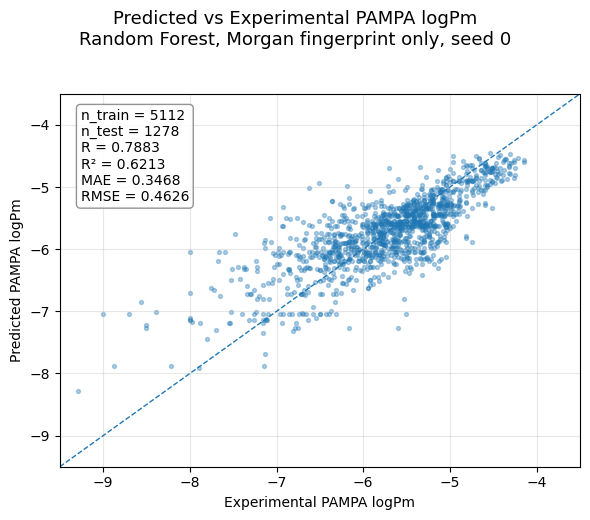

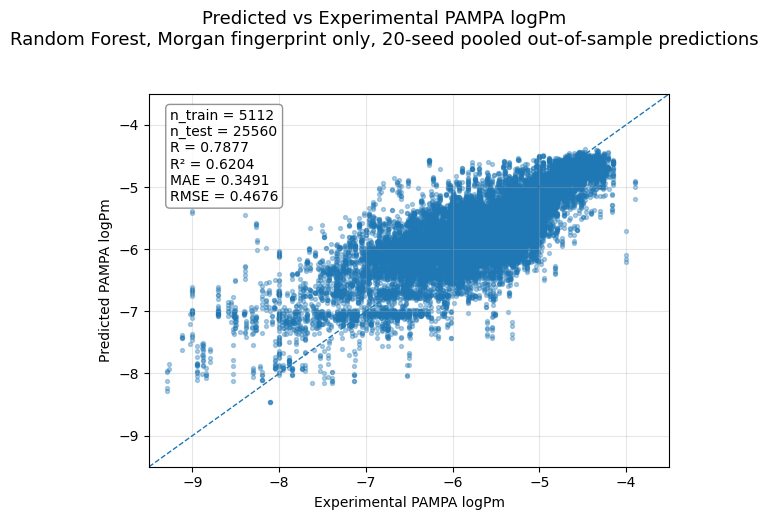

Saved figures:
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_seed0.png
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_seed0.pdf
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_20seeds_pooled.png
/Users/teraimao/experiment/data/解析結果/morgan_fp_only_dedup_20seeds_pooled.pdf


In [23]:
# ============================================================
# Morgan fingerprint only 相関図作成
# ============================================================


from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

save_dir = "/Users/teraimao/experiment/data/解析結果"

pred_path = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_predictions.csv")
metrics_path = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_metrics_by_seed.csv")

pred_df = pd.read_csv(pred_path)
metrics_df = pd.read_csv(metrics_path)

def pearson_r(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

def metric_dict(y_true, y_pred):
    return {
        "R": pearson_r(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

def make_scatter_figure(plot_df, stats, out_png, out_pdf, title_suffix):
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))

    x_min = -9.5
    x_max = -3.5

    x = plot_df["Experimental_PAMPA_logPm"].values
    y = plot_df["Predicted_PAMPA_logPm"].values

    ax.scatter(x, y, s=8, alpha=0.35)
    ax.plot([x_min, x_max], [x_min, x_max], linestyle="--", linewidth=1)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(x_min, x_max)
    ax.grid(True, alpha=0.3)

    ax.set_xlabel("Experimental PAMPA logPm")
    ax.set_ylabel("Predicted PAMPA logPm")

    text = (
        f"n_train = {int(stats['N_train'])}\n"
        f"n_test = {int(stats['N_test'])}\n"
        f"R = {stats['R']:.4f}\n"
        f"R² = {stats['R2']:.4f}\n"
        f"MAE = {stats['MAE']:.4f}\n"
        f"RMSE = {stats['RMSE']:.4f}"
    )

    ax.text(
        0.04, 0.96, text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"),
    )

    fig.suptitle(
        "Predicted vs Experimental PAMPA logPm\n"
        f"Random Forest, Morgan fingerprint only, {title_suffix}",
        fontsize=13,
        y=1.03,
    )

    fig.tight_layout()
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    plt.show()

# =========================
# seed 0 図
# =========================

seed0_pred = pred_df[pred_df["Seed"] == 0].copy()
seed0_stats = metrics_df[metrics_df["Seed"] == 0].iloc[0].to_dict()

seed0_png = os.path.join(save_dir, "morgan_fp_only_dedup_seed0.png")
seed0_pdf = os.path.join(save_dir, "morgan_fp_only_dedup_seed0.pdf")

make_scatter_figure(
    seed0_pred,
    seed0_stats,
    seed0_png,
    seed0_pdf,
    "seed 0"
)

# =========================
# 20 seeds pooled 図
# =========================

pooled_stats = metric_dict(
    pred_df["Experimental_PAMPA_logPm"].values,
    pred_df["Predicted_PAMPA_logPm"].values,
)

pooled_stats["N_train"] = int(metrics_df["N_train"].iloc[0])
pooled_stats["N_test"] = len(pred_df)

pooled_png = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_pooled.png")
pooled_pdf = os.path.join(save_dir, "morgan_fp_only_dedup_20seeds_pooled.pdf")

make_scatter_figure(
    pred_df,
    pooled_stats,
    pooled_png,
    pooled_pdf,
    "20-seed pooled out-of-sample predictions"
)

print("Saved figures:")
print(seed0_png)
print(seed0_pdf)
print(pooled_png)
print(pooled_pdf)

## morgan+fullMD35

In [24]:
# =========================
# 0. import
# =========================



# =========================
# 1. 設定
# =========================
save_dir = "/Users/teraimao/experiment/data/解析結果"
out_dir = os.path.join(save_dir, "morgan_plus_fullMD35_results")
os.makedirs(out_dir, exist_ok=True)

target_col = "PAMPA_logPm"
id_col = "ID"
smiles_col = "SMILES"

model_order = ["gbsw", "hdgb", "hdgbvdw"]

files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
}

seeds = list(range(20))

rf_base_params = {
    "n_estimators": 500,
    "n_jobs": -1,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
}

fp_radius = 2
fp_nbits = 2048


# =========================
# 2. FULL_MD35 の列定義
# =========================
base_feature_names = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
    "PSA3D_Avg",
    "NPSA3D_Avg",
]

def make_pos_cols(feature_names, positions=(1, 2, 3, 4, 5)):
    cols = []
    for feat in feature_names:
        for pos in positions:
            cols.append(f"{feat}_pos{pos}")
    return cols

full_md35_cols = make_pos_cols(base_feature_names)


# =========================
# 3. Morgan fingerprint 作成関数
# =========================
def smiles_to_morgan_array(smiles, radius=2, nbits=2048):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits)
    arr = np.zeros((nbits,), dtype=np.int8)
    # RDKit bitvect → numpy
    for i in fp.GetOnBits():
        arr[i] = 1
    return arr

def pearson_r(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if len(y_true) < 2:
        return np.nan
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]


# =========================
# 4. データ読み込み + Morgan作成
# =========================
data_by_model = {}
usable_id_sets = []

for model in model_order:
    path = os.path.join(save_dir, files[model])
    df = pd.read_csv(path)

    print("\n" + "="*80)
    print(model)
    print("path:", path)
    print("input shape:", df.shape)

    # 必須列確認
    need_cols = [id_col, target_col, smiles_col] + full_md35_cols
    missing = [c for c in need_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{model}: missing columns: {missing}")

    # 必須列の欠損除去
    df = df.dropna(subset=[id_col, target_col, smiles_col] + full_md35_cols).copy()
    df[id_col] = df[id_col].astype(int)

    print("after dropna:", df.shape)
    print("unique IDs:", df[id_col].nunique())

    # Morgan fingerprint 作成
    fp_rows = []
    valid_idx = []

    for idx, smi in zip(df.index, df[smiles_col]):
        arr = smiles_to_morgan_array(smi, radius=fp_radius, nbits=fp_nbits)
        if arr is not None:
            fp_rows.append(arr)
            valid_idx.append(idx)

    df = df.loc[valid_idx].copy().reset_index(drop=True)
    fp_mat = np.array(fp_rows, dtype=np.int8)

    fp_cols = [f"FP_{i}" for i in range(fp_nbits)]
    fp_df = pd.DataFrame(fp_mat, columns=fp_cols)

    df = pd.concat([df.reset_index(drop=True), fp_df], axis=1)

    print("after Morgan valid filter:", df.shape)
    print("unique IDs:", df[id_col].nunique())

    # 保存
    data_by_model[model] = df
    usable_id_sets.append(set(df[id_col].unique()))

# 3モデル公平比較のため共通IDに限定
common_ids = sorted(set.intersection(*usable_id_sets))
print("\n" + "="*80)
print("common usable IDs across 3 models:", len(common_ids))

for model in model_order:
    df = data_by_model[model]
    df = df[df[id_col].isin(common_ids)].copy().sort_values(id_col).reset_index(drop=True)
    data_by_model[model] = df
    print(model, df.shape)


# =========================
# 5. 特徴量セット
# =========================
fp_cols = [f"FP_{i}" for i in range(fp_nbits)]

feature_sets = {
    "FULL_MD35": full_md35_cols,
    "MorganFP_only": fp_cols,
    "MorganFP_plus_FULL_MD35": fp_cols + full_md35_cols,
}

feature_order = list(feature_sets.keys())


# =========================
# 6. 20 seeds 実行
# =========================
rows_metrics = []
rows_pred = []

all_ids = np.array(common_ids)

total_runs = len(seeds) * len(model_order) * len(feature_sets)
run_count = 0

for seed in seeds:
    print("\n" + "="*80)
    print("seed:", seed)

    train_ids, test_ids = train_test_split(
        all_ids,
        test_size=0.2,
        random_state=seed,
        shuffle=True,
    )
    train_ids = set(train_ids)
    test_ids = set(test_ids)

    print("n train IDs:", len(train_ids))
    print("n test  IDs:", len(test_ids))

    for model in model_order:
        print(f"\nModel: {model}")

        df = data_by_model[model]

        train_mask = df[id_col].isin(train_ids)
        test_mask = df[id_col].isin(test_ids)

        y_train = df.loc[train_mask, target_col].values
        y_test = df.loc[test_mask, target_col].values
        test_ids_arr = df.loc[test_mask, id_col].values

        for set_name in feature_order:
            run_count += 1
            cols = feature_sets[set_name]

            print(f"  [{run_count}/{total_runs}] {set_name} ({len(cols)} features)")

            X_train = df.loc[train_mask, cols].values
            X_test = df.loc[test_mask, cols].values

            rf = RandomForestRegressor(
                **rf_base_params,
                random_state=seed,
            )
            rf.fit(X_train, y_train)
            pred = rf.predict(X_test)

            r = pearson_r(y_test, pred)
            r2 = r2_score(y_test, pred)
            mae = mean_absolute_error(y_test, pred)
            rmse = np.sqrt(mean_squared_error(y_test, pred))

            rows_metrics.append({
                "Seed": seed,
                "Model": model,
                "Feature_Set": set_name,
                "N_train": len(y_train),
                "N_test": len(y_test),
                "N_features": len(cols),
                "R": r,
                "R2": r2,
                "MAE": mae,
                "RMSE": rmse,
            })

            tmp_pred = pd.DataFrame({
                "Seed": seed,
                "Model": model,
                "Feature_Set": set_name,
                "ID": test_ids_arr,
                "Observed": y_test,
                "Predicted": pred,
            })
            rows_pred.append(tmp_pred)

            print(f"    R={r:.4f}, R2={r2:.4f}, MAE={mae:.4f}, RMSE={rmse:.4f}")

# DataFrame化
metrics_raw = pd.DataFrame(rows_metrics)
pred_raw = pd.concat(rows_pred, axis=0, ignore_index=True)

print("\nmetrics_raw:", metrics_raw.shape)
print("pred_raw   :", pred_raw.shape)


# =========================
# 7. 平均 ± SD 集計
# =========================
summary = (
    metrics_raw
    .groupby(["Model", "Feature_Set", "N_features"], as_index=False)
    .agg(
        R_mean=("R", "mean"),
        R_sd=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_sd=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_sd=("RMSE", "std"),
    )
)

summary["Model"] = pd.Categorical(summary["Model"], categories=model_order, ordered=True)
summary["Feature_Set"] = pd.Categorical(summary["Feature_Set"], categories=feature_order, ordered=True)
summary = summary.sort_values(["Model", "Feature_Set"]).reset_index(drop=True)

# 見やすい表示用
summary_view = summary.copy()
for c_mean, c_sd, newcol in [
    ("R_mean", "R_sd", "R_mean±sd"),
    ("R2_mean", "R2_sd", "R2_mean±sd"),
    ("MAE_mean", "MAE_sd", "MAE_mean±sd"),
    ("RMSE_mean", "RMSE_sd", "RMSE_mean±sd"),
]:
    summary_view[newcol] = summary_view.apply(
        lambda x: f"{x[c_mean]:.4f} ± {x[c_sd]:.4f}", axis=1
    )

summary_view = summary_view[
    ["Model", "Feature_Set", "N_features", "R_mean±sd", "R2_mean±sd", "MAE_mean±sd", "RMSE_mean±sd"]
]


# =========================
# 8. 保存
# =========================
raw_out = os.path.join(out_dir, "morgan_plus_fullMD35_20seeds_metrics_by_seed.csv")
summary_out = os.path.join(out_dir, "morgan_plus_fullMD35_20seeds_summary.csv")
summary_view_out = os.path.join(out_dir, "morgan_plus_fullMD35_20seeds_summary_view.csv")
pred_out = os.path.join(out_dir, "morgan_plus_fullMD35_20seeds_predictions.csv")

metrics_raw.to_csv(raw_out, index=False)
summary.to_csv(summary_out, index=False)
summary_view.to_csv(summary_view_out, index=False)
pred_raw.to_csv(pred_out, index=False)

print("\nSaved:")
print(raw_out)
print(summary_out)
print(summary_view_out)
print(pred_out)

print("\nSummary:")
print(summary_view.to_string(index=False))


# =========================
# 9. 相関図作成
#    各モデルごとに
#    - seed0
#    - 20 seeds pooled
# =========================
plot_feature = "MorganFP_plus_FULL_MD35"

for model in model_order:
    # -------- seed0 --------
    d0 = pred_raw[
        (pred_raw["Model"] == model) &
        (pred_raw["Feature_Set"] == plot_feature) &
        (pred_raw["Seed"] == 0)
    ].copy()

    r0 = pearson_r(d0["Observed"], d0["Predicted"])
    r20 = r2_score(d0["Observed"], d0["Predicted"])
    mae0 = mean_absolute_error(d0["Observed"], d0["Predicted"])
    rmse0 = np.sqrt(mean_squared_error(d0["Observed"], d0["Predicted"]))

    vmin = min(d0["Observed"].min(), d0["Predicted"].min())
    vmax = max(d0["Observed"].max(), d0["Predicted"].max())

    plt.figure(figsize=(6, 6))
    plt.scatter(d0["Observed"], d0["Predicted"], alpha=0.6)
    plt.plot([vmin, vmax], [vmin, vmax], linestyle="--")
    plt.xlabel("Observed PAMPA logPm")
    plt.ylabel("Predicted PAMPA logPm")
    plt.title(f"{model} | {plot_feature} | seed 0")
    plt.text(
        0.05, 0.95,
        f"R = {r0:.4f}\nR² = {r20:.4f}\nMAE = {mae0:.4f}\nRMSE = {rmse0:.4f}",
        transform=plt.gca().transAxes,
        va="top"
    )
    plt.tight_layout()

    seed0_png = os.path.join(out_dir, f"{model}_morgan_plus_fullMD35_seed0.png")
    seed0_pdf = os.path.join(out_dir, f"{model}_morgan_plus_fullMD35_seed0.pdf")
    plt.savefig(seed0_png, dpi=300, bbox_inches="tight")
    plt.savefig(seed0_pdf, bbox_inches="tight")
    plt.close()

    # -------- pooled --------
    dp = pred_raw[
        (pred_raw["Model"] == model) &
        (pred_raw["Feature_Set"] == plot_feature)
    ].copy()

    rp = pearson_r(dp["Observed"], dp["Predicted"])
    r2p = r2_score(dp["Observed"], dp["Predicted"])
    maep = mean_absolute_error(dp["Observed"], dp["Predicted"])
    rmsep = np.sqrt(mean_squared_error(dp["Observed"], dp["Predicted"]))

    vmin = min(dp["Observed"].min(), dp["Predicted"].min())
    vmax = max(dp["Observed"].max(), dp["Predicted"].max())

    plt.figure(figsize=(6, 6))
    plt.scatter(dp["Observed"], dp["Predicted"], alpha=0.25)
    plt.plot([vmin, vmax], [vmin, vmax], linestyle="--")
    plt.xlabel("Observed PAMPA logPm")
    plt.ylabel("Predicted PAMPA logPm")
    plt.title(f"{model} | {plot_feature} | pooled 20 seeds")
    plt.text(
        0.05, 0.95,
        f"R = {rp:.4f}\nR² = {r2p:.4f}\nMAE = {maep:.4f}\nRMSE = {rmsep:.4f}",
        transform=plt.gca().transAxes,
        va="top"
    )
    plt.tight_layout()

    pooled_png = os.path.join(out_dir, f"{model}_morgan_plus_fullMD35_pooled20seeds.png")
    pooled_pdf = os.path.join(out_dir, f"{model}_morgan_plus_fullMD35_pooled20seeds.pdf")
    plt.savefig(pooled_png, dpi=300, bbox_inches="tight")
    plt.savefig(pooled_pdf, bbox_inches="tight")
    plt.close()

print("\nAll plots saved in:")
print(out_dir)


gbsw
path: /Users/teraimao/experiment/data/解析結果/gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv
input shape: (6390, 222)
after dropna: (6390, 222)
unique IDs: 6390


[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerator
[14:53:16] DEPRECATION WARNING: please use MorganGenerat

after Morgan valid filter: (6390, 2270)
unique IDs: 6390

hdgb
path: /Users/teraimao/experiment/data/解析結果/hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv
input shape: (6390, 222)
after dropna: (6390, 222)
unique IDs: 6390


[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerator
[14:53:18] DEPRECATION WARNING: please use MorganGenerat

after Morgan valid filter: (6390, 2270)
unique IDs: 6390

hdgbvdw
path: /Users/teraimao/experiment/data/解析結果/hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv
input shape: (6390, 222)
after dropna: (6390, 222)
unique IDs: 6390


[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerator
[14:53:19] DEPRECATION WARNING: please use MorganGenerat

after Morgan valid filter: (6390, 2270)
unique IDs: 6390

common usable IDs across 3 models: 6390
gbsw (6390, 2270)
hdgb (6390, 2270)
hdgbvdw (6390, 2270)

seed: 0
n train IDs: 5112
n test  IDs: 1278

Model: gbsw
  [1/180] FULL_MD35 (35 features)
    R=0.6934, R2=0.4649, MAE=0.4237, RMSE=0.5498
  [2/180] MorganFP_only (2048 features)
    R=0.7883, R2=0.6213, MAE=0.3468, RMSE=0.4626
  [3/180] MorganFP_plus_FULL_MD35 (2083 features)
    R=0.7922, R2=0.6163, MAE=0.3531, RMSE=0.4656

Model: hdgb
  [4/180] FULL_MD35 (35 features)
    R=0.6817, R2=0.4496, MAE=0.4311, RMSE=0.5576
  [5/180] MorganFP_only (2048 features)
    R=0.7883, R2=0.6213, MAE=0.3468, RMSE=0.4626
  [6/180] MorganFP_plus_FULL_MD35 (2083 features)
    R=0.7937, R2=0.6180, MAE=0.3521, RMSE=0.4646

Model: hdgbvdw
  [7/180] FULL_MD35 (35 features)
    R=0.6884, R2=0.4576, MAE=0.4261, RMSE=0.5536
  [8/180] MorganFP_only (2048 features)
    R=0.7883, R2=0.6213, MAE=0.3468, RMSE=0.4626
  [9/180] MorganFP_plus_FULL_MD35 (2083 feat

## morgan + 一部欠けたmD

FULL_MD35 columns: 35
['HB', 'SASA', 'Solv_Free', 'vdW', 'Coul', 'PSA3D', 'NPSA3D']

gbsw
input: (6390, 222)
usable: (6390, 222)

hdgb
input: (6390, 222)
usable: (6390, 222)

hdgbvdw
input: (6390, 222)
usable: (6390, 222)

common IDs across 3 models before SMILES: 6390
SMILES found in psa3d csv: SMILES

Computing Morgan fingerprints...


[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerator
[15:19:00] DEPRECATION WARNING: please use MorganGenerat

Morgan FP matrix: (6390, 2048)
final common IDs: 6390

Feature sets:
Morgan_only
Morgan+FULL_MD35
Morgan+drop1_HB
Morgan+drop1_SASA
Morgan+drop1_Solv_Free
Morgan+drop1_vdW
Morgan+drop1_Coul
Morgan+drop1_PSA3D
Morgan+drop1_NPSA3D

seed: 0
n_train: 5112
n_test: 1278

Model: gbsw
[1/27] gbsw | Morgan_only | 2048 features
  R=0.7883, R2=0.6213, MAE=0.3468, RMSE=0.4626, time=3.5s
[2/27] gbsw | Morgan+FULL_MD35 | 2083 features
  R=0.7922, R2=0.6163, MAE=0.3531, RMSE=0.4656, time=2.5s
[3/27] gbsw | Morgan+drop1_HB | 2078 features
  R=0.7930, R2=0.6196, MAE=0.3501, RMSE=0.4636, time=2.3s
[4/27] gbsw | Morgan+drop1_SASA | 2078 features
  R=0.7930, R2=0.6187, MAE=0.3512, RMSE=0.4642, time=1.9s
[5/27] gbsw | Morgan+drop1_Solv_Free | 2078 features
  R=0.7929, R2=0.6194, MAE=0.3507, RMSE=0.4637, time=1.8s
[6/27] gbsw | Morgan+drop1_vdW | 2078 features
  R=0.7919, R2=0.6156, MAE=0.3516, RMSE=0.4660, time=2.1s
[7/27] gbsw | Morgan+drop1_Coul | 2078 features
  R=0.7939, R2=0.6186, MAE=0.3523, RMSE=0.4

,Model,Feature_Set,N_features,R,R2,MAE,RMSE,Delta_R2_vs_Morgan,Delta_MAE_vs_Morgan,Delta_RMSE_vs_Morgan
0,gbsw,Morgan_only,2048,0.788297,0.621262,0.346825,0.462574,0.000000,0.000000,0.000000
1,gbsw,Morgan+drop1_HB,2078,0.793029,0.619559,0.350072,0.463613,-0.001702,0.003247,0.001038
2,gbsw,Morgan+drop1_Solv_Free,2078,0.792890,0.619409,0.350658,0.463704,-0.001853,0.003834,0.001130
3,gbsw,Morgan+drop1_SASA,2078,0.793035,0.618656,0.351160,0.464163,-0.002606,0.004335,0.001589
4,gbsw,Morgan+drop1_Coul,2078,0.793870,0.618587,0.352337,0.464205,-0.002675,0.005513,0.001631
5,gbsw,Morgan+FULL_MD35,2083,0.792174,0.616308,0.353145,0.465590,-0.004954,0.006321,0.003016
6,gbsw,Morgan+drop1_vdW,2078,0.791873,0.615570,0.351650,0.466037,-0.005692,0.004825,0.003463
7,gbsw,Morgan+drop1_NPSA3D,2078,0.790635,0.615525,0.353005,0.466065,-0.005737,0.006180,0.003490
8,gbsw,Morgan+drop1_PSA3D,2078,0.788936,0.613286,0.354526,0.467420,-0.007976,0.007701,0.004846
9,hdgb,Morgan+drop1_HB,2078,0.796900,0.624539,0.349430,0.460568,0.003278,0.002605,-0.002006


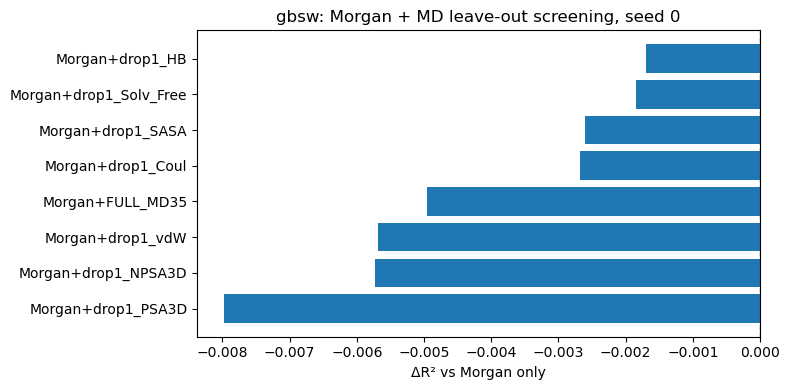

Saved figure: /Users/teraimao/experiment/data/解析結果/morgan_plus_MDleaveout_seed0_results/gbsw_morgan_plus_MDleaveout_seed0_deltaR2.png


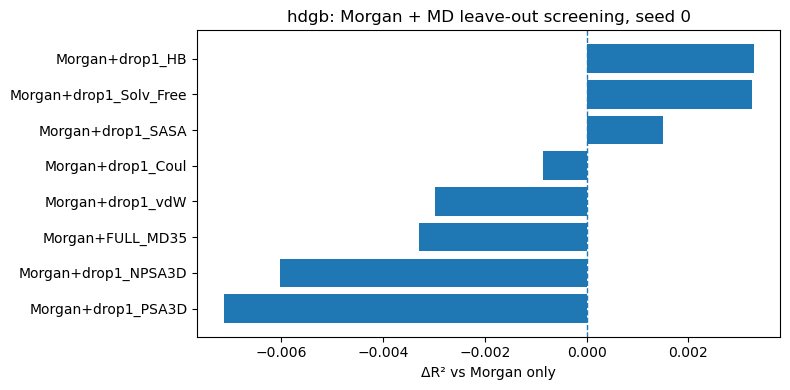

Saved figure: /Users/teraimao/experiment/data/解析結果/morgan_plus_MDleaveout_seed0_results/hdgb_morgan_plus_MDleaveout_seed0_deltaR2.png


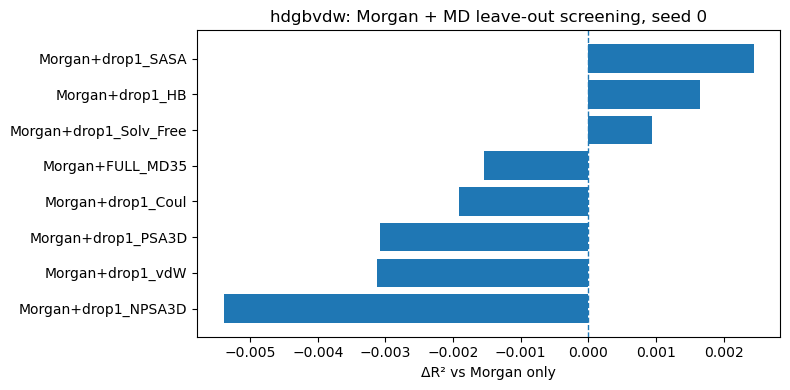

Saved figure: /Users/teraimao/experiment/data/解析結果/morgan_plus_MDleaveout_seed0_results/hdgbvdw_morgan_plus_MDleaveout_seed0_deltaR2.png


In [25]:
# ============================================================
# Morgan + MD leave-out screening
# seed 0 only
# Mac JupyterLab用
# ============================================================

# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"
cycpept_path = "/Users/teraimao/experiment/data/this_is_CycPeptMPDB.csv"

out_dir = os.path.join(save_dir, "morgan_plus_MDleaveout_seed0_results")
os.makedirs(out_dir, exist_ok=True)

id_col = "ID"
target_col = "PAMPA_logPm"

model_order = ["gbsw", "hdgb", "hdgbvdw"]

psa_files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
}

seed = 0

# 最初はFalse推奨。2個抜きもやるならTrue
include_drop2 = False

fp_radius = 2
fp_nbits = 2048

rf_base_params = {
    "n_estimators": 500,
    "n_jobs": -1,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
}

smiles_candidates = [
    "SMILES",
    "Smiles",
    "smiles",
    "Canonical_SMILES",
    "canonical_smiles",
    "CanonicalSmiles",
]

# =========================
# 関数
# =========================

def find_smiles_col(df):
    for c in smiles_candidates:
        if c in df.columns:
            return c
    return None

def pos_cols(prefix):
    return [f"{prefix}_pos{i}" for i in [1, 2, 3, 4, 5]]

def smiles_to_morgan_array(smiles, radius=2, nbits=2048):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=nbits,
    )

    arr = np.zeros((nbits,), dtype=np.int8)
    for i in fp.GetOnBits():
        arr[i] = 1

    return arr

def pearson_r(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan

    return np.corrcoef(y_true, y_pred)[0, 1]

def metric_dict(y_true, y_pred):
    return {
        "R": pearson_r(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

# =========================
# MD特徴量グループ定義
# =========================

feature_groups = {
    "HB": pos_cols("HB_Avg"),
    "SASA": pos_cols("SASA_Avg"),
    "Solv_Free": pos_cols("Solv_Free_Avg"),
    "vdW": pos_cols("vdW_Avg"),
    "Coul": pos_cols("Coul_Avg"),
    "PSA3D": pos_cols("PSA3D_Avg"),
    "NPSA3D": pos_cols("NPSA3D_Avg"),
}

group_order = list(feature_groups.keys())

full_md35_cols = []
for g in group_order:
    full_md35_cols += feature_groups[g]

print("FULL_MD35 columns:", len(full_md35_cols))
print(group_order)

# =========================
# データ読み込み
# =========================

data_by_model = {}
id_sets = []

for model in model_order:
    path = os.path.join(save_dir, psa_files[model])
    df = pd.read_csv(path, low_memory=False)

    print("\n" + "=" * 80)
    print(model)
    print("input:", df.shape)

    needed = [id_col, target_col] + full_md35_cols
    missing = [c for c in needed if c not in df.columns]

    if missing:
        raise ValueError(f"{model}: missing columns: {missing}")

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

    for c in full_md35_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=[id_col, target_col] + full_md35_cols).copy()
    df[id_col] = df[id_col].astype(int)

    if df[id_col].duplicated().sum() > 0:
        df = df.drop_duplicates(subset=[id_col], keep="first").copy()

    data_by_model[model] = df
    id_sets.append(set(df[id_col].tolist()))

    print("usable:", df.shape)

common_ids = sorted(set.intersection(*id_sets))

print("\ncommon IDs across 3 models before SMILES:", len(common_ids))

# =========================
# SMILES取得
# =========================

base_df = data_by_model["gbsw"].copy()
base_df = base_df[base_df[id_col].isin(common_ids)].copy()

smiles_col = find_smiles_col(base_df)

if smiles_col is not None:
    print("SMILES found in psa3d csv:", smiles_col)
    smiles_df = base_df[[id_col, smiles_col]].copy()

else:
    print("SMILES not found in psa3d csv. Merge from this_is_CycPeptMPDB.csv")

    if not os.path.exists(cycpept_path):
        raise FileNotFoundError(f"this_is_CycPeptMPDB.csv が見つかりません: {cycpept_path}")

    cy = pd.read_csv(cycpept_path, low_memory=False)

    if id_col not in cy.columns:
        raise ValueError("CycPeptMPDBにID列がありません")

    smiles_col = find_smiles_col(cy)

    if smiles_col is None:
        print(list(cy.columns))
        raise ValueError("SMILES列が見つかりません")

    print("SMILES found in CycPeptMPDB:", smiles_col)

    cy[id_col] = pd.to_numeric(cy[id_col], errors="coerce")
    cy = cy.dropna(subset=[id_col]).copy()
    cy[id_col] = cy[id_col].astype(int)

    smiles_df = cy[[id_col, smiles_col]].copy()

smiles_df[smiles_col] = smiles_df[smiles_col].astype(str).str.strip()
smiles_df.loc[smiles_df[smiles_col].isin(["", "nan", "NaN", "None"]), smiles_col] = np.nan
smiles_df = smiles_df.dropna(subset=[smiles_col]).copy()

# =========================
# Morgan fingerprint作成
# =========================

print("\nComputing Morgan fingerprints...")

smiles_df = smiles_df[smiles_df[id_col].isin(common_ids)].copy()
smiles_df = smiles_df.drop_duplicates(subset=[id_col], keep="first").copy()
smiles_df = smiles_df.sort_values(id_col).reset_index(drop=True)

fp_rows = []
valid_ids = []
bad_rows = []

for _, row in smiles_df.iterrows():
    sid = int(row[id_col])
    smi = row[smiles_col]

    arr = smiles_to_morgan_array(smi, radius=fp_radius, nbits=fp_nbits)

    if arr is None:
        bad_rows.append({id_col: sid, smiles_col: smi})
    else:
        valid_ids.append(sid)
        fp_rows.append(arr)

if len(bad_rows) > 0:
    bad_df = pd.DataFrame(bad_rows)
    bad_out = os.path.join(out_dir, "bad_smiles.csv")
    bad_df.to_csv(bad_out, index=False)
    print("Bad SMILES:", len(bad_df))
    print("Saved:", bad_out)

fp_matrix = np.vstack(fp_rows).astype(np.float32)
fp_ids = np.array(valid_ids, dtype=int)

print("Morgan FP matrix:", fp_matrix.shape)

# final common IDs
common_ids = sorted(set(common_ids) & set(fp_ids.tolist()))
print("final common IDs:", len(common_ids))

# fpをID順に揃える
fp_df = pd.DataFrame(fp_matrix)
fp_df[id_col] = fp_ids
fp_df = fp_df[fp_df[id_col].isin(common_ids)].copy()
fp_df = fp_df.sort_values(id_col).reset_index(drop=True)

fp_matrix = fp_df.drop(columns=[id_col]).values.astype(np.float32)
aligned_ids = fp_df[id_col].values.astype(int)

# =========================
# 特徴量セット作成
# =========================

md_feature_sets = {}

# FULL
full_groups = group_order.copy()
md_feature_sets["FULL_MD35"] = full_groups

# 1個抜き
for g in group_order:
    keep_groups = [x for x in group_order if x != g]
    md_feature_sets[f"drop1_{g}"] = keep_groups

# 2個抜き optional
if include_drop2:
    for g1, g2 in itertools.combinations(group_order, 2):
        keep_groups = [x for x in group_order if x not in [g1, g2]]
        md_feature_sets[f"drop2_{g1}+{g2}"] = keep_groups

feature_order = ["Morgan_only"] + [f"Morgan+{k}" for k in md_feature_sets.keys()]

print("\nFeature sets:")
for f in feature_order:
    print(f)

# =========================
# seed 0 split
# =========================

train_ids, test_ids = train_test_split(
    aligned_ids,
    test_size=0.2,
    random_state=seed,
    shuffle=True,
)

train_ids = set(train_ids)
test_ids = set(test_ids)

fp_train_mask = np.array([i in train_ids for i in aligned_ids])
fp_test_mask = np.array([i in test_ids for i in aligned_ids])

Xfp_train = fp_matrix[fp_train_mask]
Xfp_test = fp_matrix[fp_test_mask]

ids_train = aligned_ids[fp_train_mask]
ids_test = aligned_ids[fp_test_mask]

print("\nseed:", seed)
print("n_train:", len(ids_train))
print("n_test:", len(ids_test))

# =========================
# 学習・評価
# =========================

metric_rows = []
pred_rows = []

total_runs = len(model_order) * len(feature_order)
run_count = 0
start = time.time()

for model in model_order:
    print("\n" + "=" * 80)
    print("Model:", model)

    df = data_by_model[model].copy()
    df = df[df[id_col].isin(common_ids)].copy()
    df = df.sort_values(id_col).reset_index(drop=True)

    # ID順がfpと一致しているか確認
    if not np.array_equal(df[id_col].values.astype(int), aligned_ids):
        raise ValueError(f"{model}: ID order mismatch")

    y_all = df[target_col].values.astype(float)

    y_train = y_all[fp_train_mask]
    y_test = y_all[fp_test_mask]

    for feature_name in feature_order:
        run_count += 1
        t0 = time.time()

        if feature_name == "Morgan_only":
            X_train = Xfp_train
            X_test = Xfp_test
            n_features = fp_nbits

        else:
            md_name = feature_name.replace("Morgan+", "")
            keep_groups = md_feature_sets[md_name]

            md_cols = []
            for g in keep_groups:
                md_cols += feature_groups[g]

            Xmd_all = df[md_cols].values.astype(np.float32)

            Xmd_train = Xmd_all[fp_train_mask]
            Xmd_test = Xmd_all[fp_test_mask]

            X_train = np.hstack([Xfp_train, Xmd_train])
            X_test = np.hstack([Xfp_test, Xmd_test])
            n_features = X_train.shape[1]

        print(f"[{run_count}/{total_runs}] {model} | {feature_name} | {n_features} features")

        rf = RandomForestRegressor(
            **rf_base_params,
            random_state=seed,
        )

        rf.fit(X_train, y_train)
        pred = rf.predict(X_test)

        m = metric_dict(y_test, pred)

        metric_rows.append({
            "Seed": seed,
            "Model": model,
            "Feature_Set": feature_name,
            "N_train": len(y_train),
            "N_test": len(y_test),
            "N_features": n_features,
            **m,
            "Time_sec": time.time() - t0,
        })

        for i, yt, yp in zip(ids_test, y_test, pred):
            pred_rows.append({
                "Seed": seed,
                "Model": model,
                "Feature_Set": feature_name,
                "ID": int(i),
                "Observed": float(yt),
                "Predicted": float(yp),
            })

        print(
            f"  R={m['R']:.4f}, R2={m['R2']:.4f}, "
            f"MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}, "
            f"time={time.time() - t0:.1f}s"
        )

metrics = pd.DataFrame(metric_rows)
predictions = pd.DataFrame(pred_rows)

# =========================
# Morgan_onlyからの差分
# =========================

base = metrics[metrics["Feature_Set"] == "Morgan_only"][
    ["Model", "R", "R2", "MAE", "RMSE"]
].rename(columns={
    "R": "R_Morgan",
    "R2": "R2_Morgan",
    "MAE": "MAE_Morgan",
    "RMSE": "RMSE_Morgan",
})

delta = metrics.merge(base, on="Model", how="left")

delta["Delta_R_vs_Morgan"] = delta["R"] - delta["R_Morgan"]
delta["Delta_R2_vs_Morgan"] = delta["R2"] - delta["R2_Morgan"]
delta["Delta_MAE_vs_Morgan"] = delta["MAE"] - delta["MAE_Morgan"]
delta["Delta_RMSE_vs_Morgan"] = delta["RMSE"] - delta["RMSE_Morgan"]

delta_sorted = delta.sort_values(["Model", "Delta_R2_vs_Morgan"], ascending=[True, False]).reset_index(drop=True)

# =========================
# 保存
# =========================

metrics_out = os.path.join(out_dir, "morgan_plus_MDleaveout_seed0_metrics.csv")
delta_out = os.path.join(out_dir, "morgan_plus_MDleaveout_seed0_delta_vs_Morgan.csv")
pred_out = os.path.join(out_dir, "morgan_plus_MDleaveout_seed0_predictions.csv")

metrics.to_csv(metrics_out, index=False)
delta_sorted.to_csv(delta_out, index=False)
predictions.to_csv(pred_out, index=False)

print("\nSaved:")
print(metrics_out)
print(delta_out)
print(pred_out)

print("\nTotal time:", round((time.time() - start) / 60, 1), "min")

# =========================
# 表示
# =========================

display_cols = [
    "Model",
    "Feature_Set",
    "N_features",
    "R",
    "R2",
    "MAE",
    "RMSE",
    "Delta_R2_vs_Morgan",
    "Delta_MAE_vs_Morgan",
    "Delta_RMSE_vs_Morgan",
]

display(delta_sorted[display_cols])

# =========================
# 各モデルのΔR2棒グラフ
# =========================

for model in model_order:
    sub = delta_sorted[
        (delta_sorted["Model"] == model) &
        (delta_sorted["Feature_Set"] != "Morgan_only")
    ].copy()

    sub = sub.sort_values("Delta_R2_vs_Morgan", ascending=True)

    plt.figure(figsize=(8, max(4, 0.35 * len(sub))))
    plt.barh(sub["Feature_Set"], sub["Delta_R2_vs_Morgan"])
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.xlabel("ΔR² vs Morgan only")
    plt.title(f"{model}: Morgan + MD leave-out screening, seed {seed}")
    plt.tight_layout()

    fig_out = os.path.join(out_dir, f"{model}_morgan_plus_MDleaveout_seed0_deltaR2.png")
    plt.savefig(fig_out, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved figure:", fig_out)

## morgan MDの割合を増やしていく

Common IDs: 6390
Morgan shape: (6390, 2048)
Train: 5112
Test: 1278
Morgan_only | sqrt  | R2=0.6223 | MAE=0.3464 | Time=3.2s
gbsw       | sqrt  | R2=0.6193 | MAE=0.3518 | Time=2.9s
gbsw       | 0.1   | R2=0.6177 | MAE=0.3498 | Time=5.8s
gbsw       | 0.3   | R2=0.6185 | MAE=0.3477 | Time=11.2s
gbsw       | 1.0   | R2=0.6036 | MAE=0.3527 | Time=26.0s
hdgb       | sqrt  | R2=0.6222 | MAE=0.3508 | Time=2.0s
hdgb       | 0.1   | R2=0.6244 | MAE=0.3477 | Time=6.3s
hdgb       | 0.3   | R2=0.6237 | MAE=0.3471 | Time=12.0s
hdgb       | 1.0   | R2=0.6126 | MAE=0.3495 | Time=30.8s
hdgbvdw    | sqrt  | R2=0.6179 | MAE=0.3521 | Time=2.9s
hdgbvdw    | 0.1   | R2=0.6250 | MAE=0.3466 | Time=6.9s
hdgbvdw    | 0.3   | R2=0.6140 | MAE=0.3497 | Time=12.5s
hdgbvdw    | 1.0   | R2=0.6038 | MAE=0.3513 | Time=32.0s

=== RESULTS ===


,Model,max_features,R2,MAE,RMSE,Delta_R2_vs_Morgan,Time_sec
0,hdgbvdw,0.1,0.6250,0.3466,0.4603,0.0028,6.9036
1,hdgb,0.1,0.6244,0.3477,0.4607,0.0021,6.3177
2,hdgb,0.3,0.6237,0.3471,0.4611,0.0014,12.0370
3,Morgan_only,sqrt,0.6223,0.3464,0.4620,0.0000,3.2421
4,hdgb,sqrt,0.6222,0.3508,0.4620,-0.0001,1.9990
5,gbsw,sqrt,0.6193,0.3518,0.4638,-0.0030,2.9454
6,gbsw,0.3,0.6185,0.3477,0.4643,-0.0038,11.1506
7,hdgbvdw,sqrt,0.6179,0.3521,0.4646,-0.0044,2.8918
8,gbsw,0.1,0.6177,0.3498,0.4647,-0.0046,5.7549
9,hdgbvdw,0.3,0.6140,0.3497,0.4670,-0.0083,12.4742


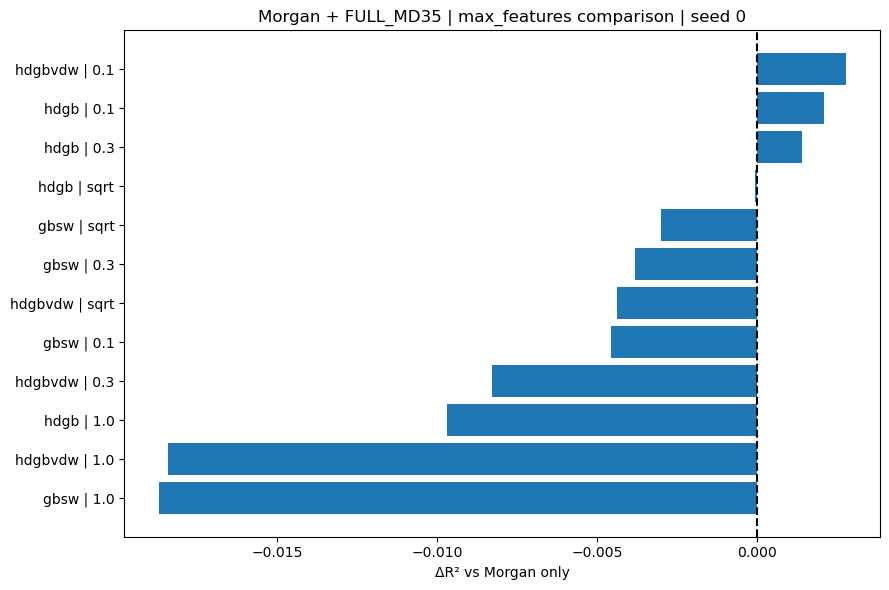


Saved to: /Users/teraimao/experiment/data/解析結果/morgan_fullMD35_maxfeatures_seed0


In [28]:
# ============================================================
# Morgan + FULL_MD35
# max_features 比較（seed 0のみ）
# Mac JupyterLab用
# ============================================================


# ------------------------------------------------------------
# 1. 設定
# ------------------------------------------------------------

base_dir = "/Users/teraimao/experiment/data/解析結果"

out_dir = os.path.join(
    base_dir, "morgan_fullMD35_maxfeatures_seed0"
)
os.makedirs(out_dir, exist_ok=True)

original_csv = (
    "/Users/teraimao/experiment/data/this_is_CycPeptMPDB.csv"
)

models = ["gbsw", "hdgb", "hdgbvdw"]

seed = 0
n_estimators = 500
n_bits = 2048

max_features_list = ["sqrt", 0.1, 0.3, 1.0]

groups = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
    "PSA3D_Avg",
    "NPSA3D_Avg",
]

md_cols = [
    f"{group}_pos{pos}"
    for group in groups
    for pos in range(1, 6)
]

assert len(md_cols) == 35

# ------------------------------------------------------------
# 2. データ読み込み
# ------------------------------------------------------------

data = {}

for model in models:

    path = os.path.join(
        base_dir,
        f"{model}_common_successID_baselineB_strictPAMPA_psa3d.csv"
    )

    df = pd.read_csv(path, low_memory=False)

    df["ID"] = pd.to_numeric(df["ID"], errors="coerce")
    df["PAMPA_logPm"] = pd.to_numeric(
        df["PAMPA_logPm"], errors="coerce"
    )

    for col in md_cols:
        if col not in df.columns:
            raise ValueError(f"{model}: Missing {col}")
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(
        subset=["ID", "PAMPA_logPm"] + md_cols
    ).copy()

    df["ID"] = df["ID"].astype(int)

    if df["ID"].duplicated().any():
        raise ValueError(f"{model}: Duplicate IDs detected")

    data[model] = df

# 3モデルの共通ID
common_ids = set(data["gbsw"]["ID"])

for model in models[1:]:
    common_ids &= set(data[model]["ID"])

# ------------------------------------------------------------
# 3. SMILES取得
# ------------------------------------------------------------

source = data["gbsw"]

smiles_candidates = [
    "SMILES", "Smiles", "smiles",
    "Canonical_SMILES", "canonical_smiles",
    "CanonicalSmiles"
]

smiles_col = next(
    (c for c in smiles_candidates if c in source.columns),
    None
)

if smiles_col is not None:
    smiles_df = source[["ID", smiles_col]].copy()
else:
    original = pd.read_csv(original_csv, low_memory=False)

    smiles_col = next(
        (c for c in smiles_candidates if c in original.columns),
        None
    )

    if smiles_col is None:
        raise ValueError("SMILES列が見つかりません")

    original["ID"] = pd.to_numeric(
        original["ID"], errors="coerce"
    )

    original = original.dropna(subset=["ID"]).copy()
    original["ID"] = original["ID"].astype(int)

    smiles_df = original[["ID", smiles_col]].copy()

smiles_df = smiles_df[
    smiles_df["ID"].isin(common_ids)
].drop_duplicates("ID")

# ------------------------------------------------------------
# 4. Morgan fingerprint
# ------------------------------------------------------------

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=n_bits
)

fp_by_id = {}

for row in smiles_df.itertuples(index=False, name=None):
    sid, smiles = row

    if pd.isna(smiles):
        continue

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        continue

    fp = generator.GetFingerprint(mol)

    arr = np.zeros(n_bits, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    fp_by_id[int(sid)] = arr

common_ids = sorted(common_ids & set(fp_by_id))

ids = np.array(common_ids)

X_fp = np.stack([
    fp_by_id[sid] for sid in ids
]).astype(np.float32)

print("Common IDs:", len(ids))
print("Morgan shape:", X_fp.shape)

if len(ids) != 6390:
    print(
        "注意: 以前の6390件と件数が異なります。"
        "比較時には対象IDを確認してください。"
    )

# ------------------------------------------------------------
# 5. 各モデルのMDデータ
# ------------------------------------------------------------

X_md = {}
y_by_model = {}

for model in models:

    df = data[model].set_index("ID").loc[ids]

    X_md[model] = df[md_cols].to_numpy(
        dtype=np.float32
    )

    y_by_model[model] = df["PAMPA_logPm"].to_numpy(
        dtype=float
    )

# ターゲットの一致確認
for model in models[1:]:
    if not np.allclose(
        y_by_model["gbsw"],
        y_by_model[model],
        rtol=0,
        atol=1e-10
    ):
        raise ValueError(
            f"{model}: PAMPA_logPm differs from GBSW"
        )

y = y_by_model["gbsw"]

# ------------------------------------------------------------
# 6. seed 0の分割
# ------------------------------------------------------------

train_idx, test_idx = train_test_split(
    np.arange(len(ids)),
    test_size=0.2,
    random_state=seed,
    shuffle=True
)

print("Train:", len(train_idx))
print("Test:", len(test_idx))

# ------------------------------------------------------------
# 7. 学習関数
# ------------------------------------------------------------

results = []
predictions = []

def run_rf(model, setting, X):

    start = time.time()

    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        max_features=setting,
        min_samples_leaf=1,
        random_state=seed,
        n_jobs=-1
    )

    rf.fit(X[train_idx], y[train_idx])

    pred = rf.predict(X[test_idx])
    obs = y[test_idx]

    r = np.corrcoef(obs, pred)[0, 1]
    r2 = r2_score(obs, pred)
    mae = mean_absolute_error(obs, pred)
    rmse = np.sqrt(mean_squared_error(obs, pred))

    label = str(setting)

    results.append({
        "Model": model,
        "max_features": label,
        "N_features": X.shape[1],
        "R": r,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Time_sec": time.time() - start
    })

    predictions.append(pd.DataFrame({
        "Model": model,
        "max_features": label,
        "ID": ids[test_idx],
        "Observed": obs,
        "Predicted": pred
    }))

    print(
        f"{model:10s} | {label:5s} | "
        f"R2={r2:.4f} | MAE={mae:.4f} | "
        f"Time={time.time()-start:.1f}s"
    )

    # 散布図
    fig, ax = plt.subplots(figsize=(6, 6))

    ax.scatter(
        obs, pred,
        s=18,
        alpha=0.5
    )

    lims = [
        min(obs.min(), pred.min()) - 0.1,
        max(obs.max(), pred.max()) + 0.1
    ]

    ax.plot(lims, lims, "--", color="gray")
    ax.set_xlim(lims)
    ax.set_ylim(lims)

    ax.set_xlabel("Observed PAMPA logPm")
    ax.set_ylabel("Predicted PAMPA logPm")

    ax.set_title(
        f"{model} | max_features={label} | seed 0"
    )

    ax.text(
        0.05, 0.95,
        f"R = {r:.4f}\n"
        f"R² = {r2:.4f}\n"
        f"MAE = {mae:.4f}\n"
        f"RMSE = {rmse:.4f}",
        transform=ax.transAxes,
        va="top"
    )

    fig.tight_layout()

    name = f"{model}_maxfeatures_{label}_seed0"

    fig.savefig(
        os.path.join(out_dir, name + ".png"),
        dpi=300
    )

    fig.savefig(
        os.path.join(out_dir, name + ".pdf")
    )

    plt.close(fig)

# ------------------------------------------------------------
# 8. Morgan only（基準）
# ------------------------------------------------------------

run_rf("Morgan_only", "sqrt", X_fp)

# ------------------------------------------------------------
# 9. Morgan + FULL_MD35
# ------------------------------------------------------------

for model in models:

    X = np.hstack([
        X_fp,
        X_md[model]
    ])

    assert X.shape[1] == 2083

    for setting in max_features_list:
        run_rf(model, setting, X)

        # 途中結果も保存
        pd.DataFrame(results).to_csv(
            os.path.join(out_dir, "metrics_progress.csv"),
            index=False
        )

# ------------------------------------------------------------
# 10. 結果保存
# ------------------------------------------------------------

metrics = pd.DataFrame(results)
pred_df = pd.concat(predictions, ignore_index=True)

baseline_r2 = metrics.loc[
    metrics["Model"] == "Morgan_only", "R2"
].iloc[0]

baseline_mae = metrics.loc[
    metrics["Model"] == "Morgan_only", "MAE"
].iloc[0]

metrics["Delta_R2_vs_Morgan"] = (
    metrics["R2"] - baseline_r2
)

metrics["Delta_MAE_vs_Morgan"] = (
    metrics["MAE"] - baseline_mae
)

metrics = metrics.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

metrics.to_csv(
    os.path.join(out_dir, "maxfeatures_seed0_metrics.csv"),
    index=False
)

pred_df.to_csv(
    os.path.join(out_dir, "maxfeatures_seed0_predictions.csv"),
    index=False
)

print("\n=== RESULTS ===")

display(
    metrics[
        [
            "Model",
            "max_features",
            "R2",
            "MAE",
            "RMSE",
            "Delta_R2_vs_Morgan",
            "Time_sec"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 11. ΔR² 比較グラフ
# ------------------------------------------------------------

plot_df = metrics[
    metrics["Model"] != "Morgan_only"
].copy()

plot_df["Label"] = (
    plot_df["Model"] +
    " | " +
    plot_df["max_features"]
)

plot_df = plot_df.sort_values(
    "Delta_R2_vs_Morgan"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_df["Label"],
    plot_df["Delta_R2_vs_Morgan"]
)

ax.axvline(0, color="black", linestyle="--")

ax.set_xlabel("ΔR² vs Morgan only")
ax.set_title(
    "Morgan + FULL_MD35 | max_features comparison | seed 0"
)

fig.tight_layout()

fig.savefig(
    os.path.join(out_dir, "maxfeatures_deltaR2.png"),
    dpi=300
)

plt.show()

print("\nSaved to:", out_dir)

## 重みつき平均　アンサンブル学習

Common IDs: 6390
Morgan: (6390, 2048)
Fit: 4089
Validation: 1023
Test: 1278

Training Morgan RF for validation...
Morgan validation R2: 0.56329957239483

Validation model: gbsw
Selected alpha=0.20, validation R2=0.5746

Validation model: hdgb
Selected alpha=0.20, validation R2=0.5738

Validation model: hdgbvdw
Selected alpha=0.20, validation R2=0.5768

Retraining on full outer train...

Final model: gbsw
alpha=0.20, R2=0.6276, MAE=0.3467

Final model: hdgb
alpha=0.20, R2=0.6267, MAE=0.3471

Final model: hdgbvdw
alpha=0.20, R2=0.6283, MAE=0.3461

=== TEST RESULTS ===


,Model,Alpha,R,R2,MAE,RMSE,Delta_R2_vs_Morgan,Delta_MAE_vs_Morgan
0,hdgbvdw_ensemble,0.2,0.7972,0.6283,0.3461,0.4582,0.0061,-0.0003
1,gbsw_ensemble,0.2,0.7963,0.6276,0.3467,0.4587,0.0053,0.0002
2,hdgb_ensemble,0.2,0.7960,0.6267,0.3471,0.4592,0.0045,0.0007
3,Morgan_only,0.0,0.7889,0.6223,0.3464,0.4620,0.0000,0.0000
4,gbsw_MD_only,1.0,0.6892,0.4603,0.4256,0.5522,-0.1620,0.0791
5,hdgbvdw_MD_only,1.0,0.6841,0.4524,0.4281,0.5562,-0.1698,0.0817
6,hdgb_MD_only,1.0,0.6821,0.4498,0.4310,0.5575,-0.1725,0.0846


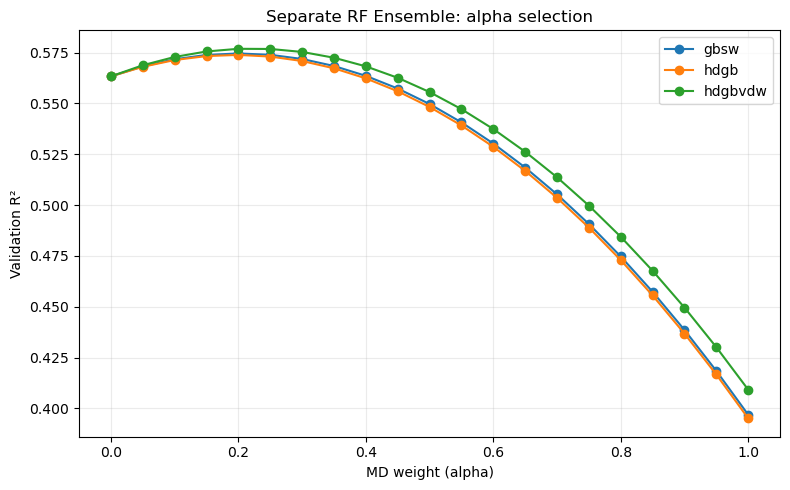


Total time: 0.4 minutes
Saved to: /Users/teraimao/experiment/data/解析結果/morgan_MD_separateRF_ensemble_seed0


In [29]:
# ============================================================
# Morgan + MD separate RF ensemble
# seed 0 / 3 models / Mac JupyterLab
# ============================================================

# ============================================================
# 1. 設定
# ============================================================

base_dir = "/Users/teraimao/experiment/data/解析結果"

out_dir = os.path.join(
    base_dir, "morgan_MD_separateRF_ensemble_seed0"
)
os.makedirs(out_dir, exist_ok=True)

original_csv = (
    "/Users/teraimao/experiment/data/this_is_CycPeptMPDB.csv"
)

models = ["gbsw", "hdgb", "hdgbvdw"]

seed = 0
n_estimators = 500
n_bits = 2048

# 0.0〜1.0を0.05刻みで検証
alphas = np.round(np.arange(0, 1.0001, 0.05), 2)

groups = [
    "HB_Avg",
    "SASA_Avg",
    "Solv_Free_Avg",
    "vdW_Avg",
    "Coul_Avg",
    "PSA3D_Avg",
    "NPSA3D_Avg",
]

md_cols = [
    f"{group}_pos{pos}"
    for group in groups
    for pos in range(1, 6)
]

assert len(md_cols) == 35

# ============================================================
# 2. データ読み込み
# ============================================================

data = {}

for model in models:

    path = os.path.join(
        base_dir,
        f"{model}_common_successID_baselineB_strictPAMPA_psa3d.csv"
    )

    df = pd.read_csv(path, low_memory=False)

    df["ID"] = pd.to_numeric(df["ID"], errors="coerce")
    df["PAMPA_logPm"] = pd.to_numeric(
        df["PAMPA_logPm"], errors="coerce"
    )

    for col in md_cols:
        if col not in df.columns:
            raise ValueError(f"{model}: Missing {col}")
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(
        subset=["ID", "PAMPA_logPm"] + md_cols
    ).copy()

    df["ID"] = df["ID"].astype(int)

    if df["ID"].duplicated().any():
        raise ValueError(f"{model}: Duplicate IDs detected")

    data[model] = df

common_ids = set(data["gbsw"]["ID"])

for model in models[1:]:
    common_ids &= set(data[model]["ID"])

# ============================================================
# 3. SMILES取得
# ============================================================

source = data["gbsw"]

smiles_candidates = [
    "SMILES", "Smiles", "smiles",
    "Canonical_SMILES", "canonical_smiles",
    "CanonicalSmiles"
]

smiles_col = next(
    (c for c in smiles_candidates if c in source.columns),
    None
)

if smiles_col is not None:
    smiles_df = source[["ID", smiles_col]].copy()
else:
    original = pd.read_csv(original_csv, low_memory=False)

    smiles_col = next(
        (c for c in smiles_candidates if c in original.columns),
        None
    )

    if smiles_col is None:
        raise ValueError("SMILES列が見つかりません")

    original["ID"] = pd.to_numeric(
        original["ID"], errors="coerce"
    )

    original = original.dropna(subset=["ID"]).copy()
    original["ID"] = original["ID"].astype(int)

    smiles_df = original[["ID", smiles_col]].copy()

smiles_df = smiles_df[
    smiles_df["ID"].isin(common_ids)
].drop_duplicates("ID")

# ============================================================
# 4. Morgan fingerprint
# ============================================================

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=n_bits
)

fp_by_id = {}

for sid, smiles in smiles_df[["ID", smiles_col]].itertuples(
    index=False, name=None
):
    if pd.isna(smiles):
        continue

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        continue

    fp = generator.GetFingerprint(mol)

    arr = np.zeros(n_bits, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    fp_by_id[int(sid)] = arr

common_ids = sorted(common_ids & set(fp_by_id))
ids = np.array(common_ids, dtype=int)

X_fp = np.stack([
    fp_by_id[sid] for sid in ids
]).astype(np.float32)

print("Common IDs:", len(ids))
print("Morgan:", X_fp.shape)

if len(ids) != 6390:
    print("注意: 以前の6390件とID数が異なります")

# ============================================================
# 5. MD特徴量とターゲット
# ============================================================

X_md = {}
y_by_model = {}

for model in models:

    df = data[model].set_index("ID").loc[ids]

    X_md[model] = df[md_cols].to_numpy(
        dtype=np.float32
    )

    y_by_model[model] = df["PAMPA_logPm"].to_numpy(
        dtype=float
    )

for model in models[1:]:
    if not np.allclose(
        y_by_model["gbsw"],
        y_by_model[model],
        atol=1e-10,
        rtol=0
    ):
        raise ValueError(
            f"{model}: target values differ"
        )

y = y_by_model["gbsw"]

# ============================================================
# 6. データ分割
#
# 外側: 80% train / 20% test
# 内側: trainの80% fit / 20% validation
#
# αはvalidationで決める
# testは最終評価のみに使う
# ============================================================

outer_train_idx, test_idx = train_test_split(
    np.arange(len(ids)),
    test_size=0.2,
    random_state=seed,
    shuffle=True
)

fit_idx, val_idx = train_test_split(
    outer_train_idx,
    test_size=0.2,
    random_state=seed + 1000,
    shuffle=True
)

print("Fit:", len(fit_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ============================================================
# 7. RF学習関数
# ============================================================

def fit_rf(X, train_indices, random_state):

    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        max_features="sqrt",
        min_samples_leaf=1,
        random_state=random_state,
        n_jobs=-1
    )

    rf.fit(
        X[train_indices],
        y[train_indices]
    )

    return rf


def evaluate(obs, pred):
    return {
        "R": np.corrcoef(obs, pred)[0, 1],
        "R2": r2_score(obs, pred),
        "MAE": mean_absolute_error(obs, pred),
        "RMSE": np.sqrt(mean_squared_error(obs, pred))
    }


def combine(fp_pred, md_pred, alpha):
    return (
        (1 - alpha) * fp_pred
        + alpha * md_pred
    )

# ============================================================
# 8. Validation用Morgan RF
# ============================================================

start = time.time()

print("\nTraining Morgan RF for validation...")

rf_fp_val = fit_rf(
    X_fp,
    fit_idx,
    random_state=seed
)

pred_fp_val = rf_fp_val.predict(
    X_fp[val_idx]
)

print("Morgan validation R2:",
      r2_score(y[val_idx], pred_fp_val))

# ============================================================
# 9. Validationで最適αを選択
# ============================================================

alpha_rows = []
selected_alphas = {}

for model in models:

    print("\n" + "=" * 60)
    print("Validation model:", model)

    rf_md_val = fit_rf(
        X_md[model],
        fit_idx,
        random_state=seed
    )

    pred_md_val = rf_md_val.predict(
        X_md[model][val_idx]
    )

    for alpha in alphas:

        pred = combine(
            pred_fp_val,
            pred_md_val,
            alpha
        )

        metrics = evaluate(
            y[val_idx], pred
        )

        alpha_rows.append({
            "Model": model,
            "Alpha": alpha,
            **metrics
        })

    sub = pd.DataFrame(
        [r for r in alpha_rows if r["Model"] == model]
    )

    # R2最大のα。並んだ場合は小さいαを優先
    best = sub.sort_values(
        ["R2", "Alpha"],
        ascending=[False, True]
    ).iloc[0]

    selected_alphas[model] = float(best["Alpha"])

    print(
        f"Selected alpha={best['Alpha']:.2f}, "
        f"validation R2={best['R2']:.4f}"
    )

alpha_df = pd.DataFrame(alpha_rows)

alpha_df.to_csv(
    os.path.join(out_dir, "validation_alpha_scores.csv"),
    index=False
)

# ============================================================
# 10. 全outer trainで再学習
# ============================================================

print("\nRetraining on full outer train...")

rf_fp_final = fit_rf(
    X_fp,
    outer_train_idx,
    random_state=seed
)

pred_fp_test = rf_fp_final.predict(
    X_fp[test_idx]
)

result_rows = []
prediction_rows = []

# Morgan only
fp_metrics = evaluate(
    y[test_idx],
    pred_fp_test
)

result_rows.append({
    "Model": "Morgan_only",
    "Alpha": 0.0,
    **fp_metrics
})

for model in models:

    print("\nFinal model:", model)

    rf_md_final = fit_rf(
        X_md[model],
        outer_train_idx,
        random_state=seed
    )

    pred_md_test = rf_md_final.predict(
        X_md[model][test_idx]
    )

    alpha = selected_alphas[model]

    pred_ensemble = combine(
        pred_fp_test,
        pred_md_test,
        alpha
    )

    ensemble_metrics = evaluate(
        y[test_idx],
        pred_ensemble
    )

    md_metrics = evaluate(
        y[test_idx],
        pred_md_test
    )

    result_rows.append({
        "Model": model + "_MD_only",
        "Alpha": 1.0,
        **md_metrics
    })

    result_rows.append({
        "Model": model + "_ensemble",
        "Alpha": alpha,
        **ensemble_metrics
    })

    print(
        f"alpha={alpha:.2f}, "
        f"R2={ensemble_metrics['R2']:.4f}, "
        f"MAE={ensemble_metrics['MAE']:.4f}"
    )

    prediction_rows.append(pd.DataFrame({
        "Model": model,
        "ID": ids[test_idx],
        "Observed": y[test_idx],
        "Morgan_pred": pred_fp_test,
        "MD_pred": pred_md_test,
        "Ensemble_pred": pred_ensemble,
        "Alpha": alpha
    }))

    # --------------------------------------------------------
    # 11. 散布図
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.scatter(
        y[test_idx],
        pred_ensemble,
        s=18,
        alpha=0.5
    )

    lims = [
        min(y[test_idx].min(), pred_ensemble.min()) - 0.1,
        max(y[test_idx].max(), pred_ensemble.max()) + 0.1
    ]

    ax.plot(lims, lims, "--", color="gray")
    ax.set_xlim(lims)
    ax.set_ylim(lims)

    ax.set_xlabel("Observed PAMPA logPm")
    ax.set_ylabel("Predicted PAMPA logPm")

    ax.set_title(
        f"{model} | Separate RF Ensemble | seed 0"
    )

    ax.text(
        0.05, 0.95,
        f"alpha = {alpha:.2f}\n"
        f"R = {ensemble_metrics['R']:.4f}\n"
        f"R² = {ensemble_metrics['R2']:.4f}\n"
        f"MAE = {ensemble_metrics['MAE']:.4f}\n"
        f"RMSE = {ensemble_metrics['RMSE']:.4f}",
        transform=ax.transAxes,
        va="top"
    )

    fig.tight_layout()

    fig.savefig(
        os.path.join(
            out_dir, f"{model}_ensemble_seed0.png"
        ),
        dpi=300
    )

    fig.savefig(
        os.path.join(
            out_dir, f"{model}_ensemble_seed0.pdf"
        )
    )

    plt.close(fig)

# ============================================================
# 12. 結果集計・保存
# ============================================================

results = pd.DataFrame(result_rows)

baseline_r2 = fp_metrics["R2"]
baseline_mae = fp_metrics["MAE"]

results["Delta_R2_vs_Morgan"] = (
    results["R2"] - baseline_r2
)

results["Delta_MAE_vs_Morgan"] = (
    results["MAE"] - baseline_mae
)

results = results.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

results.to_csv(
    os.path.join(out_dir, "ensemble_seed0_metrics.csv"),
    index=False
)

predictions = pd.concat(
    prediction_rows, ignore_index=True
)

predictions.to_csv(
    os.path.join(out_dir, "ensemble_seed0_predictions.csv"),
    index=False
)

print("\n=== TEST RESULTS ===")

display(results.round(4))

# ============================================================
# 13. αとvalidation R2の関係
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

for model in models:

    sub = alpha_df[
        alpha_df["Model"] == model
    ]

    ax.plot(
        sub["Alpha"],
        sub["R2"],
        marker="o",
        label=model
    )

ax.set_xlabel("MD weight (alpha)")
ax.set_ylabel("Validation R²")
ax.set_title("Separate RF Ensemble: alpha selection")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    os.path.join(out_dir, "validation_alpha_vs_R2.png"),
    dpi=300
)

plt.show()

print("\nTotal time:",
      round((time.time() - start) / 60, 1),
      "minutes")

print("Saved to:", out_dir)

## Morgan fingerprintに追加するMD特徴量を変えて

使用ID数: 6390
Morgan: (6390, 2048)

Training Morgan only...

Training gbsw | Morgan_PSA55

Training gbsw | Morgan_vdWCoul10_PSA55

Training gbsw | Morgan_FULL_MD35

Training gbsw | Morgan_FULL_MD35_Shape30

Training hdgb | Morgan_PSA55

Training hdgb | Morgan_vdWCoul10_PSA55

Training hdgb | Morgan_FULL_MD35

Training hdgb | Morgan_FULL_MD35_Shape30

Training hdgbvdw | Morgan_PSA55

Training hdgbvdw | Morgan_vdWCoul10_PSA55

Training hdgbvdw | Morgan_FULL_MD35

Training hdgbvdw | Morgan_FULL_MD35_Shape30

=== RESULTS ===


,Model,Feature_Set,N_MD_Features,R,R2,MAE,RMSE,Delta_R2_vs_Morgan,Delta_MAE_vs_Morgan
0,Morgan_only,Morgan_only,0,0.7889,0.6223,0.3464,0.4620,0.0000,0.0000
1,hdgb,Morgan_FULL_MD35,35,0.7967,0.6222,0.3508,0.4620,-0.0001,0.0043
2,gbsw,Morgan_FULL_MD35,35,0.7945,0.6193,0.3518,0.4638,-0.0030,0.0054
3,hdgbvdw,Morgan_FULL_MD35,35,0.7931,0.6179,0.3521,0.4646,-0.0044,0.0057
4,hdgb,Morgan_vdWCoul10_PSA55,65,0.7818,0.5921,0.3671,0.4800,-0.0301,0.0207
5,hdgbvdw,Morgan_FULL_MD35_Shape30,65,0.7809,0.5915,0.3661,0.4804,-0.0308,0.0196
6,hdgb,Morgan_FULL_MD35_Shape30,65,0.7791,0.5879,0.3674,0.4825,-0.0344,0.0209
7,hdgb,Morgan_PSA55,55,0.7805,0.5875,0.3702,0.4827,-0.0347,0.0238
8,hdgbvdw,Morgan_vdWCoul10_PSA55,65,0.7765,0.5855,0.3693,0.4839,-0.0367,0.0229
9,gbsw,Morgan_vdWCoul10_PSA55,65,0.7757,0.5844,0.3693,0.4846,-0.0379,0.0229


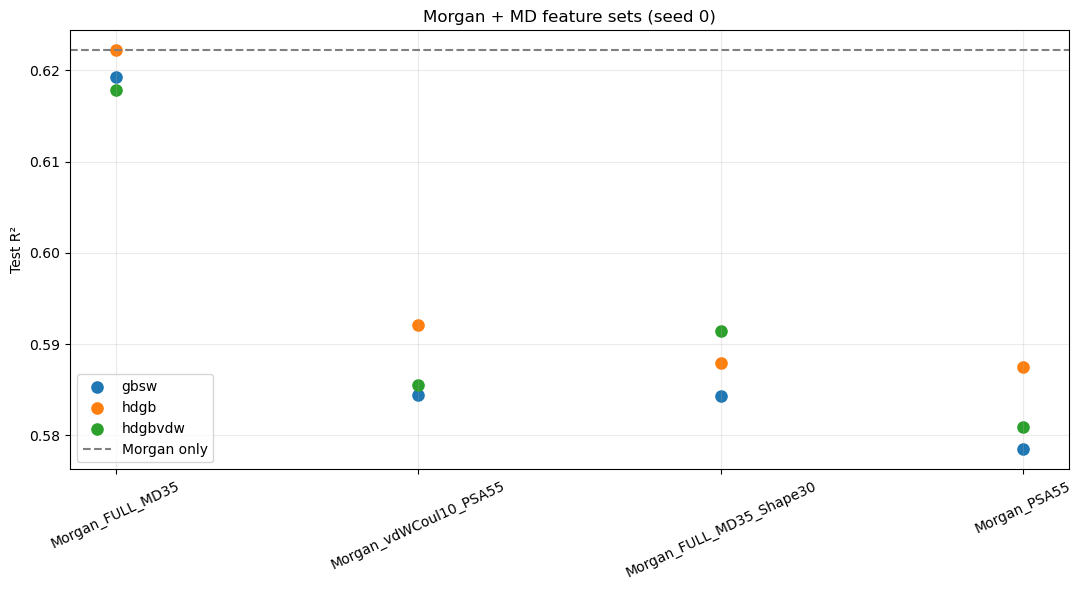


Elapsed minutes: 0.6
Saved to: /Users/teraimao/experiment/data/解析結果/morgan_MD_feature_sets_seed0


In [31]:


# ============================================================
# 1. 基本設定
# ============================================================

BASE = "/Users/teraimao/experiment/data/解析結果"
ORIGINAL = "/Users/teraimao/experiment/data/all_csv_data/this_is_CycPeptMPDB.csv"

OUT = os.path.join(BASE, "morgan_MD_feature_sets_seed0")
os.makedirs(OUT, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]
SEED = 0
N_TREES = 500

MD_GROUPS = [
    "HB_Avg", "SASA_Avg", "Solv_Free_Avg",
    "vdW_Avg", "Coul_Avg",
    "PSA3D_Avg", "NPSA3D_Avg"
]

FULL_MD35 = [
    f"{g}_pos{p}"
    for g in MD_GROUPS
    for p in range(1, 6)
]

VDW_COUL10 = [
    f"{g}_pos{p}"
    for g in ["vdW_Avg", "Coul_Avg"]
    for p in range(1, 6)
]

SHAPE_BASES = [
    "Aspect_Ratio_3D",
    "Theta_LongAxis_Z",
    "Z_over_XY"
]

# PSA55 = 5種類 × (Avg/Std) × 5位置 + 5種類のDelta
PSA_BASES = [
    "PSA3D",
    "NPSA3D",
    "Total_SASA_SR",
    "PSA_fraction",
    "NPSA_fraction"
]

# ============================================================
# 2. CSV読み込み
# ============================================================

frames = {}

for model in MODELS:

    psa_path = os.path.join(
        BASE,
        f"{model}_common_successID_baselineB_strictPAMPA_psa3d.csv"
    )
    shape_path = os.path.join(
        BASE,
        f"{model}_common_successID_baselineB_strictPAMPA_shape30.csv"
    )

    psa = pd.read_csv(psa_path, low_memory=False)
    shape = pd.read_csv(shape_path, low_memory=False)

    for df in (psa, shape):
        df["ID"] = pd.to_numeric(df["ID"], errors="coerce")
        df.dropna(subset=["ID"], inplace=True)
        df["ID"] = df["ID"].astype(int)

        if df["ID"].duplicated().any():
            raise ValueError(f"{model}: 重複IDがあります")

    # Shape CSVのうちPSA CSVにない列だけ追加
    extra_shape_cols = [
        c for c in shape.columns
        if c != "ID" and c not in psa.columns
    ]

    merged = psa.merge(
        shape[["ID"] + extra_shape_cols],
        on="ID",
        how="inner",
        validate="one_to_one"
    )

    frames[model] = merged

# ============================================================
# 3. 特徴量列名の解決
# ============================================================

def resolve_column(df, candidates):
    """表記ゆれを吸収して列名を探す"""
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        found = lookup.get(candidate.lower())
        if found is not None:
            return found
    return None


def avg_std_candidates(base, stat, pos):
    return [
        f"{base}_{stat}_pos{pos}",
        f"{base}_pos{pos}_{stat}",
        f"{base}_{stat.lower()}_pos{pos}",
        f"{base}_pos{pos}_{stat.lower()}",
    ]


def prepare_features(df, model):

    df = df.copy()

    missing = []

    # FULL_MD35
    for col in FULL_MD35:
        if col not in df.columns:
            missing.append(col)

    # Shape30
    shape_cols = []
    for base in SHAPE_BASES:
        for stat in ["Avg", "Std"]:
            for pos in range(1, 6):
                col = resolve_column(
                    df, avg_std_candidates(base, stat, pos)
                )
                if col is None:
                    missing.append(f"{base}_{stat}_pos{pos}")
                else:
                    shape_cols.append(col)

    # PSA55
    psa_cols = []

    for base in PSA_BASES:
        for stat in ["Avg", "Std"]:
            for pos in range(1, 6):
                col = resolve_column(
                    df, avg_std_candidates(base, stat, pos)
                )
                if col is None:
                    missing.append(f"{base}_{stat}_pos{pos}")
                else:
                    psa_cols.append(col)

        # DeltaはAvg(pos5) - Avg(pos1)として計算
        first = resolve_column(
            df, avg_std_candidates(base, "Avg", 1)
        )
        last = resolve_column(
            df, avg_std_candidates(base, "Avg", 5)
        )

        if first is not None and last is not None:
            delta_col = f"CALC_{base}_Delta_pos5_minus_pos1"
            df[delta_col] = (
                pd.to_numeric(df[last], errors="coerce")
                - pd.to_numeric(df[first], errors="coerce")
            )
            psa_cols.append(delta_col)

    if missing:
        print(f"\n[{model}] 見つからない列:")
        print("\n".join(missing[:80]))
        print("\n関連する実際の列名:")
        print([
            c for c in df.columns
            if any(s in c.lower() for s in
                   ["psa", "sasa", "aspect", "theta", "z_over"])
        ][:100])
        raise ValueError("列名を確認してください")

    assert len(FULL_MD35) == 35
    assert len(shape_cols) == 30
    assert len(psa_cols) == 55

    feature_sets = {
        "Morgan_only": [],
        "Morgan_PSA55": psa_cols,
        "Morgan_vdWCoul10_PSA55": list(dict.fromkeys(
            VDW_COUL10 + psa_cols
        )),
        "Morgan_FULL_MD35": FULL_MD35,
        "Morgan_FULL_MD35_Shape30": list(dict.fromkeys(
            FULL_MD35 + shape_cols
        )),
    }

    all_cols = list(dict.fromkeys(
        col
        for cols in feature_sets.values()
        for col in cols
    ))

    for col in all_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df, feature_sets, all_cols


prepared = {}
feature_map = {}
valid_ids = None

for model in MODELS:
    df, sets, all_cols = prepare_features(
        frames[model], model
    )

    df["PAMPA_logPm"] = pd.to_numeric(
        df["PAMPA_logPm"], errors="coerce"
    )

    df = df.dropna(
        subset=["PAMPA_logPm"] + all_cols
    )

    prepared[model] = df.set_index("ID")
    feature_map[model] = sets

    ids_here = set(df["ID"])
    valid_ids = (
        ids_here if valid_ids is None
        else valid_ids & ids_here
    )

# ============================================================
# 4. SMILESとMorgan fingerprint
# ============================================================

original = pd.read_csv(ORIGINAL, low_memory=False)

original["ID"] = pd.to_numeric(
    original["ID"], errors="coerce"
)
original = original.dropna(subset=["ID"]).copy()
original["ID"] = original["ID"].astype(int)

smiles_col = next(
    (c for c in ["SMILES", "Smiles", "smiles"]
     if c in original.columns),
    None
)

if smiles_col is None:
    raise ValueError("元データにSMILES列がありません")

original = original.drop_duplicates("ID").set_index("ID")

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048
)

fps = {}

for sid in sorted(valid_ids & set(original.index)):

    smiles = original.at[sid, smiles_col]

    if pd.isna(smiles):
        continue

    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        continue

    arr = np.zeros(2048, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(
        generator.GetFingerprint(mol), arr
    )
    fps[sid] = arr

ids = np.array(sorted(fps), dtype=int)

X_morgan = np.stack([
    fps[sid] for sid in ids
]).astype(np.float32)

y = prepared["gbsw"].loc[
    ids, "PAMPA_logPm"
].to_numpy(dtype=float)

for model in MODELS[1:]:
    y_other = prepared[model].loc[
        ids, "PAMPA_logPm"
    ].to_numpy(dtype=float)

    if not np.allclose(y, y_other):
        raise ValueError(f"{model}: 目的変数が一致しません")

print("使用ID数:", len(ids))
print("Morgan:", X_morgan.shape)

if len(ids) != 6390:
    print(
        "注意: 以前の6390件と異なります。"
        " 欠損値や列の一致を確認してください。"
    )

# ============================================================
# 5. train/test分割
# ============================================================

train_idx, test_idx = train_test_split(
    np.arange(len(ids)),
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

def metrics(obs, pred):
    return {
        "R": float(np.corrcoef(obs, pred)[0, 1]),
        "R2": float(r2_score(obs, pred)),
        "MAE": float(mean_absolute_error(obs, pred)),
        "RMSE": float(np.sqrt(
            mean_squared_error(obs, pred)
        ))
    }

def fit_and_predict(X):
    rf = RandomForestRegressor(
        n_estimators=N_TREES,
        max_features="sqrt",
        min_samples_leaf=1,
        random_state=SEED,
        n_jobs=-1
    )
    rf.fit(X[train_idx], y[train_idx])
    return rf.predict(X[test_idx])

# ============================================================
# 6. 学習
# ============================================================

rows = []
prediction_frames = []

start = time.time()

# Morgan onlyは1回だけ
print("\nTraining Morgan only...")
pred_morgan = fit_and_predict(X_morgan)

base_metrics = metrics(
    y[test_idx], pred_morgan
)

rows.append({
    "Model": "Morgan_only",
    "Feature_Set": "Morgan_only",
    "N_MD_Features": 0,
    **base_metrics
})

for model in MODELS:

    df = prepared[model].loc[ids]

    for set_name, md_cols in feature_map[model].items():

        if set_name == "Morgan_only":
            continue

        print(f"\nTraining {model} | {set_name}")

        X_md = df[md_cols].to_numpy(
            dtype=np.float32
        )

        X = np.concatenate(
            [X_morgan, X_md],
            axis=1
        )

        pred = fit_and_predict(X)
        score = metrics(y[test_idx], pred)

        rows.append({
            "Model": model,
            "Feature_Set": set_name,
            "N_MD_Features": len(md_cols),
            **score
        })

        prediction_frames.append(pd.DataFrame({
            "Model": model,
            "Feature_Set": set_name,
            "ID": ids[test_idx],
            "Observed": y[test_idx],
            "Predicted": pred
        }))

        # 途中結果も保存
        pd.DataFrame(rows).to_csv(
            os.path.join(OUT, "metrics_progress.csv"),
            index=False
        )

# ============================================================
# 7. 結果保存
# ============================================================

results = pd.DataFrame(rows)

results["Delta_R2_vs_Morgan"] = (
    results["R2"] - base_metrics["R2"]
)
results["Delta_MAE_vs_Morgan"] = (
    results["MAE"] - base_metrics["MAE"]
)

results = results.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

results.to_csv(
    os.path.join(OUT, "feature_sets_seed0_metrics.csv"),
    index=False
)

predictions = pd.concat(
    prediction_frames, ignore_index=True
)

predictions.to_csv(
    os.path.join(OUT, "feature_sets_seed0_predictions.csv"),
    index=False
)

print("\n=== RESULTS ===")
display(results.round(4))

# ============================================================
# 8. R²比較グラフ
# ============================================================

plot_df = results[
    results["Feature_Set"] != "Morgan_only"
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

for model in MODELS:

    sub = plot_df[
        plot_df["Model"] == model
    ]

    ax.scatter(
        sub["Feature_Set"],
        sub["R2"],
        label=model,
        s=65
    )

ax.axhline(
    base_metrics["R2"],
    linestyle="--",
    color="gray",
    label="Morgan only"
)

ax.set_ylabel("Test R²")
ax.set_title("Morgan + MD feature sets (seed 0)")
ax.tick_params(axis="x", rotation=25)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "feature_sets_seed0_R2.png"),
    dpi=300
)
plt.show()

print("\nElapsed minutes:",
      round((time.time() - start) / 60, 1))

print("Saved to:", OUT)

## this_is,,を深掘り

元データ件数: 8466
学習対象件数: 6390
出典数（元）: 56
出典数（学習対象）: 31


,N_original,N_ML,Retention_rate
Source,,,
2020_Townsend,3086,2848,0.922878
2021_Kelly,1519,1448,0.953259
2013_CHUGAI,878,767,0.873576
2016_Furukawa,688,625,0.908430
2024_Faris,234,206,0.880342
2022_Bhardwaj,136,130,0.955882
2018_Naylor,81,70,0.864198
2024_Koch,54,42,0.777778
2022_Taechalertpaisarn,52,40,0.769231


,N,Mean,Median,Std,Min,Max
Source,,,,,,
2020_Townsend,2848,-5.689084,-5.670000,0.498272,-7.850000,-4.400000
2021_Kelly,1448,-5.906706,-5.780000,0.674073,-9.000000,-4.640000
2013_CHUGAI,767,-4.857705,-4.660000,0.571461,-6.960000,-4.150000
2016_Furukawa,625,-6.030672,-5.750000,0.976348,-9.290000,-4.760000
2024_Faris,206,-6.555037,-6.556945,0.829195,-8.522764,-4.994304
2022_Bhardwaj,130,-5.904538,-5.830000,0.538034,-7.480000,-4.860000
2018_Naylor,70,-5.771000,-5.625000,0.767173,-7.850000,-4.870000
2024_Koch,42,-6.560960,-6.256918,0.868046,-9.023709,-5.547768
2022_Taechalertpaisarn,40,-6.120500,-5.985000,0.792280,-8.390000,-4.870000


,N_total,N_minus10,N_PAMPA_numeric,Minus10_rate
Source,,,,
2020_Townsend,3086,205,3086,0.066429
2024_Faris,234,27,234,0.115385
2018_Ramalho,10,9,10,0.900000
2015_Wang,62,8,62,0.129032
2016_Furukawa,688,8,688,0.011628
2022_Lee,24,3,24,0.125000
2015_Ahlbach,34,3,34,0.088235
2022_Tamura,12,2,12,0.166667
2015_Marelli,10,2,10,0.200000


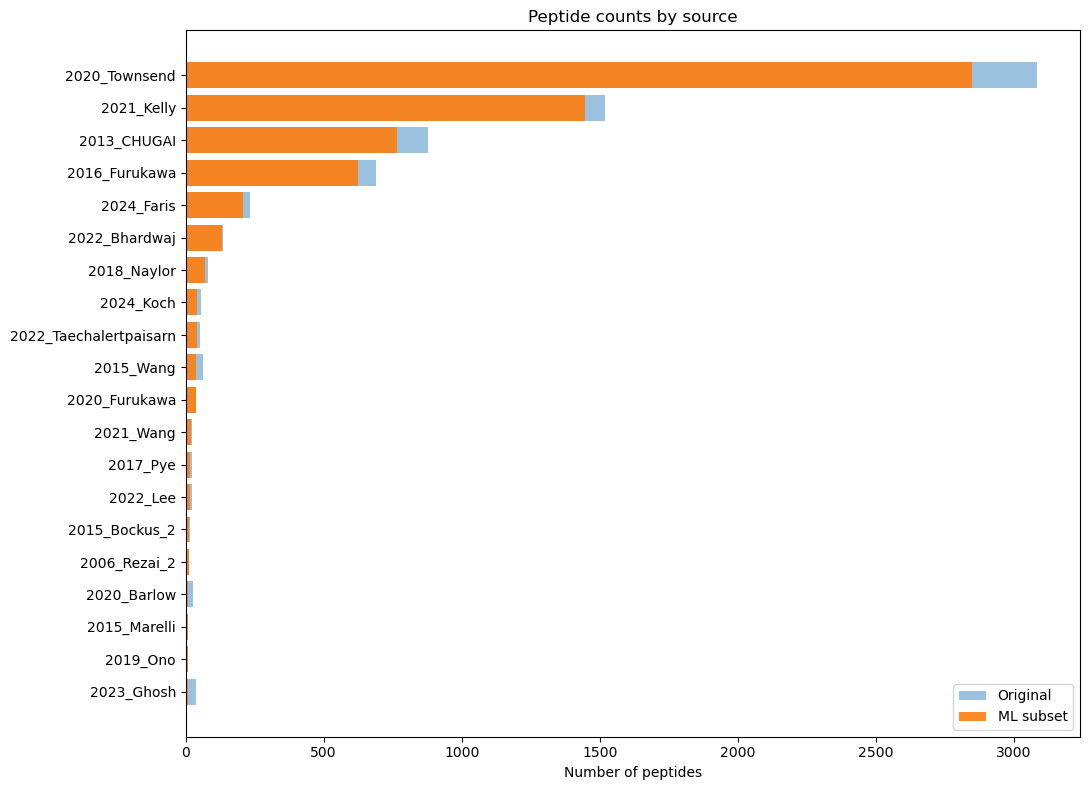

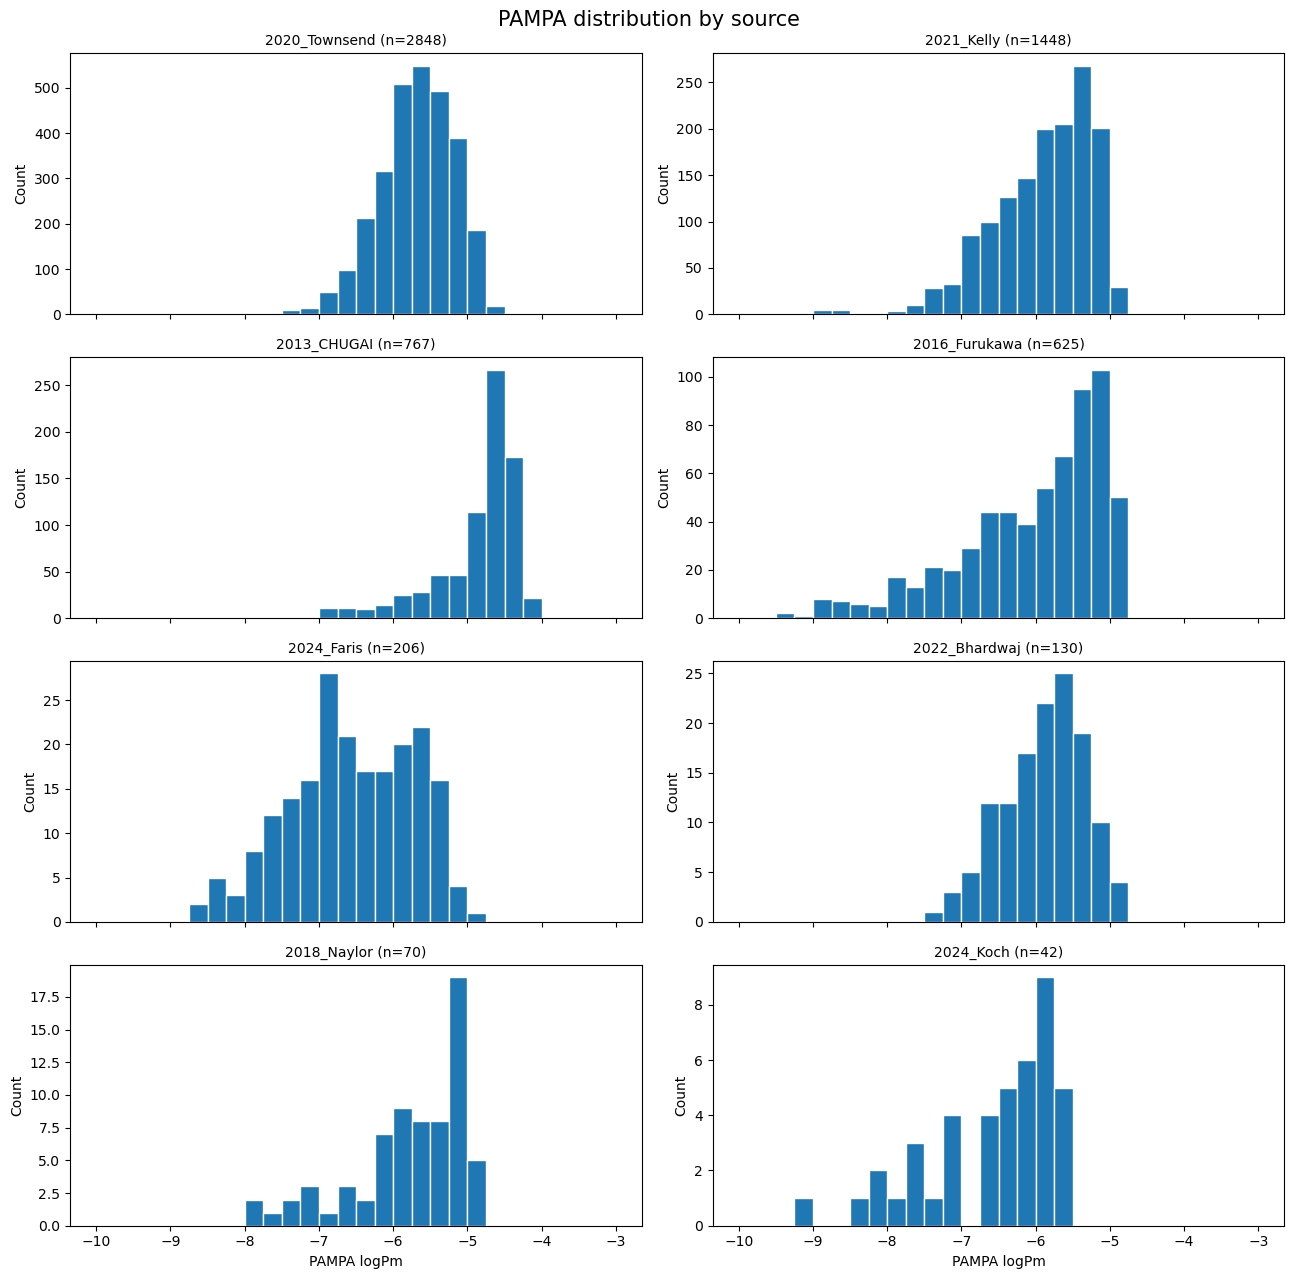

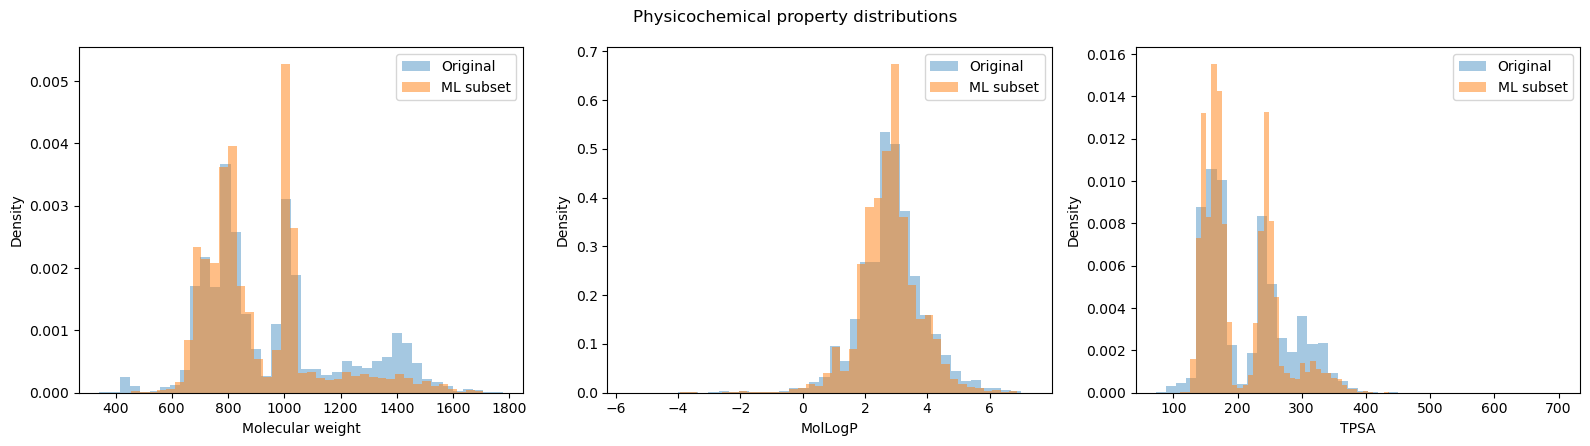

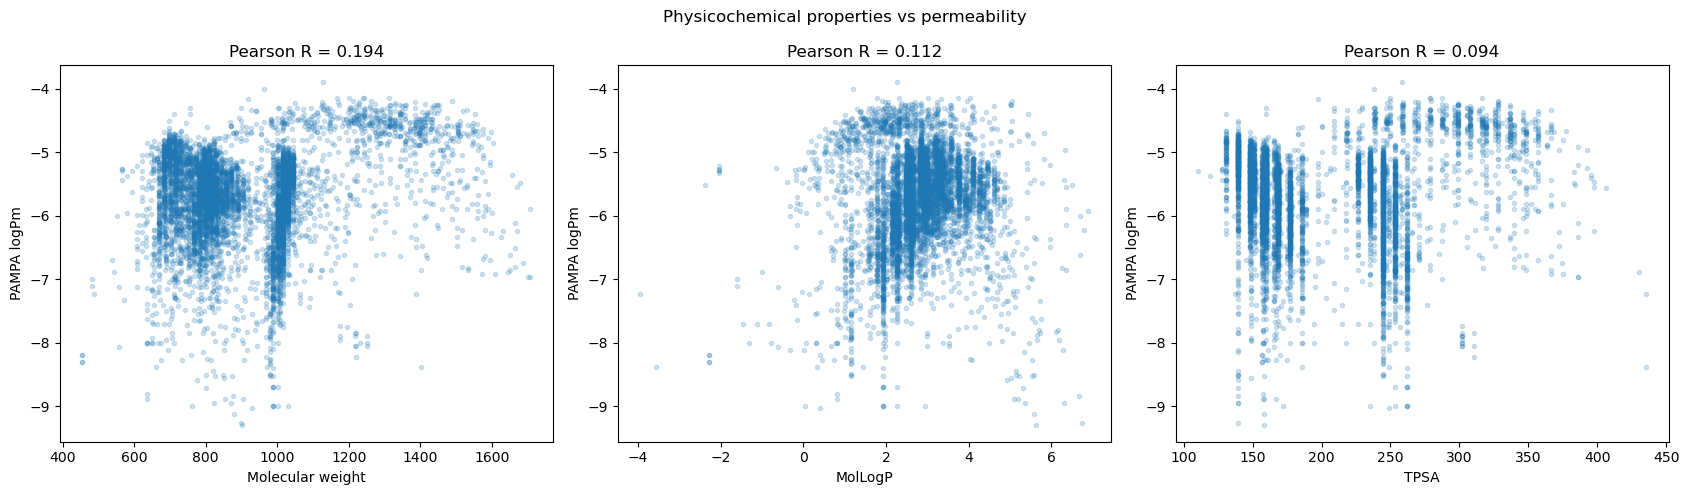

,N,MW_mean,MW_std,LogP_mean,LogP_std,TPSA_mean,TPSA_std,PAMPA_mean,PAMPA_std
Source,,,,,,,,,
2020_Townsend,2848,782.698,62.067,3.061,0.654,159.913,12.625,-5.689,0.498
2021_Kelly,1448,1018.015,21.452,2.605,0.426,245.032,10.473,-5.907,0.674
2013_CHUGAI,767,1288.986,189.476,2.418,1.391,302.194,43.177,-4.858,0.571
2016_Furukawa,625,760.462,70.703,3.127,1.172,156.551,11.040,-6.031,0.976
2024_Faris,206,994.713,19.595,1.558,0.463,244.250,0.000,-6.555,0.829
2022_Bhardwaj,130,970.898,152.223,2.523,0.942,219.204,35.666,-5.905,0.538
2018_Naylor,70,778.519,153.690,3.025,1.171,171.381,39.467,-5.771,0.767
2024_Koch,42,1008.746,55.035,2.164,1.230,248.660,0.000,-6.561,0.868
2022_Taechalertpaisarn,40,742.007,49.985,2.225,0.868,184.597,5.418,-6.120,0.792



保存先: /Users/teraimao/experiment/data/解析結果/cycpeptmpdb_dataset_analysis


In [33]:

# ============================================================
# 1. パス
# ============================================================

ORIGINAL = (
    "/Users/teraimao/experiment/data/all_csv_data/"
    "this_is_CycPeptMPDB.csv"
)

BASE = "/Users/teraimao/experiment/data/解析結果"

ML_FILE = os.path.join(
    BASE,
    "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv"
)

OUT = os.path.join(BASE, "cycpeptmpdb_dataset_analysis")
os.makedirs(OUT, exist_ok=True)

# ============================================================
# 2. 読み込み
# ============================================================

original = pd.read_csv(ORIGINAL, low_memory=False)
ml = pd.read_csv(ML_FILE, low_memory=False)

original["ID"] = pd.to_numeric(
    original["ID"], errors="coerce"
)
ml["ID"] = pd.to_numeric(
    ml["ID"], errors="coerce"
)

original = original.dropna(subset=["ID"]).copy()
ml = ml.dropna(subset=["ID"]).copy()

original["ID"] = original["ID"].astype(int)
ml["ID"] = ml["ID"].astype(int)

# 元データはそのまま保持
original["Source"] = (
    original["Source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

original.loc[
    original["Source"].eq(""), "Source"
] = "Unknown"

# 解析する数値列
numeric_cols = [
    "PAMPA", "MolWt", "MolLogP", "TPSA",
    "Sequence_LogP", "Sequence_TPSA"
]

for col in numeric_cols:
    if col in original.columns:
        original[col] = pd.to_numeric(
            original[col], errors="coerce"
        )

ml["PAMPA_logPm"] = pd.to_numeric(
    ml["PAMPA_logPm"], errors="coerce"
)

# ============================================================
# 3. 実際の学習対象IDを取得
# ============================================================

# GBSW・HDGB・HDGBvdWで共通して使用できるID
model_files = {
    "gbsw": ML_FILE,
    "hdgb": os.path.join(
        BASE,
        "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv"
    ),
    "hdgbvdw": os.path.join(
        BASE,
        "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv"
    )
}

common_ids = None

for model, path in model_files.items():

    d = pd.read_csv(
        path, usecols=["ID"], low_memory=False
    )

    d["ID"] = pd.to_numeric(
        d["ID"], errors="coerce"
    )

    ids_here = set(
        d["ID"].dropna().astype(int)
    )

    common_ids = (
        ids_here if common_ids is None
        else common_ids & ids_here
    )

# 同じIDの原データ側の情報を結合
if original["ID"].duplicated().any():
    raise ValueError(
        "元データ内でIDが重複しています。"
        " 重複処理方針を確認してください。"
    )

if ml["ID"].duplicated().any():
    raise ValueError("学習用CSVにIDの重複があります")

ml = ml.loc[
    ml["ID"].isin(common_ids),
    ["ID", "PAMPA_logPm"]
].copy()

selected = ml.merge(
    original[
        ["ID", "Source", "Year", "Sequence",
         "PAMPA", "MolWt", "MolLogP", "TPSA"]
    ],
    on="ID",
    how="left",
    validate="one_to_one",
    indicator=True
)

if not selected["_merge"].eq("both").all():
    raise ValueError(
        "元データに対応するIDが見つからない行があります"
    )

selected = selected.drop(columns="_merge")

selected["In_ML"] = True
original["In_ML"] = original["ID"].isin(
    selected["ID"]
)

print("元データ件数:", len(original))
print("学習対象件数:", len(selected))
print("出典数（元）:", original["Source"].nunique())
print("出典数（学習対象）:", selected["Source"].nunique())

if len(selected) != 6390:
    print(
        "注意：以前の6390件と異なります。"
        " 絞り込み条件を確認してください。"
    )

# ============================================================
# 4. 出典論文ごとの件数
# ============================================================

source_all = (
    original.groupby("Source")
    .size()
    .rename("N_original")
)

source_ml = (
    selected.groupby("Source")
    .size()
    .rename("N_ML")
)

source_table = pd.concat(
    [source_all, source_ml], axis=1
).fillna(0)

source_table = source_table.astype(int)

source_table["Retention_rate"] = (
    source_table["N_ML"]
    / source_table["N_original"]
)

source_table = source_table.sort_values(
    "N_ML", ascending=False
)

display(source_table.head(30))

source_table.to_csv(
    os.path.join(OUT, "source_counts.csv")
)

# ============================================================
# 5. 出典ごとの透過性の統計
# ============================================================

permeability_stats = (
    selected.groupby("Source")["PAMPA_logPm"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .sort_values("N", ascending=False)
)

display(permeability_stats.head(30))

permeability_stats.to_csv(
    os.path.join(OUT, "source_permeability_stats.csv")
)

# ============================================================
# 6. 元データの -10 の分布
# ============================================================

# PAMPA列を数値に変換できたものだけを対象に集計。
# 文字列の測定下限表示などは別途確認する。

original["PAMPA_is_minus10"] = (
    original["PAMPA"].eq(-10)
)

minus10_table = original.groupby("Source").agg(
    N_total=("ID", "size"),
    N_minus10=("PAMPA_is_minus10", "sum"),
    N_PAMPA_numeric=("PAMPA", "count")
)

minus10_table["Minus10_rate"] = (
    minus10_table["N_minus10"]
    / minus10_table["N_total"]
)

minus10_table = minus10_table.sort_values(
    "N_minus10", ascending=False
)

display(minus10_table.head(30))

minus10_table.to_csv(
    os.path.join(OUT, "source_minus10_counts.csv")
)

# ============================================================
# 7. 出典ごとの件数グラフ
# ============================================================

top_sources = source_table.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 8))

ypos = np.arange(len(top_sources))

ax.barh(
    ypos,
    top_sources["N_original"],
    alpha=0.45,
    label="Original"
)

ax.barh(
    ypos,
    top_sources["N_ML"],
    alpha=0.9,
    label="ML subset"
)

ax.set_yticks(ypos)
ax.set_yticklabels(top_sources.index)

ax.set_xlabel("Number of peptides")
ax.set_title("Peptide counts by source")
ax.legend()

fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "source_counts.png"),
    dpi=300
)
plt.show()

# ============================================================
# 8. 出典別のPAMPA分布
# ============================================================

# 件数の多い8出典を表示
top8 = (
    selected["Source"]
    .value_counts()
    .head(8)
    .index
)

fig, axes = plt.subplots(
    4, 2, figsize=(13, 13),
    sharex=True
)

bins = np.arange(-10, -2.75, 0.25)

for ax, source in zip(axes.flat, top8):

    values = selected.loc[
        selected["Source"] == source,
        "PAMPA_logPm"
    ].dropna()

    ax.hist(
        values, bins=bins,
        edgecolor="white"
    )

    ax.set_title(
        f"{source} (n={len(values)})",
        fontsize=10
    )

    ax.set_ylabel("Count")

for ax in axes[-1]:
    ax.set_xlabel("PAMPA logPm")

fig.suptitle(
    "PAMPA distribution by source",
    fontsize=15
)

fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "source_PAMPA_distributions.png"),
    dpi=300
)
plt.show()

# ============================================================
# 9. 全体とML対象の物性分布
# ============================================================

properties = [
    ("MolWt", "Molecular weight"),
    ("MolLogP", "MolLogP"),
    ("TPSA", "TPSA")
]

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5)
)

for ax, (col, label) in zip(axes, properties):

    a = original[col].dropna()
    b = selected[col].dropna()

    ax.hist(
        a, bins=40, density=True,
        alpha=0.4, label="Original"
    )

    ax.hist(
        b, bins=40, density=True,
        alpha=0.5, label="ML subset"
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    "Physicochemical property distributions"
)

fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "property_distributions.png"),
    dpi=300
)
plt.show()

# ============================================================
# 10. 物性と膜透過性の関係
# ============================================================

fig, axes = plt.subplots(
    1, 3, figsize=(17, 5)
)

for ax, (col, label) in zip(axes, properties):

    ax.scatter(
        selected[col],
        selected["PAMPA_logPm"],
        s=9,
        alpha=0.2
    )

    valid = selected[
        [col, "PAMPA_logPm"]
    ].dropna()

    correlation = valid[col].corr(
        valid["PAMPA_logPm"]
    )

    ax.set_xlabel(label)
    ax.set_ylabel("PAMPA logPm")
    ax.set_title(f"Pearson R = {correlation:.3f}")

fig.suptitle(
    "Physicochemical properties vs permeability"
)

fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "properties_vs_PAMPA.png"),
    dpi=300
)
plt.show()

# ============================================================
# 11. 出典別の物性統計
# ============================================================

property_stats = selected.groupby("Source").agg(
    N=("ID", "size"),
    MW_mean=("MolWt", "mean"),
    MW_std=("MolWt", "std"),
    LogP_mean=("MolLogP", "mean"),
    LogP_std=("MolLogP", "std"),
    TPSA_mean=("TPSA", "mean"),
    TPSA_std=("TPSA", "std"),
    PAMPA_mean=("PAMPA_logPm", "mean"),
    PAMPA_std=("PAMPA_logPm", "std")
).sort_values("N", ascending=False)

property_stats.to_csv(
    os.path.join(OUT, "source_property_stats.csv")
)

display(property_stats.head(30).round(3))

print("\n保存先:", OUT)

## 現在の予測を出典別に評価

In [35]:

BASE = "/Users/teraimao/experiment/data/解析結果"

ORIGINAL = (
    "/Users/teraimao/experiment/data/all_csv_data/"
    "this_is_CycPeptMPDB.csv"
)

PRED = os.path.join(
    BASE,
    "morgan_MD_separateRF_ensemble_seed0",
    "ensemble_seed0_predictions.csv"
)

OUT = os.path.join(
    BASE,
    "cycpeptmpdb_dataset_analysis",
    "ensemble_performance_by_source.csv"
)

original = pd.read_csv(
    ORIGINAL,
    usecols=["ID", "Source"]
)

pred = pd.read_csv(PRED)

# IDと出典の対応付け
original = original.drop_duplicates("ID")

df = pred.merge(
    original,
    on="ID",
    how="left",
    validate="many_to_one"
)

if df["Source"].isna().any():
    raise ValueError("出典が不明なIDがあります")

rows = []

for (model, source), g in df.groupby(
    ["Model", "Source"]
):
    # テストデータが30件以上の出典
    if len(g) < 30:
        continue

    y = g["Observed"].to_numpy()
    p_morgan = g["Morgan_pred"].to_numpy()
    p_ensemble = g["Ensemble_pred"].to_numpy()

    r2_morgan = r2_score(y, p_morgan)
    r2_ensemble = r2_score(y, p_ensemble)

    mae_morgan = mean_absolute_error(y, p_morgan)
    mae_ensemble = mean_absolute_error(y, p_ensemble)

    rows.append({
        "Model": model,
        "Source": source,
        "N_test": len(g),
        "PAMPA_std": np.std(y, ddof=1),
        "Morgan_R2": r2_morgan,
        "Ensemble_R2": r2_ensemble,
        "Delta_R2": r2_ensemble - r2_morgan,
        "Morgan_MAE": mae_morgan,
        "Ensemble_MAE": mae_ensemble,
        "Delta_MAE": mae_ensemble - mae_morgan
    })

result = pd.DataFrame(rows).sort_values(
    ["Model", "Delta_R2"],
    ascending=[True, False]
)

display(result.round(4))
result.to_csv(OUT, index=False)

print("Saved:", OUT)


,Model,Source,N_test,PAMPA_std,Morgan_R2,Ensemble_R2,Delta_R2,Morgan_MAE,Ensemble_MAE,Delta_MAE
3,gbsw,2021_Kelly,289,0.7099,0.3990,0.4199,0.0209,0.4090,0.4081,-0.0009
0,gbsw,2013_CHUGAI,150,0.5250,0.2843,0.2977,0.0134,0.3347,0.3390,0.0043
1,gbsw,2016_Furukawa,125,0.9185,0.6298,0.6387,0.0088,0.4397,0.4277,-0.0120
2,gbsw,2020_Townsend,586,0.5015,0.5063,0.5103,0.0040,0.2699,0.2709,0.0010
4,gbsw,2024_Faris,36,0.8578,0.3582,0.3330,-0.0252,0.5709,0.5849,0.0141
5,hdgb,2013_CHUGAI,150,0.5250,0.2843,0.3042,0.0199,0.3347,0.3374,0.0027
8,hdgb,2021_Kelly,289,0.7099,0.3990,0.4177,0.0187,0.4090,0.4070,-0.0020
6,hdgb,2016_Furukawa,125,0.9185,0.6298,0.6445,0.0147,0.4397,0.4248,-0.0148
7,hdgb,2020_Townsend,586,0.5015,0.5063,0.5059,-0.0004,0.2699,0.2728,0.0029
9,hdgb,2024_Faris,36,0.8578,0.3582,0.3167,-0.0416,0.5709,0.5932,0.0223


Saved: /Users/teraimao/experiment/data/解析結果/cycpeptmpdb_dataset_analysis/ensemble_performance_by_source.csv


## 5位置で変化を高・低透過性で比較

### -6.0を閾値に

gbsw valid IDs: 6390
hdgb valid IDs: 6390
hdgbvdw valid IDs: 6390

Common IDs: 6390

=== Group counts ===
Group
High    4473
Low     1917
Name: count, dtype: int64

=== Position summary ===


,Model,Feature,Group,Position,N,Mean,Std,Median,Q25,Q75
0,gbsw,IMHB,High,1,4473,1.791,1.095,1.632,0.992,2.344
1,gbsw,IMHB,High,2,4473,1.757,1.058,1.640,1.000,2.304
2,gbsw,IMHB,High,3,4473,0.833,0.709,0.760,0.208,1.240
3,gbsw,IMHB,High,4,4473,0.601,0.589,0.488,0.072,0.936
4,gbsw,IMHB,High,5,4473,0.524,0.527,0.400,0.056,0.848
5,gbsw,IMHB,Low,1,1917,1.940,0.910,1.872,1.304,2.472
6,gbsw,IMHB,Low,2,1917,1.882,0.882,1.816,1.256,2.400
7,gbsw,IMHB,Low,3,1917,0.902,0.725,0.848,0.288,1.328
8,gbsw,IMHB,Low,4,1917,0.622,0.619,0.456,0.088,0.968
9,gbsw,IMHB,Low,5,1917,0.531,0.520,0.408,0.072,0.872


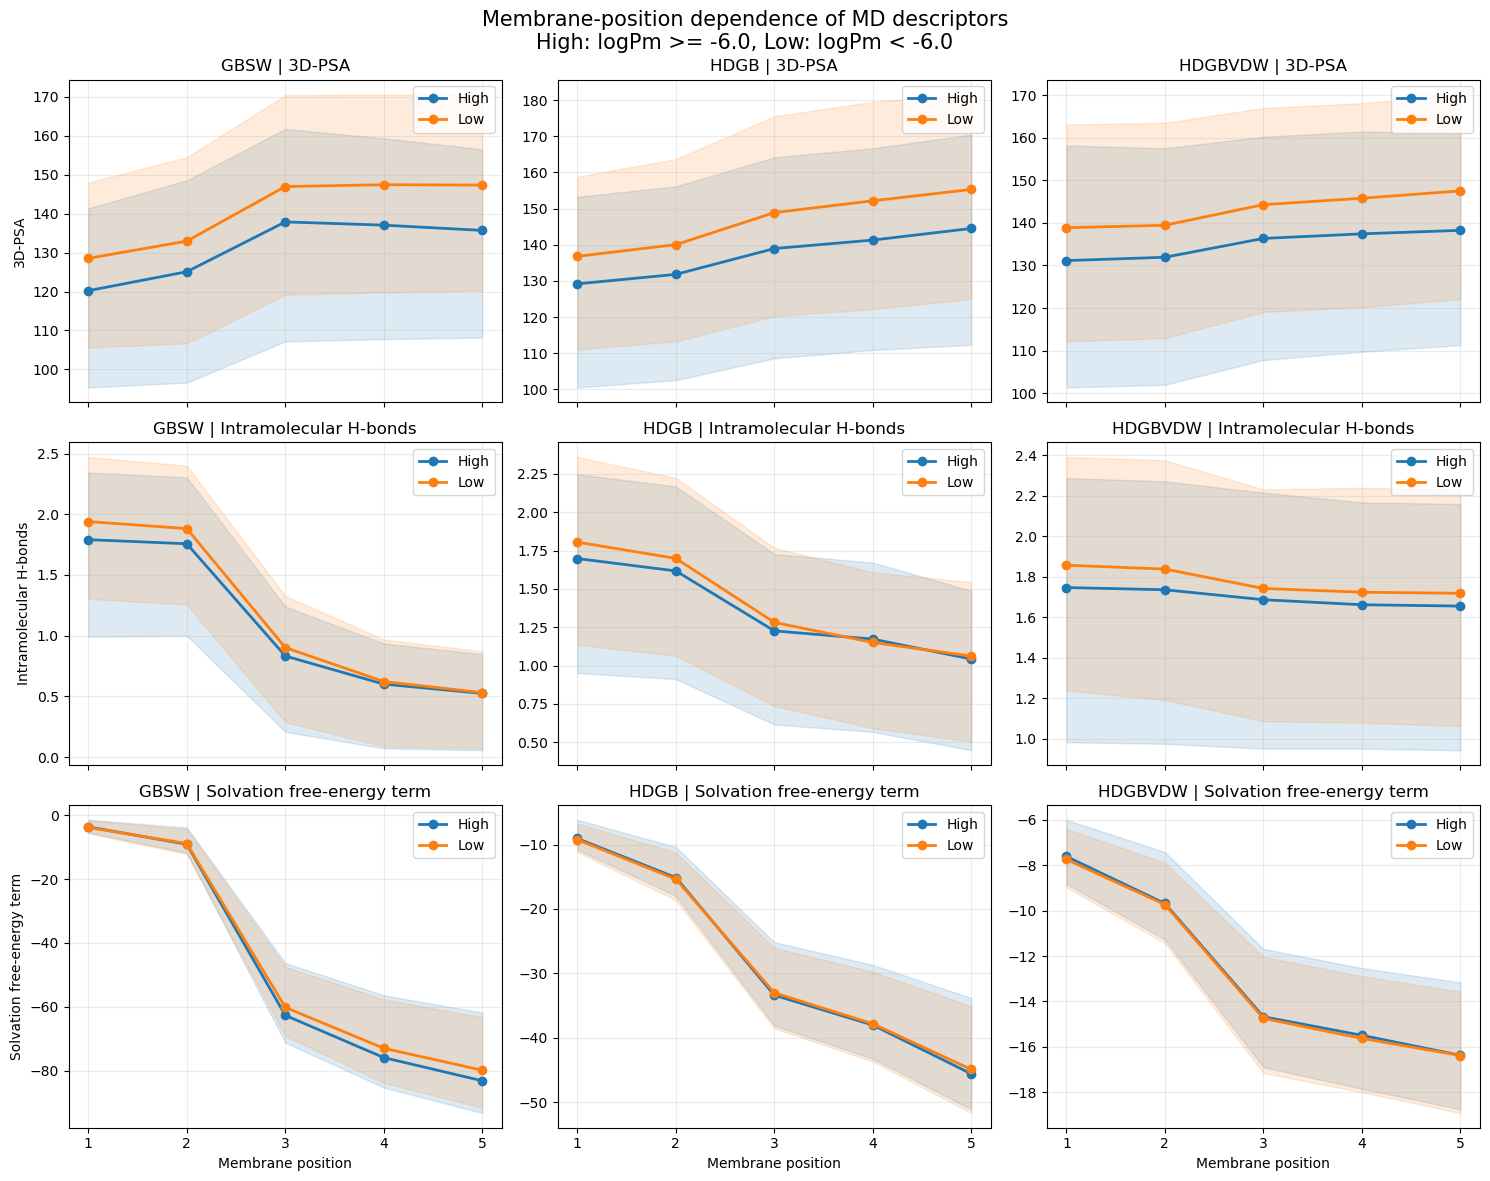

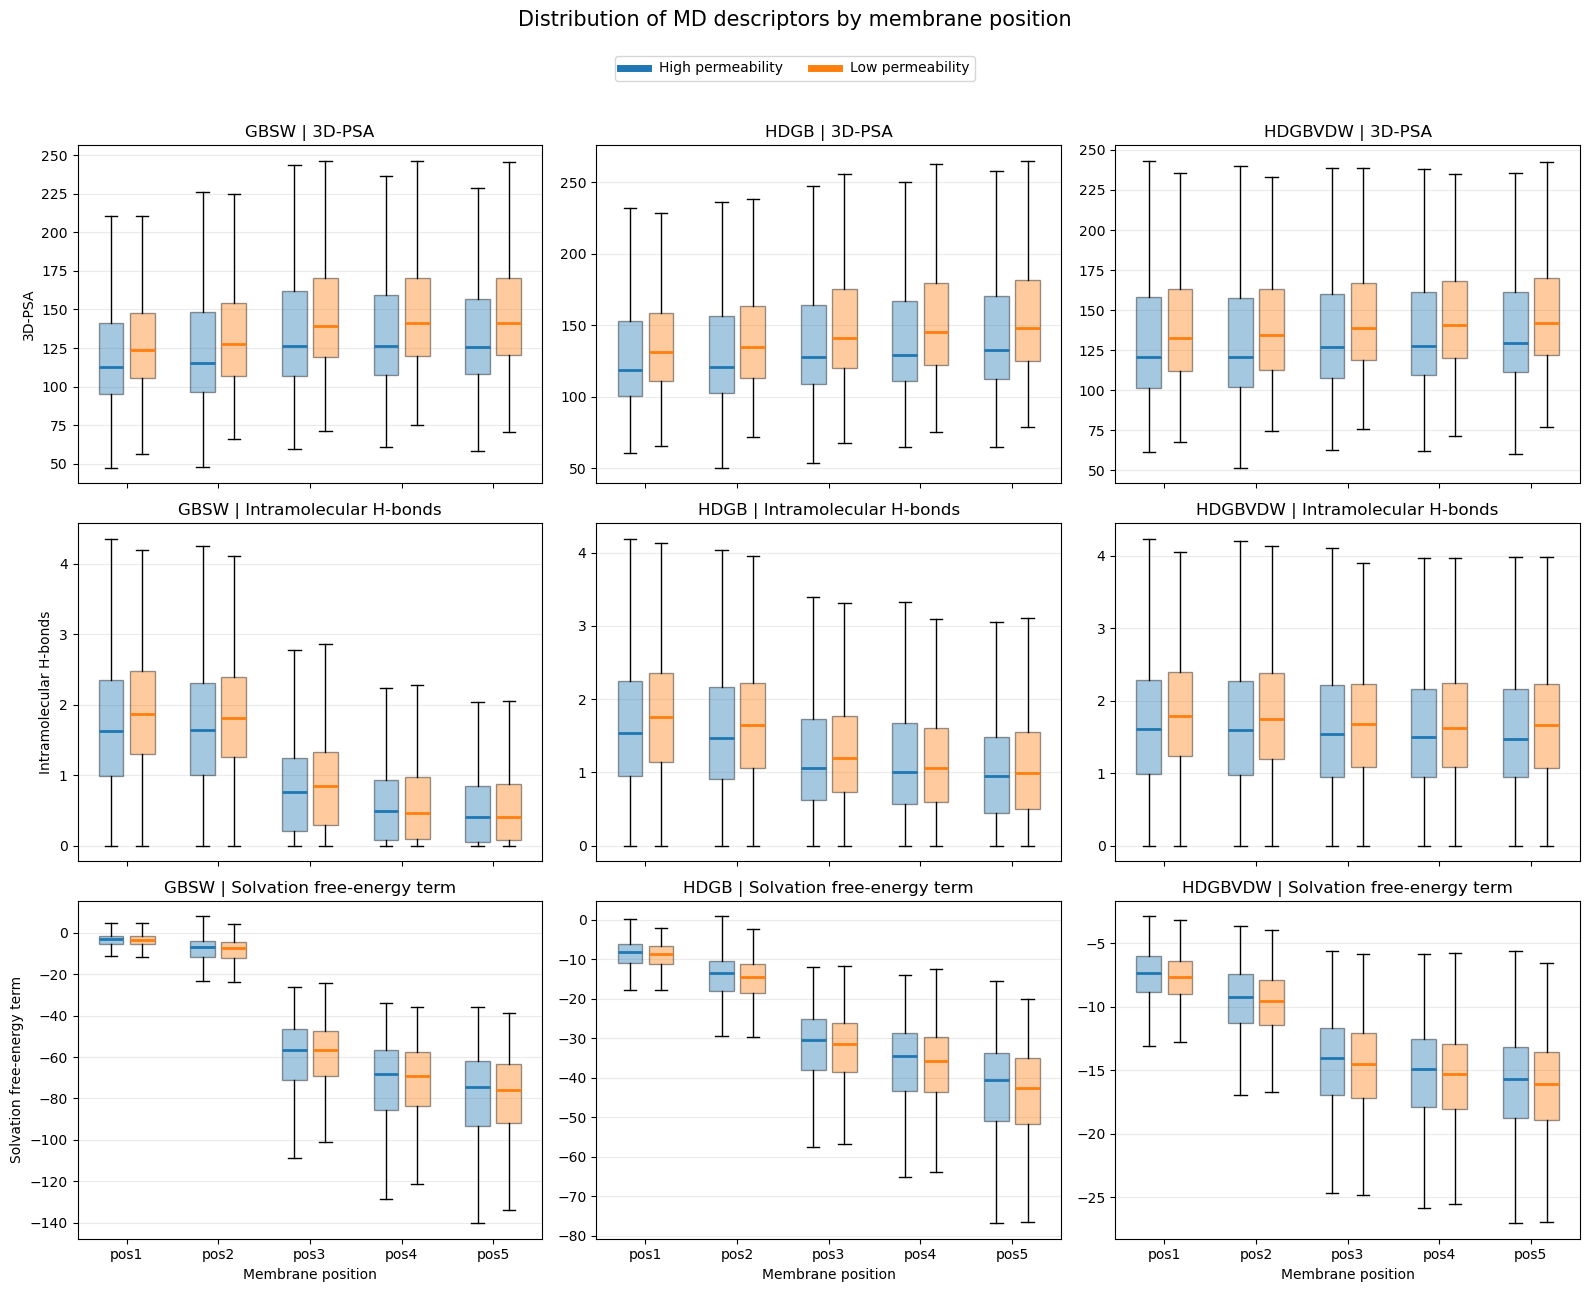


=== Position changes ===


,Model,Feature,Group,N,Delta_mean,Delta_median,Delta_std,Range_mean,Range_median
0,gbsw,IMHB,High,4473,-1.267,-1.120,1.052,1.773,1.616
1,gbsw,IMHB,Low,1917,-1.409,-1.376,0.955,1.881,1.800
2,gbsw,PSA3D,High,4473,15.490,14.423,24.757,37.771,33.632
3,gbsw,PSA3D,Low,1917,18.834,17.707,25.352,39.554,35.383
4,gbsw,Solv_Free,High,4473,-79.595,-71.149,30.111,82.075,73.155
5,gbsw,Solv_Free,Low,1917,-76.108,-71.976,21.931,78.180,74.022
6,hdgb,IMHB,High,4473,-0.655,-0.560,0.961,1.353,1.224
7,hdgb,IMHB,Low,1917,-0.743,-0.664,0.958,1.415,1.320
8,hdgb,PSA3D,High,4473,15.309,13.190,22.615,32.459,28.564
9,hdgb,PSA3D,Low,1917,18.506,16.020,23.758,34.722,30.376



All analyses completed.
Saved to: /Users/teraimao/experiment/data/解析結果/membrane_position_analysis


In [37]:

# ============================================================
# 1. 設定
# ============================================================

BASE = "/Users/teraimao/experiment/data/解析結果"

OUT = os.path.join(BASE, "membrane_position_analysis")
os.makedirs(OUT, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]
POSITIONS = [1, 2, 3, 4, 5]

# 高透過性・低透過性の境界
THRESHOLD = -6.0

# 各特徴量のCSV内の列名
FEATURES = {
    "PSA3D": {
        "column": "PSA3D_Avg",
        "label": "3D-PSA",
    },
    "IMHB": {
        "column": "HB_Avg",
        "label": "Intramolecular H-bonds",
    },
    "Solv_Free": {
        "column": "Solv_Free_Avg",
        "label": "Solvation free-energy term",
    },
}

GROUPS = ["High", "Low"]

# ============================================================
# 2. CSVの読み込み
# ============================================================

frames = {}

required_cols = ["ID", "PAMPA_logPm"]

for feature in FEATURES.values():
    for pos in POSITIONS:
        required_cols.append(
            f"{feature['column']}_pos{pos}"
        )

required_cols = list(dict.fromkeys(required_cols))

for model in MODELS:

    filename = (
        f"{model}_common_successID_"
        "baselineB_strictPAMPA_psa3d.csv"
    )

    path = os.path.join(BASE, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    # 必要な列だけ読み込む
    df = pd.read_csv(path, low_memory=False)

    missing = [
        col for col in required_cols
        if col not in df.columns
    ]

    if missing:
        print(f"\n{model}で不足している列:")
        print(missing)
        raise ValueError("CSV列名を確認してください")

    df = df[required_cols].copy()

    for col in required_cols:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    df = df.dropna(subset=required_cols).copy()
    df["ID"] = df["ID"].astype(int)

    if df["ID"].duplicated().any():
        raise ValueError(
            f"{model}: IDに重複があります"
        )

    frames[model] = df.set_index("ID")

    print(model, "valid IDs:", len(df))

# ============================================================
# 3. 3モデル共通IDで比較
# ============================================================

common_ids = set(frames["gbsw"].index)

for model in MODELS[1:]:
    common_ids &= set(frames[model].index)

common_ids = sorted(common_ids)

print("\nCommon IDs:", len(common_ids))

if len(common_ids) != 6390:
    print(
        "注意: これまでの6390件とは件数が異なります。"
        " 欠損値と共通IDを確認してください。"
    )

for model in MODELS:
    frames[model] = frames[model].loc[common_ids]

# 目的変数が各モデルで一致するか確認
y = frames["gbsw"]["PAMPA_logPm"]

for model in MODELS[1:]:

    y_other = frames[model]["PAMPA_logPm"]

    if not np.allclose(
        y.to_numpy(),
        y_other.to_numpy(),
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model}: PAMPA logPmが一致しません"
        )

# ============================================================
# 4. 高透過性・低透過性に分類
# ============================================================

group_by_id = pd.Series(
    np.where(y >= THRESHOLD, "High", "Low"),
    index=y.index,
    name="Group"
)

counts = group_by_id.value_counts()

print("\n=== Group counts ===")
print(counts)

counts.rename("N").to_csv(
    os.path.join(OUT, "group_counts.csv")
)

# ============================================================
# 5. 縦長データに変換
# ============================================================

long_rows = []
change_rows = []

for model in MODELS:

    df = frames[model]

    for feature_name, feature in FEATURES.items():

        cols = [
            f"{feature['column']}_pos{pos}"
            for pos in POSITIONS
        ]

        values = df[cols].to_numpy(dtype=float)

        # 全ペプチド × 5位置
        for j, pos in enumerate(POSITIONS):

            long_rows.append(pd.DataFrame({
                "ID": common_ids,
                "Model": model,
                "Feature": feature_name,
                "Position": pos,
                "Group": group_by_id.to_numpy(),
                "PAMPA_logPm": y.to_numpy(),
                "Value": values[:, j]
            }))

        # 位置間の変化量
        # pos5 - pos1
        change_rows.append(pd.DataFrame({
            "ID": common_ids,
            "Model": model,
            "Feature": feature_name,
            "Group": group_by_id.to_numpy(),
            "PAMPA_logPm": y.to_numpy(),
            "Value_pos1": values[:, 0],
            "Value_pos5": values[:, -1],
            "Delta_pos5_minus_pos1": (
                values[:, -1] - values[:, 0]
            ),
            "Range_max_minus_min": (
                values.max(axis=1) - values.min(axis=1)
            )
        }))

long_df = pd.concat(
    long_rows, ignore_index=True
)

changes_df = pd.concat(
    change_rows, ignore_index=True
)

long_df.to_csv(
    os.path.join(OUT, "position_values_long.csv"),
    index=False
)

changes_df.to_csv(
    os.path.join(OUT, "per_peptide_position_changes.csv"),
    index=False
)

# ============================================================
# 6. 各位置の統計量
# ============================================================

summary = (
    long_df.groupby(
        ["Model", "Feature", "Group", "Position"]
    )["Value"]
    .agg(
        N="count",
        Mean="mean",
        Std="std",
        Median="median",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

summary.to_csv(
    os.path.join(OUT, "position_summary.csv"),
    index=False
)

print("\n=== Position summary ===")
display(summary.round(3).head(20))

# ============================================================
# 7. 平均値の位置依存性
# 3行（特徴量）× 3列（膜モデル）
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12),
    sharex=True
)

for row, (feature_name, feature) in enumerate(
    FEATURES.items()
):

    for col, model in enumerate(MODELS):

        ax = axes[row, col]

        for group in GROUPS:

            sub = summary[
                (summary["Model"] == model)
                & (summary["Feature"] == feature_name)
                & (summary["Group"] == group)
            ].sort_values("Position")

            x = sub["Position"].to_numpy()
            mean = sub["Mean"].to_numpy()
            q25 = sub["Q25"].to_numpy()
            q75 = sub["Q75"].to_numpy()

            line, = ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=group
            )

            # 薄い帯 = ペプチド間の25〜75%範囲
            ax.fill_between(
                x,
                q25,
                q75,
                alpha=0.15,
                color=line.get_color()
            )

        ax.set_title(
            f"{model.upper()} | {feature['label']}"
        )

        ax.set_xticks(POSITIONS)
        ax.grid(alpha=0.25)
        ax.legend()

        if col == 0:
            ax.set_ylabel(feature["label"])

        if row == 2:
            ax.set_xlabel("Membrane position")

fig.suptitle(
    "Membrane-position dependence of MD descriptors\n"
    f"High: logPm >= {THRESHOLD}, "
    f"Low: logPm < {THRESHOLD}",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "position_mean_IQR.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "position_mean_IQR.pdf")
)

plt.show()

# ============================================================
# 8. 各位置の分布：箱ひげ図
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 13),
    sharex=True
)

for row, (feature_name, feature) in enumerate(
    FEATURES.items()
):

    for col, model in enumerate(MODELS):

        ax = axes[row, col]

        sub = long_df[
            (long_df["Model"] == model)
            & (long_df["Feature"] == feature_name)
        ]

        for group, offset in [
            ("High", -0.17),
            ("Low", 0.17)
        ]:

            data = [
                sub.loc[
                    (sub["Position"] == pos)
                    & (sub["Group"] == group),
                    "Value"
                ].to_numpy()
                for pos in POSITIONS
            ]

            positions_plot = [
                pos + offset
                for pos in POSITIONS
            ]

            bp = ax.boxplot(
                data,
                positions=positions_plot,
                widths=0.27,
                patch_artist=True,
                showfliers=False,
                manage_ticks=False
            )

            # Matplotlibのデフォルト色を取得
            color = (
                plt.rcParams["axes.prop_cycle"]
                .by_key()["color"][0 if group == "High" else 1]
            )

            for box in bp["boxes"]:
                box.set_facecolor(color)
                box.set_alpha(0.4)

            for median in bp["medians"]:
                median.set_color(color)
                median.set_linewidth(2)

        ax.set_title(
            f"{model.upper()} | {feature['label']}"
        )

        ax.set_xticks(POSITIONS)
        ax.set_xticklabels(
            [f"pos{p}" for p in POSITIONS]
        )

        ax.grid(axis="y", alpha=0.25)

        if col == 0:
            ax.set_ylabel(feature["label"])

        if row == 2:
            ax.set_xlabel("Membrane position")

legend_handles = [
    Line2D(
        [0], [0],
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][0],
        linewidth=5,
        label="High permeability"
    ),
    Line2D(
        [0], [0],
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][1],
        linewidth=5,
        label="Low permeability"
    )
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    "Distribution of MD descriptors by membrane position",
    fontsize=15,
    y=0.99
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig(
    os.path.join(OUT, "position_boxplots.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "position_boxplots.pdf")
)

plt.show()

# ============================================================
# 9. 位置間の変化量を集計
# ============================================================

change_summary = (
    changes_df.groupby(
        ["Model", "Feature", "Group"]
    )
    .agg(
        N=("ID", "count"),
        Delta_mean=("Delta_pos5_minus_pos1", "mean"),
        Delta_median=("Delta_pos5_minus_pos1", "median"),
        Delta_std=("Delta_pos5_minus_pos1", "std"),
        Range_mean=("Range_max_minus_min", "mean"),
        Range_median=("Range_max_minus_min", "median"),
    )
    .reset_index()
)

change_summary.to_csv(
    os.path.join(OUT, "position_change_summary.csv"),
    index=False
)

print("\n=== Position changes ===")

display(
    change_summary.round(3)
)

# ============================================================
# 10. 結果の保存場所
# ============================================================

print("\nAll analyses completed.")
print("Saved to:", OUT)

### 上下25%

gbsw 6390
hdgb 6390
hdgbvdw 6390

Common IDs: 6390

PAMPA logPm quartiles
Q25: -6.13
Median: -5.65
Q75: -5.23

Group counts
Group
High    1619
Low     1609
Name: count, dtype: int64
Total selected: 3228


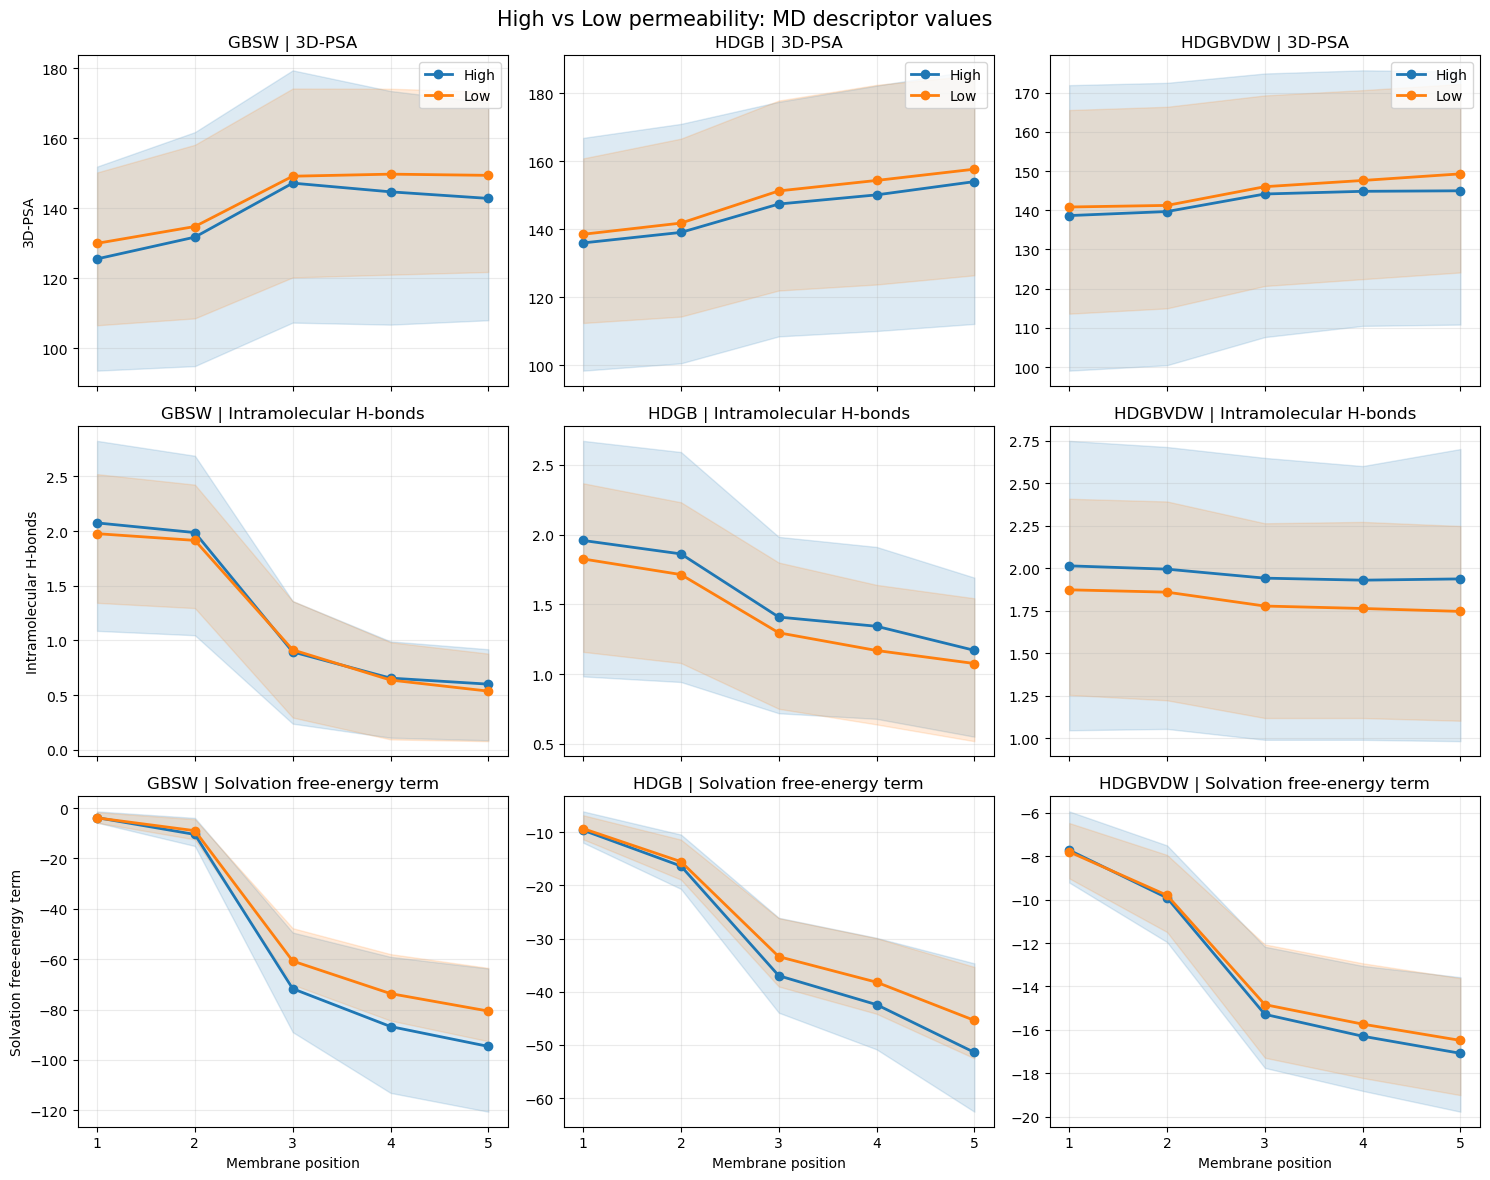

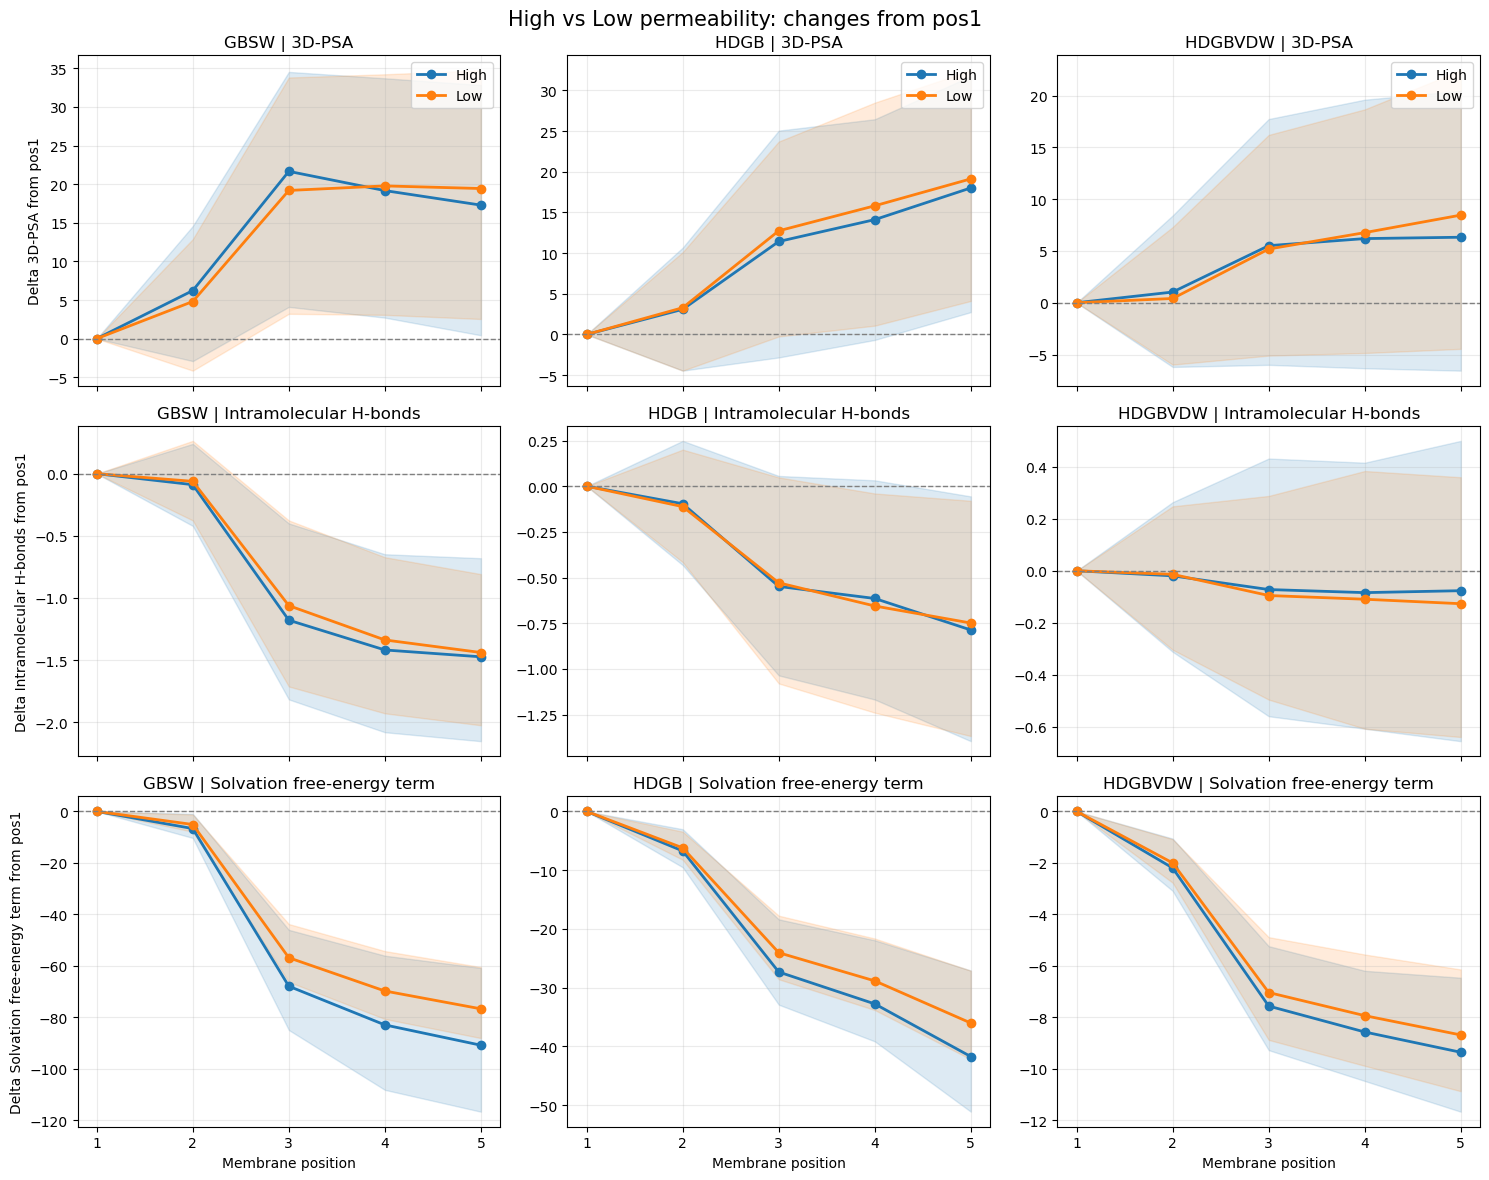

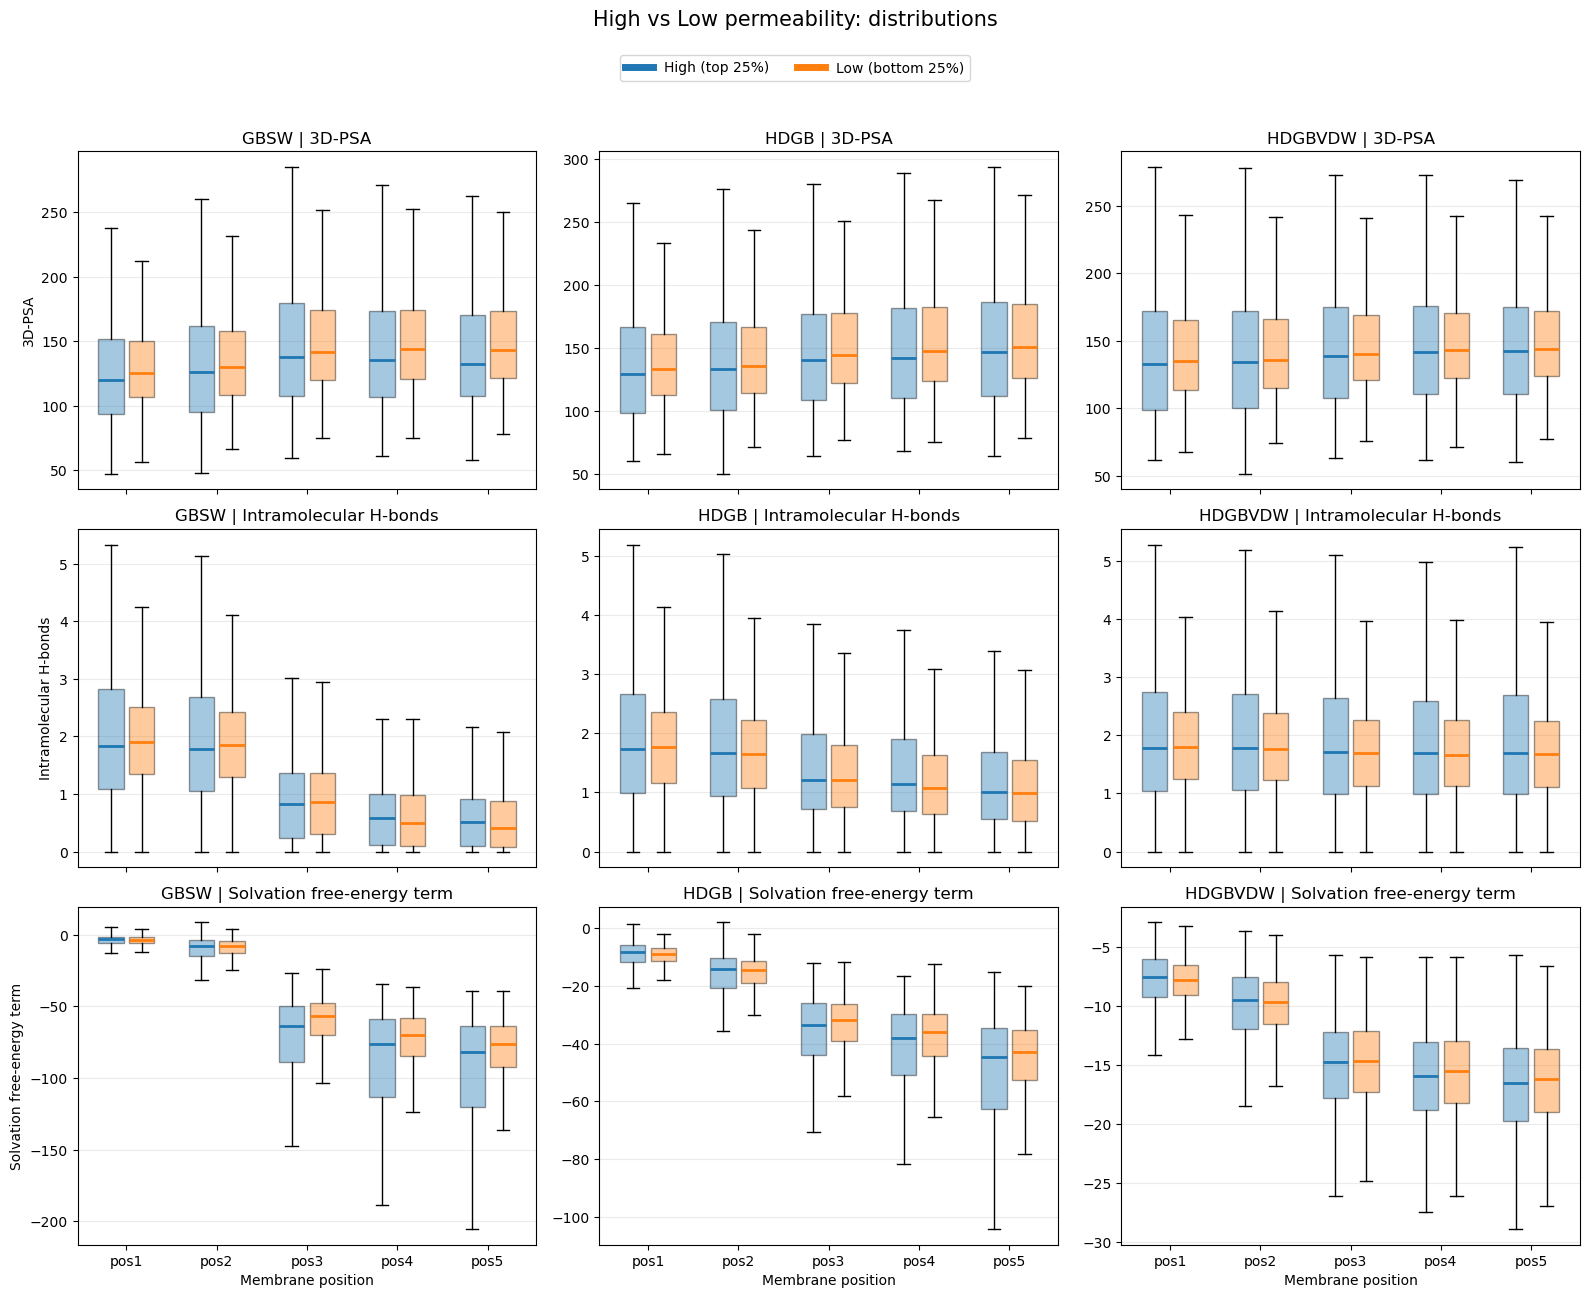


=== Change summary ===


,Model,Feature,Group,N,Delta_mean,Delta_median,Delta_std,Range_mean,Range_median
0,gbsw,IMHB,High,1619,-1.473,-1.264,1.196,1.981,1.736
1,gbsw,IMHB,Low,1609,-1.439,-1.392,0.957,1.907,1.832
2,gbsw,PSA3D,High,1619,17.285,16.080,27.139,42.355,36.963
3,gbsw,PSA3D,Low,1609,19.431,18.280,25.927,40.356,36.355
4,gbsw,Solv_Free,High,1619,-90.826,-79.076,37.489,93.913,81.259
5,gbsw,Solv_Free,Low,1609,-76.696,-72.190,22.552,78.792,74.585
6,hdgb,IMHB,High,1619,-0.787,-0.656,1.045,1.496,1.360
7,hdgb,IMHB,Low,1609,-0.749,-0.672,0.949,1.425,1.344
8,hdgb,PSA3D,High,1619,18.017,15.783,24.533,36.755,32.599
9,hdgb,PSA3D,Low,1609,19.133,16.559,24.046,35.380,31.031



Analysis completed.
Selected peptides: 3228
Output directory: /Users/teraimao/experiment/data/解析結果/membrane_position_analysis_top_bottom25


In [39]:
# ============================================================
# High 25% vs Low 25%
# Membrane-position analysis
#
# GBSW / HDGB / HDGBvdW
# PSA3D / IMHB / Solv_Free
#
# Mac JupyterLab
# ============================================================


# ============================================================
# 1. 設定
# ============================================================

BASE = "/Users/teraimao/experiment/data/解析結果"

OUT = os.path.join(
    BASE,
    "membrane_position_analysis_top_bottom25"
)

os.makedirs(OUT, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]
POSITIONS = [1, 2, 3, 4, 5]

FEATURES = {
    "PSA3D": {
        "base": "PSA3D_Avg",
        "label": "3D-PSA"
    },
    "IMHB": {
        "base": "HB_Avg",
        "label": "Intramolecular H-bonds"
    },
    "Solv_Free": {
        "base": "Solv_Free_Avg",
        "label": "Solvation free-energy term"
    }
}

GROUPS = ["High", "Low"]

# ============================================================
# 2. 必要な列
# ============================================================

required = ["ID", "PAMPA_logPm"]

for feature in FEATURES.values():
    for pos in POSITIONS:
        required.append(
            f"{feature['base']}_pos{pos}"
        )

required = list(dict.fromkeys(required))

# ============================================================
# 3. データ読み込み
# ============================================================

frames = {}

for model in MODELS:

    path = os.path.join(
        BASE,
        f"{model}_common_successID_"
        "baselineB_strictPAMPA_psa3d.csv"
    )

    df = pd.read_csv(path, low_memory=False)

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model}: Missing columns {missing}"
        )

    df = df[required].copy()

    for col in required:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    df = df.dropna(subset=required)
    df["ID"] = df["ID"].astype(int)

    if df["ID"].duplicated().any():
        raise ValueError(
            f"{model}: Duplicate IDs"
        )

    frames[model] = df.set_index("ID")

    print(model, len(df))

# ============================================================
# 4. 3モデル共通ID
# ============================================================

common_ids = set(frames["gbsw"].index)

for model in MODELS[1:]:
    common_ids &= set(frames[model].index)

common_ids = sorted(common_ids)

print("\nCommon IDs:", len(common_ids))

if len(common_ids) != 6390:
    print(
        "WARNING: Previous dataset had 6390 IDs"
    )

for model in MODELS:
    frames[model] = frames[model].loc[common_ids]

y = frames["gbsw"]["PAMPA_logPm"]

for model in MODELS[1:]:

    y_other = frames[model]["PAMPA_logPm"]

    if not np.allclose(
        y.to_numpy(),
        y_other.to_numpy(),
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model}: PAMPA values do not match"
        )

# ============================================================
# 5. 四分位点からHigh / Lowを定義
# ============================================================

q25 = y.quantile(0.25)
q75 = y.quantile(0.75)

print("\nPAMPA logPm quartiles")
print("Q25:", q25)
print("Median:", y.median())
print("Q75:", q75)

groups_all = pd.Series(
    np.where(
        y <= q25,
        "Low",
        np.where(
            y >= q75,
            "High",
            "Middle"
        )
    ),
    index=y.index,
    name="Group"
)

selected_ids = groups_all[
    groups_all.isin(GROUPS)
].index.tolist()

groups = groups_all.loc[selected_ids]
y_selected = y.loc[selected_ids]

for model in MODELS:
    frames[model] = frames[model].loc[selected_ids]

print("\nGroup counts")
print(groups.value_counts())
print("Total selected:", len(selected_ids))

group_info = pd.DataFrame({
    "ID": selected_ids,
    "PAMPA_logPm": y_selected.to_numpy(),
    "Group": groups.to_numpy()
})

group_info.to_csv(
    os.path.join(OUT, "selected_peptides.csv"),
    index=False
)

# ============================================================
# 6. 縦長データの作成
# ============================================================

long_list = []
delta_list = []

for model in MODELS:

    df = frames[model]

    for feature_name, config in FEATURES.items():

        cols = [
            f"{config['base']}_pos{p}"
            for p in POSITIONS
        ]

        values = df[cols].to_numpy(
            dtype=float
        )

        # 各位置の値
        for j, pos in enumerate(POSITIONS):

            long_list.append(pd.DataFrame({
                "ID": selected_ids,
                "Model": model,
                "Feature": feature_name,
                "Position": pos,
                "Group": groups.to_numpy(),
                "PAMPA_logPm": y_selected.to_numpy(),
                "Value": values[:, j]
            }))

        # 各ペプチドのpos1からの差
        for j, pos in enumerate(POSITIONS):

            delta_list.append(pd.DataFrame({
                "ID": selected_ids,
                "Model": model,
                "Feature": feature_name,
                "Position": pos,
                "Group": groups.to_numpy(),
                "PAMPA_logPm": y_selected.to_numpy(),
                "Delta_from_pos1": (
                    values[:, j] - values[:, 0]
                )
            }))

long_df = pd.concat(
    long_list,
    ignore_index=True
)

delta_df = pd.concat(
    delta_list,
    ignore_index=True
)

long_df.to_csv(
    os.path.join(OUT, "values_long.csv"),
    index=False
)

delta_df.to_csv(
    os.path.join(OUT, "deltas_from_pos1.csv"),
    index=False
)

# ============================================================
# 7. 平均・標準偏差・四分位点
# ============================================================

def make_summary(df, value_col):

    return (
        df.groupby(
            ["Model", "Feature", "Group", "Position"]
        )[value_col]
        .agg(
            N="count",
            Mean="mean",
            Std="std",
            Median="median",
            Q25=lambda x: x.quantile(0.25),
            Q75=lambda x: x.quantile(0.75)
        )
        .reset_index()
    )

summary = make_summary(
    long_df, "Value"
)

delta_summary = make_summary(
    delta_df, "Delta_from_pos1"
)

summary.to_csv(
    os.path.join(OUT, "position_summary.csv"),
    index=False
)

delta_summary.to_csv(
    os.path.join(OUT, "delta_summary.csv"),
    index=False
)

# ============================================================
# 8. 図1：絶対値の平均とIQR
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12),
    sharex=True
)

for i, (feature_name, config) in enumerate(
    FEATURES.items()
):

    for j, model in enumerate(MODELS):

        ax = axes[i, j]

        for group in GROUPS:

            sub = summary[
                (summary["Model"] == model)
                & (summary["Feature"] == feature_name)
                & (summary["Group"] == group)
            ].sort_values("Position")

            x = sub["Position"].to_numpy()
            mean = sub["Mean"].to_numpy()
            q25_vals = sub["Q25"].to_numpy()
            q75_vals = sub["Q75"].to_numpy()

            line, = ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=group
            )

            ax.fill_between(
                x,
                q25_vals,
                q75_vals,
                color=line.get_color(),
                alpha=0.15
            )

        ax.set_title(
            f"{model.upper()} | {config['label']}"
        )

        ax.set_xticks(POSITIONS)
        ax.grid(alpha=0.25)

        if j == 0:
            ax.set_ylabel(config["label"])

        if i == 2:
            ax.set_xlabel("Membrane position")

        if i == 0:
            ax.legend()

fig.suptitle(
    "High vs Low permeability: MD descriptor values",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "absolute_values_mean_IQR.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "absolute_values_mean_IQR.pdf")
)

plt.show()

# ============================================================
# 9. 図2：pos1基準の変化量
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12),
    sharex=True
)

for i, (feature_name, config) in enumerate(
    FEATURES.items()
):

    for j, model in enumerate(MODELS):

        ax = axes[i, j]

        for group in GROUPS:

            sub = delta_summary[
                (delta_summary["Model"] == model)
                & (delta_summary["Feature"] == feature_name)
                & (delta_summary["Group"] == group)
            ].sort_values("Position")

            x = sub["Position"].to_numpy()
            mean = sub["Mean"].to_numpy()

            line, = ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=group
            )

            ax.fill_between(
                x,
                sub["Q25"].to_numpy(),
                sub["Q75"].to_numpy(),
                color=line.get_color(),
                alpha=0.15
            )

        ax.axhline(
            0,
            linestyle="--",
            color="gray",
            linewidth=1
        )

        ax.set_title(
            f"{model.upper()} | {config['label']}"
        )

        ax.set_xticks(POSITIONS)
        ax.grid(alpha=0.25)

        if j == 0:
            ax.set_ylabel(
                f"Delta {config['label']} from pos1"
            )

        if i == 2:
            ax.set_xlabel("Membrane position")

        if i == 0:
            ax.legend()

fig.suptitle(
    "High vs Low permeability: changes from pos1",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "delta_from_pos1_mean_IQR.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "delta_from_pos1_mean_IQR.pdf")
)

plt.show()

# ============================================================
# 10. 図3：各位置の箱ひげ図
# ============================================================

colors = plt.rcParams[
    "axes.prop_cycle"
].by_key()["color"]

fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 13),
    sharex=True
)

for i, (feature_name, config) in enumerate(
    FEATURES.items()
):

    for j, model in enumerate(MODELS):

        ax = axes[i, j]

        sub = long_df[
            (long_df["Model"] == model)
            & (long_df["Feature"] == feature_name)
        ]

        for group, offset, color in [
            ("High", -0.17, colors[0]),
            ("Low", 0.17, colors[1])
        ]:

            box_data = [
                sub.loc[
                    (sub["Position"] == pos)
                    & (sub["Group"] == group),
                    "Value"
                ].to_numpy()
                for pos in POSITIONS
            ]

            bp = ax.boxplot(
                box_data,
                positions=[
                    pos + offset
                    for pos in POSITIONS
                ],
                widths=0.28,
                patch_artist=True,
                showfliers=False,
                manage_ticks=False
            )

            for patch in bp["boxes"]:
                patch.set_facecolor(color)
                patch.set_alpha(0.4)

            for median in bp["medians"]:
                median.set_color(color)
                median.set_linewidth(2)

        ax.set_title(
            f"{model.upper()} | {config['label']}"
        )

        ax.set_xticks(POSITIONS)
        ax.set_xticklabels(
            [f"pos{p}" for p in POSITIONS]
        )

        ax.grid(axis="y", alpha=0.25)

        if j == 0:
            ax.set_ylabel(config["label"])

        if i == 2:
            ax.set_xlabel("Membrane position")

legend = [
    Line2D(
        [0], [0],
        color=colors[0],
        linewidth=5,
        label="High (top 25%)"
    ),
    Line2D(
        [0], [0],
        color=colors[1],
        linewidth=5,
        label="Low (bottom 25%)"
    )
]

fig.legend(
    handles=legend,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.965)
)

fig.suptitle(
    "High vs Low permeability: distributions",
    fontsize=15,
    y=0.995
)

fig.tight_layout(
    rect=[0, 0, 1, 0.94]
)

fig.savefig(
    os.path.join(OUT, "absolute_values_boxplots.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "absolute_values_boxplots.pdf")
)

plt.show()

# ============================================================
# 11. pos5-pos1の変化量と値の範囲
# ============================================================

change_rows = []

for model in MODELS:

    df = frames[model]

    for feature_name, config in FEATURES.items():

        cols = [
            f"{config['base']}_pos{p}"
            for p in POSITIONS
        ]

        vals = df[cols].to_numpy(
            dtype=float
        )

        change_rows.append(pd.DataFrame({
            "ID": selected_ids,
            "Model": model,
            "Feature": feature_name,
            "Group": groups.to_numpy(),
            "PAMPA_logPm": y_selected.to_numpy(),
            "Delta_pos5_minus_pos1": (
                vals[:, 4] - vals[:, 0]
            ),
            "Range_max_minus_min": (
                vals.max(axis=1) - vals.min(axis=1)
            )
        }))

changes = pd.concat(
    change_rows,
    ignore_index=True
)

change_summary = (
    changes.groupby(
        ["Model", "Feature", "Group"]
    )
    .agg(
        N=("ID", "count"),
        Delta_mean=("Delta_pos5_minus_pos1", "mean"),
        Delta_median=("Delta_pos5_minus_pos1", "median"),
        Delta_std=("Delta_pos5_minus_pos1", "std"),
        Range_mean=("Range_max_minus_min", "mean"),
        Range_median=("Range_max_minus_min", "median")
    )
    .reset_index()
)

changes.to_csv(
    os.path.join(OUT, "per_peptide_changes.csv"),
    index=False
)

change_summary.to_csv(
    os.path.join(OUT, "change_summary.csv"),
    index=False
)

print("\n=== Change summary ===")
display(change_summary.round(3))

# ============================================================
# 12. 終了
# ============================================================

print("\nAnalysis completed.")
print("Selected peptides:", len(selected_ids))
print("Output directory:", OUT)

## まずMW・TPSA・LogPを確認するコード

MolWt                             TPSA                          MolLogP  \
      count     mean   median      std count     mean  median     std   count   
Group                                                                           
High   1619  982.800  941.225  263.576  1619  219.009  220.60  72.683    1619   
Low    1609  892.749  862.085  171.470  1609  207.342  186.12  49.534    1609   

                            
        mean median    std  
Group                       
High   2.730  2.842  0.875  
Low    2.497  2.305  1.137

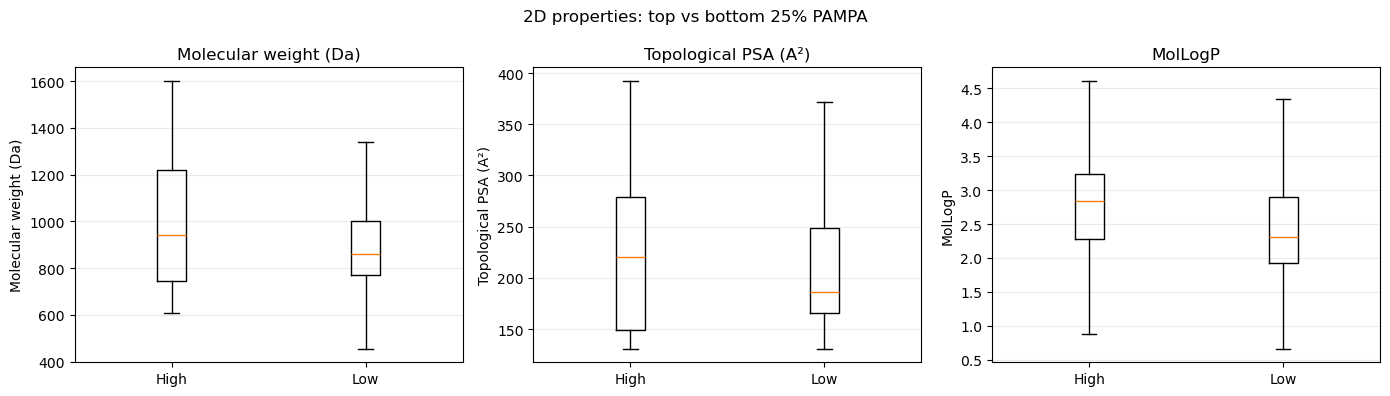

In [41]:

BASE = "/Users/teraimao/experiment/data/解析結果"
ORIGINAL = "/Users/teraimao/experiment/data/all_csv_data/this_is_CycPeptMPDB.csv"
OUT = os.path.join(BASE, "membrane_position_analysis_top_bottom25")

selected = pd.read_csv(
    os.path.join(OUT, "selected_peptides.csv")
)

original = pd.read_csv(
    ORIGINAL,
    usecols=["ID", "MolWt", "TPSA", "MolLogP", "Source"],
    low_memory=False
)

assert not original["ID"].duplicated().any()

df = selected.merge(
    original,
    on="ID",
    how="left",
    validate="one_to_one"
)

if df[["MolWt", "TPSA", "MolLogP"]].isna().any().any():
    raise ValueError("一部のIDで物性値が見つかりません")

properties = {
    "MolWt": "Molecular weight (Da)",
    "TPSA": "Topological PSA (A²)",
    "MolLogP": "MolLogP"
}

summary = df.groupby("Group")[
    list(properties.keys())
].agg(["count", "mean", "median", "std"])

display(summary.round(3))

summary.to_csv(
    os.path.join(OUT, "high_low_2D_property_summary.csv")
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (col, label) in zip(axes, properties.items()):
    high = df.loc[df["Group"] == "High", col]
    low = df.loc[df["Group"] == "Low", col]

    ax.boxplot(
        [high, low],
        labels=["High", "Low"],
        showfliers=False
    )
    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("2D properties: top vs bottom 25% PAMPA")
fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "high_low_2D_properties.png"),
    dpi=300
)

plt.show()

## 高・低透過性、3D-PSA/TPSAの膜位置依存性が異なるか

Group counts:
Group
High    1619
Low     1609
Name: count, dtype: int64

3モデル共通の有効ID: 6390


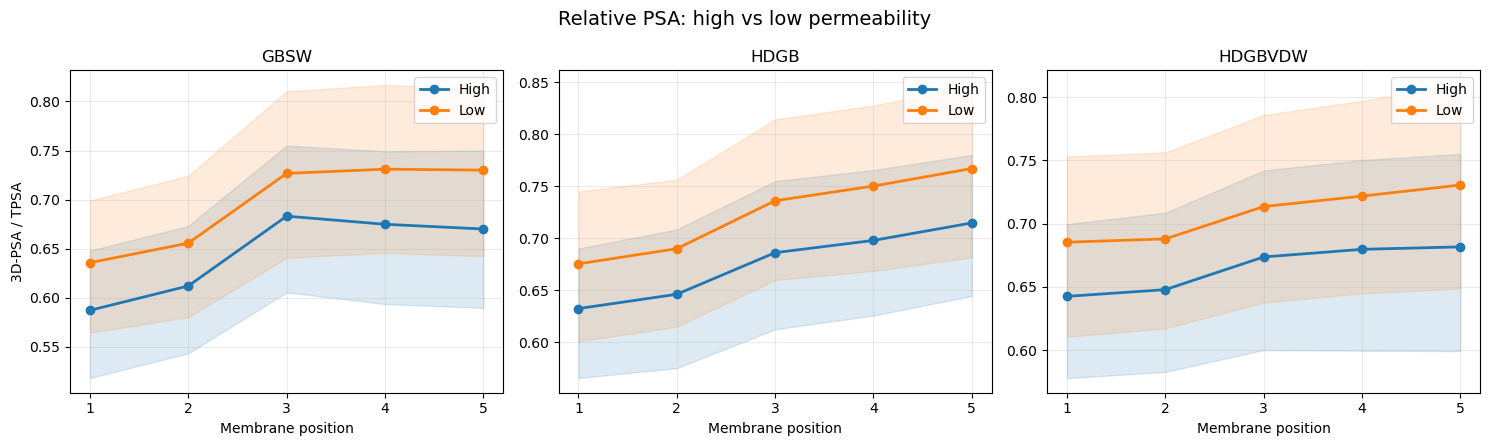

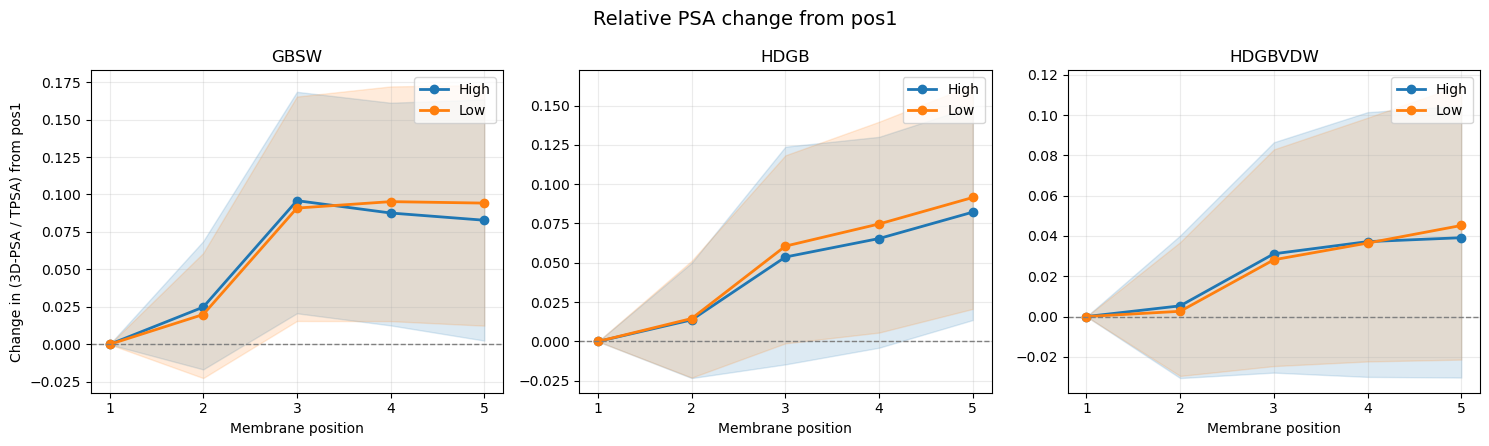

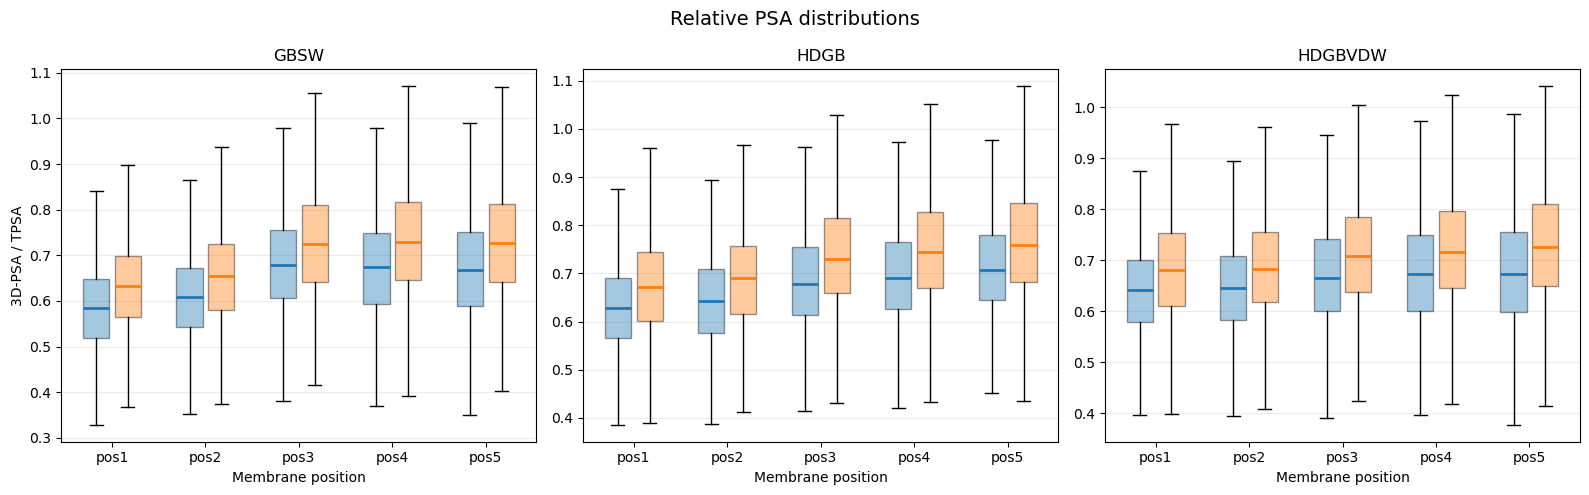


=== High - Low difference ===


,Model,Position,High_Mean,Low_Mean,High_Median,Low_Median,Mean_High_minus_Low
0,gbsw,1,0.5872,0.6358,0.5840,0.6337,-0.0485
1,gbsw,2,0.6121,0.6557,0.6089,0.6537,-0.0436
2,gbsw,3,0.6831,0.7267,0.6778,0.7248,-0.0436
3,gbsw,4,0.6749,0.7310,0.6743,0.7294,-0.0561
4,gbsw,5,0.6701,0.7300,0.6681,0.7269,-0.0600
5,hdgb,1,0.6325,0.6755,0.6288,0.6724,-0.0429
6,hdgb,2,0.6463,0.6901,0.6429,0.6912,-0.0438
7,hdgb,3,0.6862,0.7361,0.6786,0.7296,-0.0498
8,hdgb,4,0.6980,0.7502,0.6906,0.7447,-0.0522
9,hdgb,5,0.7148,0.7670,0.7060,0.7580,-0.0522



=== Spearman correlation with PAMPA ===


,Model,Position,N,Spearman_rho
0,gbsw,1,6390,-0.1874
1,gbsw,2,6390,-0.1703
2,gbsw,3,6390,-0.1551
3,gbsw,4,6390,-0.1863
4,gbsw,5,6390,-0.1997
5,hdgb,1,6390,-0.1693
6,hdgb,2,6390,-0.1802
7,hdgb,3,6390,-0.1888
8,hdgb,4,6390,-0.1945
9,hdgb,5,6390,-0.1954



Analysis completed!
Output directory: /Users/teraimao/experiment/data/解析結果/membrane_position_analysis_top_bottom25/relative_PSA_analysis


In [42]:
# ============================================================
# 3D-PSA / TPSA の膜位置依存性
# High 25% vs Low 25%
#
# GBSW / HDGB / HDGBvdW
# Mac JupyterLab
# ============================================================


# ------------------------------------------------------------
# 1. パス・設定
# ------------------------------------------------------------

BASE = "/Users/teraimao/experiment/data/解析結果"

ORIGINAL = (
    "/Users/teraimao/experiment/data/all_csv_data/"
    "this_is_CycPeptMPDB.csv"
)

PREVIOUS = os.path.join(
    BASE, "membrane_position_analysis_top_bottom25"
)

OUT = os.path.join(
    PREVIOUS, "relative_PSA_analysis"
)

os.makedirs(OUT, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]
POSITIONS = [1, 2, 3, 4, 5]

COLORS = {
    "High": "tab:blue",
    "Low": "tab:orange"
}

# ------------------------------------------------------------
# 2. 前回と同じ高・低透過性群を読み込む
# ------------------------------------------------------------

selected = pd.read_csv(
    os.path.join(PREVIOUS, "selected_peptides.csv")
)

selected["ID"] = pd.to_numeric(
    selected["ID"], errors="raise"
).astype(int)

assert selected["ID"].is_unique
assert set(selected["Group"]) == {"High", "Low"}

print("Group counts:")
print(selected["Group"].value_counts())

# ------------------------------------------------------------
# 3. 元データからTPSAを取得
# ------------------------------------------------------------

original = pd.read_csv(
    ORIGINAL,
    usecols=["ID", "TPSA"],
    low_memory=False
)

original["ID"] = pd.to_numeric(
    original["ID"], errors="coerce"
)

original["TPSA"] = pd.to_numeric(
    original["TPSA"], errors="coerce"
)

original = original.dropna(subset=["ID"])
original["ID"] = original["ID"].astype(int)

if original["ID"].duplicated().any():
    raise ValueError("元データに重複IDがあります")

# TPSAは正の値でなければ比率を計算できない
original.loc[
    original["TPSA"] <= 0, "TPSA"
] = np.nan

# ------------------------------------------------------------
# 4. 3モデルのPSA3Dを読み込む
# ------------------------------------------------------------

psa_cols = [
    f"PSA3D_Avg_pos{p}"
    for p in POSITIONS
]

model_frames = {}

for model in MODELS:

    filename = (
        f"{model}_common_successID_"
        "baselineB_strictPAMPA_psa3d.csv"
    )

    path = os.path.join(BASE, filename)

    df = pd.read_csv(
        path,
        usecols=["ID"] + psa_cols,
        low_memory=False
    )

    df["ID"] = pd.to_numeric(
        df["ID"], errors="coerce"
    )

    df = df.dropna(subset=["ID"]).copy()
    df["ID"] = df["ID"].astype(int)

    if df["ID"].duplicated().any():
        raise ValueError(f"{model}: 重複IDがあります")

    for col in psa_cols:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    model_frames[model] = df.set_index("ID")

# ------------------------------------------------------------
# 5. 全3モデル共通の有効IDを確認
# ------------------------------------------------------------

common_ids = set(original.loc[
    original["TPSA"].notna(), "ID"
])

for model in MODELS:
    valid = model_frames[model].dropna(
        subset=psa_cols
    ).index
    common_ids &= set(valid)

print("\n3モデル共通の有効ID:", len(common_ids))

# High/Low以外のIDも含めた全体のPAMPA相関に利用
# PAMPA_logPmは前回の学習用GBSW CSVから取得
gbsw_path = os.path.join(
    BASE,
    "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv"
)

targets = pd.read_csv(
    gbsw_path,
    usecols=["ID", "PAMPA_logPm"]
)

targets["ID"] = pd.to_numeric(
    targets["ID"], errors="coerce"
)
targets["PAMPA_logPm"] = pd.to_numeric(
    targets["PAMPA_logPm"], errors="coerce"
)

targets = targets.dropna(
    subset=["ID", "PAMPA_logPm"]
).copy()

targets["ID"] = targets["ID"].astype(int)

if targets["ID"].duplicated().any():
    raise ValueError("目的変数のIDが重複しています")

common_ids &= set(targets["ID"])
common_ids = sorted(common_ids)

if len(common_ids) != 6390:
    print(
        "注意: 6390件と一致しません。"
        " 欠損TPSA・PSA3Dを確認してください。"
    )

# ------------------------------------------------------------
# 6. 解析用データの作成
# ------------------------------------------------------------

base_df = (
    targets.set_index("ID")
    .loc[common_ids]
    .join(original.set_index("ID")[["TPSA"]])
)

group_map = selected.set_index("ID")["Group"]

base_df["Group"] = (
    base_df.index.to_series()
    .map(group_map)
    .fillna("Middle")
)

long_list = []

for model in MODELS:

    df = (
        base_df.join(
            model_frames[model].loc[common_ids, psa_cols]
        )
        .copy()
    )

    for pos in POSITIONS:

        psa_col = f"PSA3D_Avg_pos{pos}"

        part = pd.DataFrame({
            "ID": df.index,
            "Model": model,
            "Position": pos,
            "Group": df["Group"].values,
            "PAMPA_logPm": df["PAMPA_logPm"].values,
            "TPSA": df["TPSA"].values,
            "PSA3D": df[psa_col].values,
        })

        part["Relative_PSA"] = (
            part["PSA3D"] / part["TPSA"]
        )

        long_list.append(part)

all_long = pd.concat(
    long_list, ignore_index=True
)

all_long.to_csv(
    os.path.join(OUT, "relative_PSA_all_peptides.csv"),
    index=False
)

# High / Low だけを図示
plot_df = all_long[
    all_long["Group"].isin(["High", "Low"])
].copy()

# ------------------------------------------------------------
# 7. pos1を基準とした変化量
# ------------------------------------------------------------

reference = (
    all_long[all_long["Position"] == 1]
    [["ID", "Model", "Relative_PSA"]]
    .rename(columns={
        "Relative_PSA": "Relative_PSA_pos1"
    })
)

all_long = all_long.merge(
    reference,
    on=["ID", "Model"],
    how="left",
    validate="many_to_one"
)

all_long["Delta_from_pos1"] = (
    all_long["Relative_PSA"]
    - all_long["Relative_PSA_pos1"]
)

plot_df = all_long[
    all_long["Group"].isin(["High", "Low"])
].copy()

# ------------------------------------------------------------
# 8. 集計関数
# ------------------------------------------------------------

def summarize(data, value_col):

    return (
        data.groupby(
            ["Model", "Group", "Position"]
        )[value_col]
        .agg(
            N="count",
            Mean="mean",
            Median="median",
            Std="std",
            Q25=lambda s: s.quantile(0.25),
            Q75=lambda s: s.quantile(0.75),
        )
        .reset_index()
    )

summary = summarize(
    plot_df, "Relative_PSA"
)

delta_summary = summarize(
    plot_df, "Delta_from_pos1"
)

summary.to_csv(
    os.path.join(OUT, "relative_PSA_summary.csv"),
    index=False
)

delta_summary.to_csv(
    os.path.join(OUT, "relative_PSA_delta_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 9. 図1：3D-PSA/TPSAの平均とIQR
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True
)

for ax, model in zip(axes, MODELS):

    for group in ["High", "Low"]:

        sub = summary[
            (summary["Model"] == model)
            & (summary["Group"] == group)
        ].sort_values("Position")

        x = sub["Position"].to_numpy()
        mean = sub["Mean"].to_numpy()

        ax.plot(
            x, mean,
            marker="o",
            linewidth=2,
            color=COLORS[group],
            label=group
        )

        ax.fill_between(
            x,
            sub["Q25"].to_numpy(),
            sub["Q75"].to_numpy(),
            color=COLORS[group],
            alpha=0.15
        )

    ax.set_title(model.upper())
    ax.set_xticks(POSITIONS)
    ax.set_xlabel("Membrane position")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("3D-PSA / TPSA")

fig.suptitle(
    "Relative PSA: high vs low permeability",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "relative_PSA_mean_IQR.png"),
    dpi=300
)

fig.savefig(
    os.path.join(OUT, "relative_PSA_mean_IQR.pdf")
)

plt.show()

# ------------------------------------------------------------
# 10. 図2：pos1基準の比率変化
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True
)

for ax, model in zip(axes, MODELS):

    for group in ["High", "Low"]:

        sub = delta_summary[
            (delta_summary["Model"] == model)
            & (delta_summary["Group"] == group)
        ].sort_values("Position")

        ax.plot(
            sub["Position"],
            sub["Mean"],
            marker="o",
            linewidth=2,
            color=COLORS[group],
            label=group
        )

        ax.fill_between(
            sub["Position"].to_numpy(),
            sub["Q25"].to_numpy(),
            sub["Q75"].to_numpy(),
            color=COLORS[group],
            alpha=0.15
        )

    ax.axhline(
        0,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.set_title(model.upper())
    ax.set_xticks(POSITIONS)
    ax.set_xlabel("Membrane position")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel(
    "Change in (3D-PSA / TPSA) from pos1"
)

fig.suptitle(
    "Relative PSA change from pos1",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "relative_PSA_delta_from_pos1.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 11. 図3：位置ごとの分布
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharex=True
)

for ax, model in zip(axes, MODELS):

    sub = plot_df[
        plot_df["Model"] == model
    ]

    for group, offset in [
        ("High", -0.17),
        ("Low", 0.17)
    ]:

        values = [
            sub.loc[
                (sub["Group"] == group)
                & (sub["Position"] == pos),
                "Relative_PSA"
            ].dropna().to_numpy()
            for pos in POSITIONS
        ]

        bp = ax.boxplot(
            values,
            positions=[
                p + offset for p in POSITIONS
            ],
            widths=0.28,
            patch_artist=True,
            showfliers=False,
            manage_ticks=False
        )

        for patch in bp["boxes"]:
            patch.set_facecolor(COLORS[group])
            patch.set_alpha(0.4)

        for median in bp["medians"]:
            median.set_color(COLORS[group])
            median.set_linewidth(2)

    ax.set_title(model.upper())
    ax.set_xticks(POSITIONS)
    ax.set_xticklabels(
        [f"pos{p}" for p in POSITIONS]
    )
    ax.set_xlabel("Membrane position")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("3D-PSA / TPSA")

fig.suptitle(
    "Relative PSA distributions",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    os.path.join(OUT, "relative_PSA_boxplots.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 12. High - Low の群間差を算出
# ------------------------------------------------------------

pivot = summary.pivot(
    index=["Model", "Position"],
    columns="Group",
    values=["Mean", "Median"]
)

comparison = pd.DataFrame({
    "High_Mean": pivot[("Mean", "High")],
    "Low_Mean": pivot[("Mean", "Low")],
    "High_Median": pivot[("Median", "High")],
    "Low_Median": pivot[("Median", "Low")],
})

comparison["Mean_High_minus_Low"] = (
    comparison["High_Mean"]
    - comparison["Low_Mean"]
)

comparison = comparison.reset_index()

comparison.to_csv(
    os.path.join(OUT, "relative_PSA_group_difference.csv"),
    index=False
)

print("\n=== High - Low difference ===")
display(comparison.round(4))

# ------------------------------------------------------------
# 13. 全6390件でPAMPAとのSpearman相関
# ------------------------------------------------------------

correlations = []

for (model, pos), sub in all_long.groupby(
    ["Model", "Position"]
):

    r = sub["Relative_PSA"].corr(
        sub["PAMPA_logPm"],
        method="spearman"
    )

    correlations.append({
        "Model": model,
        "Position": pos,
        "N": len(sub),
        "Spearman_rho": r
    })

corr_df = pd.DataFrame(correlations)

corr_df.to_csv(
    os.path.join(OUT, "relative_PSA_PAMPA_correlation.csv"),
    index=False
)

print("\n=== Spearman correlation with PAMPA ===")
display(corr_df.round(4))

print("\nAnalysis completed!")
print("Output directory:", OUT)

## 出典別

Prediction CSV columns:
['seed', 'Model', 'ID', 'Source', 'Observed', 'Morgan_pred', 'MD_pred', 'Ensemble_pred', 'Alpha']

Models:
Model
gbsw       25560
hdgb       25560
hdgbvdw    25560
Name: count, dtype: int64

Seeds:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Source column OK
Source
2020_Townsend             34026
2021_Kelly                17484
2013_CHUGAI                9240
2016_Furukawa              7536
2024_Faris                 2541
2022_Bhardwaj              1629
2018_Naylor                 804
2024_Koch                   519
2022_Taechalertpaisarn      435
2015_Wang                   420
Name: count, dtype: int64

=== Source performance (20 seeds) ===


,Model,Source,N_seeds,N_test_mean,R_mean,R_std,R2_mean,R2_std,MAE_mean,MAE_std,RMSE_mean,RMSE_std,PAMPA_std_mean
0,gbsw,2013_CHUGAI,20,154.0,0.3931,0.0787,-0.0246,0.1445,0.4343,0.0292,0.5568,0.0442,0.5542
11,hdgb,2013_CHUGAI,20,154.0,0.3400,0.0539,-0.1245,0.1306,0.4615,0.0264,0.5835,0.0358,0.5542
22,hdgbvdw,2013_CHUGAI,20,154.0,0.3524,0.0572,-0.1020,0.1544,0.4490,0.0303,0.5771,0.0402,0.5542
2,gbsw,2016_Furukawa,20,125.6,0.6350,0.0472,0.3296,0.0409,0.6330,0.0436,0.8144,0.0586,0.9985
13,hdgb,2016_Furukawa,20,125.6,0.6580,0.0573,0.3477,0.0524,0.6236,0.0462,0.8031,0.0626,0.9985
24,hdgbvdw,2016_Furukawa,20,125.6,0.6790,0.0617,0.3678,0.0529,0.6086,0.0419,0.7904,0.0585,0.9985
5,gbsw,2020_Townsend,20,567.1,0.5494,0.0289,0.2899,0.0268,0.3289,0.0116,0.4177,0.0140,0.4962
16,hdgb,2020_Townsend,20,567.1,0.5326,0.0283,0.2736,0.0242,0.3331,0.0113,0.4225,0.0144,0.4962
27,hdgbvdw,2020_Townsend,20,567.1,0.5524,0.0314,0.2914,0.0274,0.3303,0.0098,0.4172,0.0142,0.4962
6,gbsw,2021_Kelly,20,291.4,0.5628,0.0391,0.3100,0.0430,0.4279,0.0187,0.5552,0.0286,0.6703


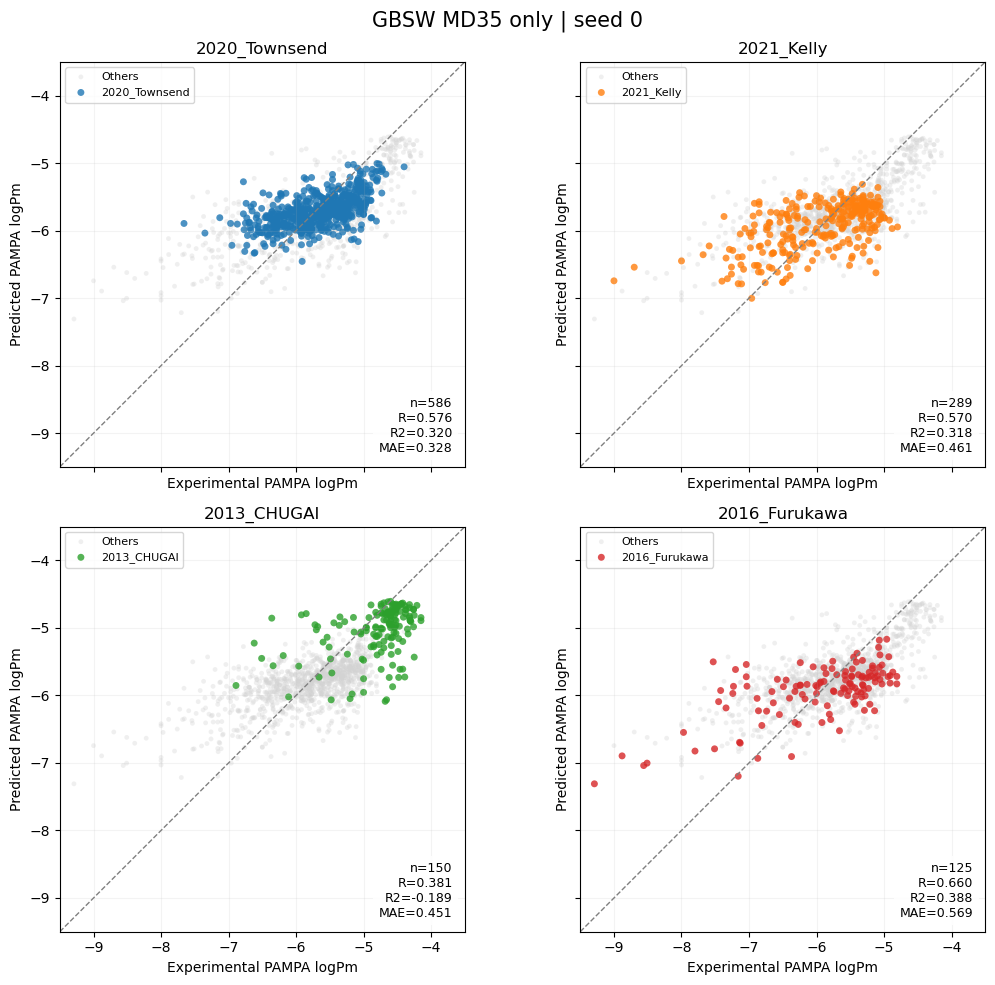

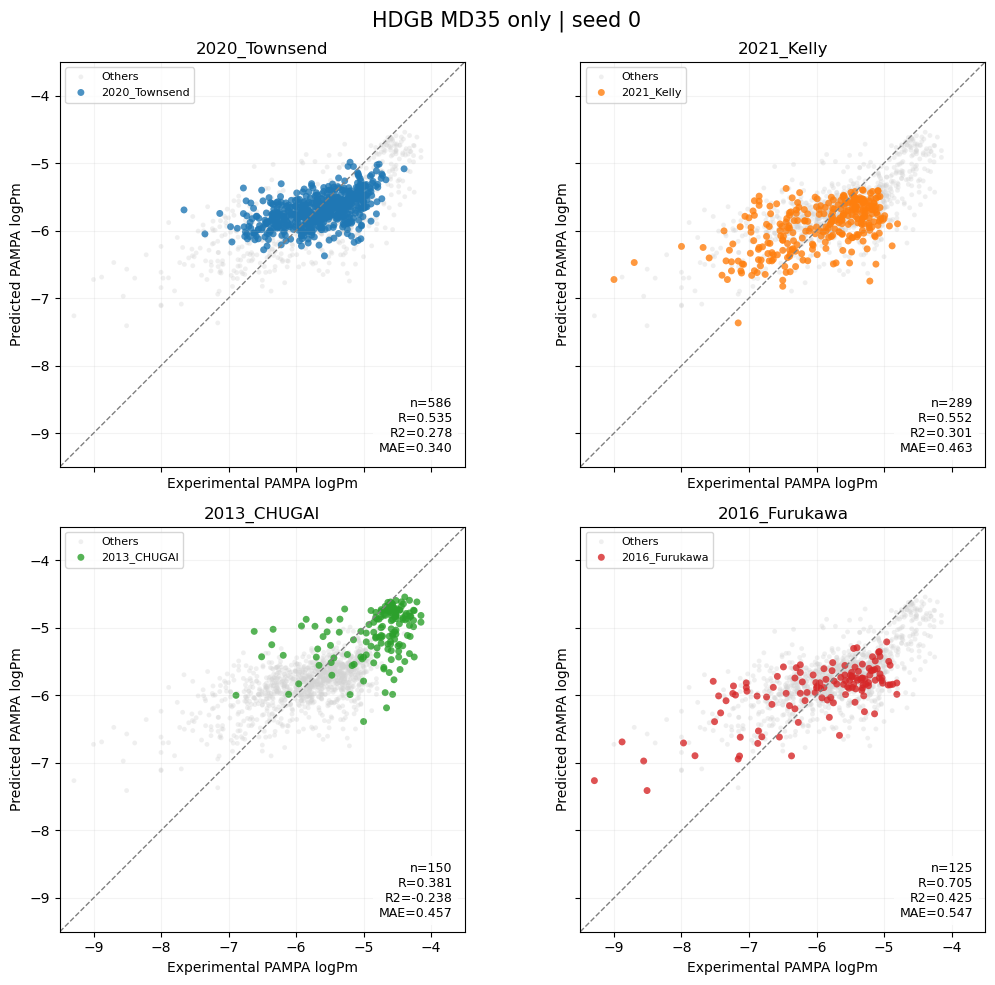

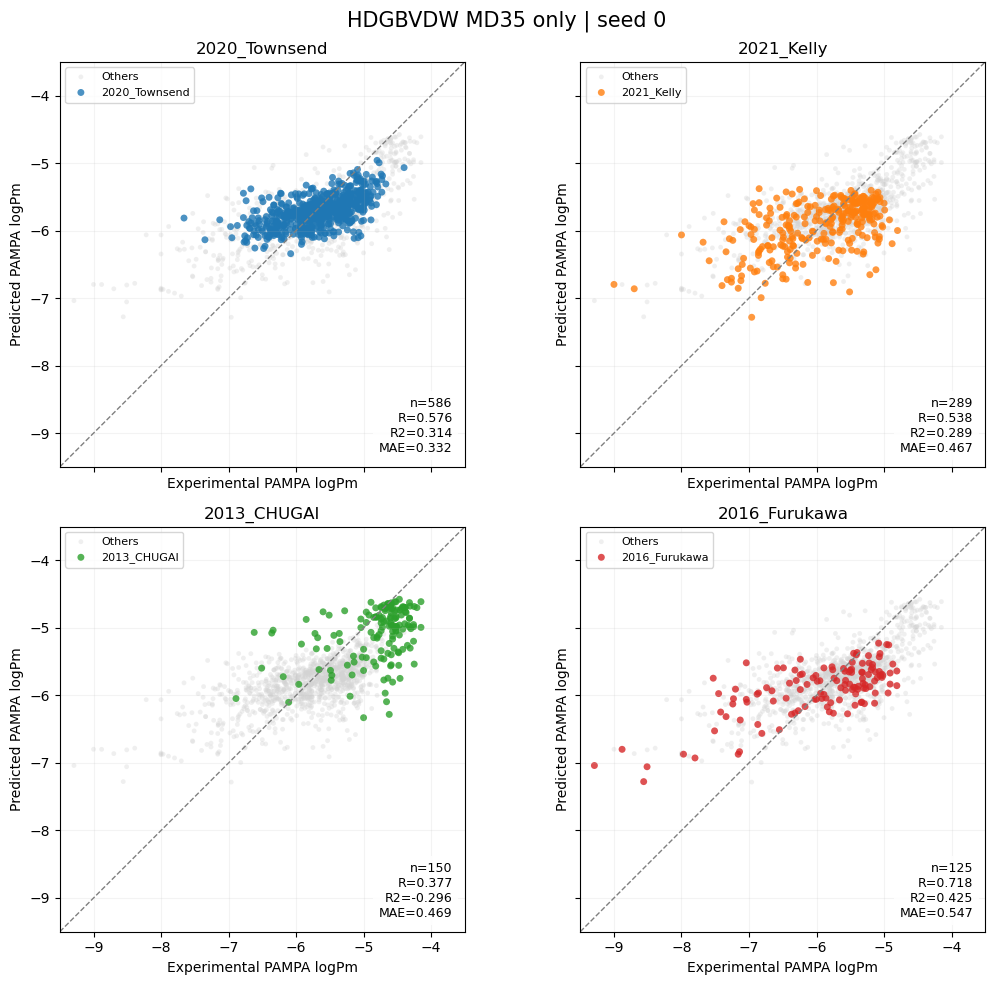

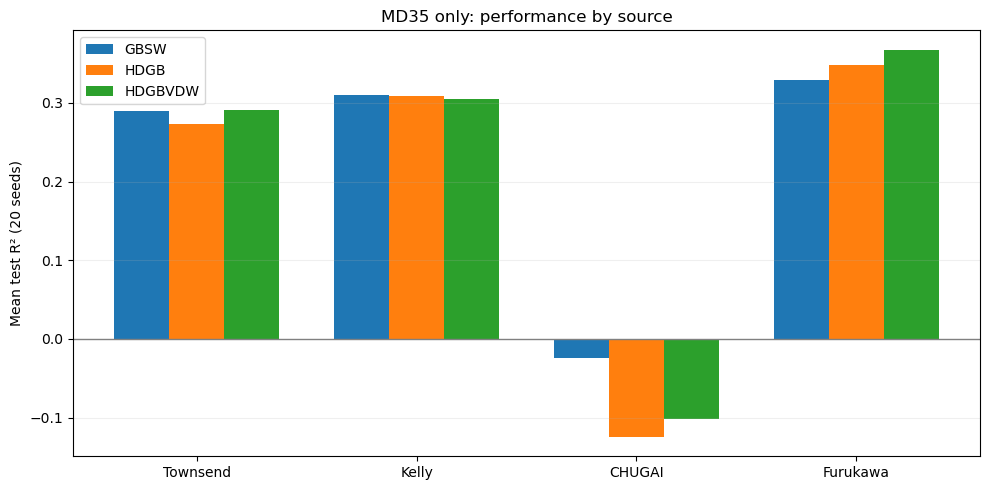


=== Best MD model for each source ===


,Source,Model,N_test_mean,R_mean,R2_mean,MAE_mean,RMSE_mean
0,2013_CHUGAI,gbsw,154.0,0.3931,-0.0246,0.4343,0.5568
24,2016_Furukawa,hdgbvdw,125.6,0.6790,0.3678,0.6086,0.7904
27,2020_Townsend,hdgbvdw,567.1,0.5524,0.2914,0.3303,0.4172
6,2021_Kelly,gbsw,291.4,0.5628,0.3100,0.4279,0.5552



Analysis completed!
Output: /Users/teraimao/experiment/data/解析結果/MD35_only_by_source


In [45]:
# ============================================================
# MD35 ONLY: Prediction performance by source
#
# GBSW / HDGB / HDGBvdW
# 20 seeds metrics + seed 0 scatter plots
#
# Mac JupyterLab
# No new RF training required
# ============================================================


# ============================================================
# 1. パス・設定
# ============================================================

PRED_PATH = os.path.expanduser(
    "~/Downloads/ensemble_20seeds_by_source/"
    "test_predictions_all_seeds.csv"
)

ORIGINAL = (
    "/Users/teraimao/experiment/data/all_csv_data/"
    "this_is_CycPeptMPDB.csv"
)

OUT = (
    "/Users/teraimao/experiment/data/解析結果/"
    "MD35_only_by_source"
)

os.makedirs(OUT, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]

# 散布図に表示するseed
PLOT_SEED = 0

# 注目する4つの出典
SOURCES = [
    "2020_Townsend",
    "2021_Kelly",
    "2013_CHUGAI",
    "2016_Furukawa"
]

# 出典別の指標を計算する最低件数
MIN_TEST_N = 10

# ============================================================
# 2. 保存済み予測結果の読み込み
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    low_memory=False
)

print("Prediction CSV columns:")
print(pred.columns.tolist())

# よくある列名の表記ゆれに対応
rename = {}

aliases = {
    "Seed": ["Seed", "seed", "random_state"],
    "Model": ["Model", "model"],
    "ID": ["ID", "id"],
    "Observed": [
        "Observed", "observed",
        "Actual", "y_true"
    ],
    "MD_pred": [
        "MD_pred", "md_pred",
        "MD_only_pred", "Prediction_MD"
    ]
}

for standard, candidates in aliases.items():
    if standard in pred.columns:
        continue

    found = next(
        (c for c in candidates if c in pred.columns),
        None
    )

    if found is not None:
        rename[found] = standard

pred = pred.rename(columns=rename)

required = [
    "Seed", "Model", "ID",
    "Observed", "MD_pred"
]

missing = [
    c for c in required
    if c not in pred.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Available: {pred.columns.tolist()}"
    )

pred["Model"] = (
    pred["Model"].astype(str).str.lower()
)

for col in ["Seed", "ID", "Observed", "MD_pred"]:
    pred[col] = pd.to_numeric(
        pred[col], errors="raise"
    )

pred["Seed"] = pred["Seed"].astype(int)
pred["ID"] = pred["ID"].astype(int)

pred = pred[
    pred["Model"].isin(MODELS)
].copy()

# 念のため確認
if pred.duplicated(["Seed", "Model", "ID"]).any():
    raise ValueError(
        "同じseed、model、IDの予測が重複しています"
    )

print("\nModels:")
print(pred["Model"].value_counts())

print("\nSeeds:")
print(sorted(pred["Seed"].unique()))

# ============================================================
# 3. 元データからSourceを取得
# ============================================================
# ============================================================
# 3. 元データからSourceを取得（修正版）
# ============================================================

original = pd.read_csv(
    ORIGINAL,
    usecols=["ID", "Source"],
    low_memory=False
)

original["ID"] = pd.to_numeric(
    original["ID"], errors="raise"
).astype(int)

if original["ID"].duplicated().any():
    raise ValueError("元データ内でIDが重複しています")

original["Source"] = (
    original["Source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# 予測CSVにSourceが含まれている場合、
# 重複を避けるため一度削除して元データから結合
pred = pred.drop(
    columns=["Source", "Source_x", "Source_y"],
    errors="ignore"
)

df = pred.merge(
    original,
    on="ID",
    how="left",
    validate="many_to_one"
)

if df["Source"].isna().any():
    raise ValueError(
        "元データでSourceが見つからないIDがあります"
    )

print("Source column OK")
print(df["Source"].value_counts().head(10))

# ============================================================
# 4. 評価関数
# ============================================================

def calculate_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    r = np.corrcoef(y_true, y_pred)[0, 1]

    return {
        "R": r,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "PAMPA_std": np.std(y_true, ddof=1)
    }

# ============================================================
# 5. 出典別の性能（20 seeds）
# ============================================================

rows = []

for (seed, model, source), sub in df.groupby(
    ["Seed", "Model", "Source"]
):

    if len(sub) < MIN_TEST_N:
        continue

    score = calculate_metrics(
        sub["Observed"],
        sub["MD_pred"]
    )

    rows.append({
        "Seed": seed,
        "Model": model,
        "Source": source,
        "N_test": len(sub),
        **score
    })

metrics = pd.DataFrame(rows)

metrics.to_csv(
    os.path.join(
        OUT, "MD35_source_metrics_by_seed.csv"
    ),
    index=False
)

summary = (
    metrics.groupby(["Model", "Source"])
    .agg(
        N_seeds=("Seed", "nunique"),
        N_test_mean=("N_test", "mean"),
        R_mean=("R", "mean"),
        R_std=("R", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        PAMPA_std_mean=("PAMPA_std", "mean")
    )
    .reset_index()
)

summary.to_csv(
    os.path.join(
        OUT, "MD35_source_summary_20seeds.csv"
    ),
    index=False
)

print("\n=== Source performance (20 seeds) ===")

display(
    summary[
        summary["Source"].isin(SOURCES)
    ].sort_values(
        ["Source", "Model"]
    ).round(4)
)

# ============================================================
# 6. 論文形式の散布図
#    1モデルにつき4パネル
# ============================================================

COLORS = {
    "2020_Townsend": "tab:blue",
    "2021_Kelly": "tab:orange",
    "2013_CHUGAI": "tab:green",
    "2016_Furukawa": "tab:red"
}

# 全モデル・全出典で共通の軸範囲
all_values = pd.concat(
    [df["Observed"], df["MD_pred"]]
)

lo = np.floor(all_values.min() * 2) / 2
hi = np.ceil(all_values.max() * 2) / 2

for model in MODELS:

    sub = df[
        (df["Model"] == model)
        & (df["Seed"] == PLOT_SEED)
    ].copy()

    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 10),
        sharex=True,
        sharey=True
    )

    for ax, source in zip(axes.flat, SOURCES):

        target = sub[
            sub["Source"] == source
        ]

        others = sub[
            sub["Source"] != source
        ]

        # その他の出典：灰色
        ax.scatter(
            others["Observed"],
            others["MD_pred"],
            s=12,
            color="lightgray",
            alpha=0.35,
            edgecolors="none",
            label="Others",
            rasterized=True
        )

        # 注目する出典：カラー
        ax.scatter(
            target["Observed"],
            target["MD_pred"],
            s=25,
            color=COLORS[source],
            alpha=0.8,
            edgecolors="none",
            label=source,
            rasterized=True
        )

        # 理想予測 y=x
        ax.plot(
            [lo, hi],
            [lo, hi],
            "--",
            color="gray",
            linewidth=1
        )

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect(
            "equal", adjustable="box"
        )

        # source単独のseed0指標
        if len(target) >= 2:

            score = calculate_metrics(
                target["Observed"],
                target["MD_pred"]
            )

            info = (
                f"n={len(target)}\n"
                f"R={score['R']:.3f}\n"
                f"R2={score['R2']:.3f}\n"
                f"MAE={score['MAE']:.3f}"
            )

        else:
            info = f"n={len(target)}"

        ax.text(
            0.97, 0.03,
            info,
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.85,
                edgecolor="none"
            )
        )

        ax.set_title(source)
        ax.set_xlabel(
            "Experimental PAMPA logPm"
        )
        ax.set_ylabel(
            "Predicted PAMPA logPm"
        )
        ax.legend(
            loc="upper left",
            fontsize=8,
            frameon=True
        )

        ax.grid(alpha=0.15)

    fig.suptitle(
        f"{model.upper()} MD35 only | seed {PLOT_SEED}",
        fontsize=15
    )

    fig.tight_layout()

    fig.savefig(
        os.path.join(
            OUT,
            f"{model}_MD35_source_scatter_seed{PLOT_SEED}.png"
        ),
        dpi=300
    )

    fig.savefig(
        os.path.join(
            OUT,
            f"{model}_MD35_source_scatter_seed{PLOT_SEED}.pdf"
        )
    )

    plt.show()

# ============================================================
# 7. 出典別の20 seeds平均R2を3モデルで比較
# ============================================================

plot_summary = summary[
    summary["Source"].isin(SOURCES)
].copy()

pivot = plot_summary.pivot(
    index="Source",
    columns="Model",
    values="R2_mean"
).reindex(SOURCES)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

x = np.arange(len(pivot))
width = 0.25

for i, model in enumerate(MODELS):

    ax.bar(
        x + (i - 1) * width,
        pivot[model],
        width=width,
        label=model.upper()
    )

ax.axhline(
    0,
    color="gray",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(
    [s.split("_", 1)[-1] for s in pivot.index]
)

ax.set_ylabel("Mean test R² (20 seeds)")
ax.set_title("MD35 only: performance by source")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUT, "MD35_source_R2_comparison.png"
    ),
    dpi=300
)

plt.show()

# ============================================================
# 8. 最良モデルの一覧
# ============================================================

best = (
    plot_summary.sort_values(
        "R2_mean", ascending=False
    )
    .drop_duplicates("Source")
    .sort_values("Source")
)

print("\n=== Best MD model for each source ===")

display(
    best[
        [
            "Source",
            "Model",
            "N_test_mean",
            "R_mean",
            "R2_mean",
            "MAE_mean",
            "RMSE_mean"
        ]
    ].round(4)
)

best.to_csv(
    os.path.join(
        OUT, "best_MD_model_by_source.csv"
    ),
    index=False
)

print("\nAnalysis completed!")
print("Output:", OUT)

In [17]:
# =========================
# 設定
# =========================

save_dir = "/Users/teraimao/experiment/data/解析結果"

cycpept_path = "/Users/teraimao/experiment/data/all_csv_data/this_is_CycPeptMPDB.csv"

model_files = {
    "gbsw": "gbsw_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgb": "hdgb_common_successID_baselineB_strictPAMPA_psa3d.csv",
    "hdgbvdw": "hdgbvdw_common_successID_baselineB_strictPAMPA_psa3d.csv",
}

id_col = "ID"
seq_col = "Sequence"
clean_seq_col = "Clean_Sequence"

# =========================
# 読み込み
# =========================

cy = pd.read_csv(cycpept_path, low_memory=False)

print("CycPeptMPDB shape:", cy.shape)
print("columns:")
print(list(cy.columns))

# ID確認
if id_col not in cy.columns:
    raise ValueError(f"{id_col} が this_is_CycPeptMPDB.csv にありません")

if seq_col not in cy.columns:
    raise ValueError(f"{seq_col} が this_is_CycPeptMPDB.csv にありません")

cy[id_col] = pd.to_numeric(cy[id_col], errors="coerce")
cy = cy.dropna(subset=[id_col]).copy()
cy[id_col] = cy[id_col].astype(int)

# Sequenceの欠損・空白処理
cy[seq_col] = cy[seq_col].astype(str).str.strip()

if clean_seq_col in cy.columns:
    cy[clean_seq_col] = cy[clean_seq_col].astype(str).str.strip()
else:
    print(f"WARNING: {clean_seq_col} がありません。Clean_Sequence衝突チェックはスキップします。")

# 使えそうな列を自動で拾う
possible_info_cols = [
    "PAMPA_logPm", "logPm", "LogP", "Permeability", "permeability",
    "Year", "year", "Publication_Year", "Reference", "reference",
    "PMID", "DOI", "Dataset", "Source", "source"
]

info_cols = [c for c in possible_info_cols if c in cy.columns]

print("\nInfo columns found:")
print(info_cols)

# =========================
# 各モデルの最終CSVのIDを読む
# =========================

final_ids_by_model = {}

for model, fname in model_files.items():
    path = os.path.join(save_dir, fname)
    df = pd.read_csv(path, low_memory=False)

    if id_col not in df.columns:
        raise ValueError(f"{model}: {id_col} がありません")

    df[id_col] = pd.to_numeric(df[id_col], errors="coerce")
    df = df.dropna(subset=[id_col]).copy()
    df[id_col] = df[id_col].astype(int)

    n_dup = df[id_col].duplicated().sum()
    ids = set(df[id_col].tolist())

    final_ids_by_model[model] = ids

    print("\n" + "=" * 80)
    print(model)
    print("rows:", len(df))
    print("unique IDs:", len(ids))
    print("duplicate IDs in final csv:", n_dup)

common_final_ids = sorted(set.intersection(*final_ids_by_model.values()))

print("\n" + "=" * 80)
print("common IDs across 3 final csvs:", len(common_final_ids))

# =========================
# 1. 元のSequenceで重複があるか：CycPeptMPDB全体
# =========================

seq_group_all = (
    cy
    .groupby(seq_col)
    .agg(
        n_rows_all=(id_col, "size"),
        n_unique_ids_all=(id_col, "nunique"),
        ids_all=(id_col, lambda x: ",".join(map(str, sorted(set(x))))),
    )
    .reset_index()
)

seq_dup_all = seq_group_all[seq_group_all["n_unique_ids_all"] > 1].copy()
seq_dup_all = seq_dup_all.sort_values(["n_unique_ids_all", seq_col], ascending=[False, True])

print("\n" + "=" * 80)
print("Original Sequence duplicates in whole CycPeptMPDB")
print("duplicated Sequence groups:", len(seq_dup_all))
print("rows included in duplicated groups:", seq_dup_all["n_rows_all"].sum())

display(seq_dup_all.head(30))

# =========================
# 2. 元のSequence重複のうち、最終CSVに残っているIDを見る
# =========================

status_rows = []

for model, final_ids in final_ids_by_model.items():
    for _, row in seq_dup_all.iterrows():
        seq = row[seq_col]
        sub = cy[cy[seq_col] == seq].copy()

        ids_all = sorted(sub[id_col].dropna().astype(int).unique().tolist())
        ids_in_final = sorted([i for i in ids_all if i in final_ids])

        status_rows.append({
            "Model": model,
            "Sequence": seq,
            "n_ids_all_same_Sequence": len(ids_all),
            "n_ids_in_final_csv": len(ids_in_final),
            "ids_all": ",".join(map(str, ids_all)),
            "ids_in_final_csv": ",".join(map(str, ids_in_final)),
        })

seq_dup_status = pd.DataFrame(status_rows)

print("\n" + "=" * 80)
print("Original Sequence duplicates and whether their IDs remain in final csvs")

display(
    seq_dup_status
    .sort_values(["Model", "n_ids_in_final_csv", "n_ids_all_same_Sequence"], ascending=[True, False, False])
    .head(50)
)

# =========================
# 3. GBSWに残っているIDだけで、元Sequence重複が残っているか
# =========================

for model, final_ids in final_ids_by_model.items():
    cy_in = cy[cy[id_col].isin(final_ids)].copy()

    dup_in = cy_in[cy_in.duplicated(subset=[seq_col], keep=False)].copy()

    print("\n" + "=" * 80)
    print(model)
    print("rows in final IDs linked to CycPeptMPDB:", len(cy_in))
    print("rows whose original Sequence is duplicated within final IDs:", len(dup_in))
    print("unique duplicated original Sequences within final IDs:", dup_in[seq_col].nunique())

    show_cols = [id_col, seq_col]
    if clean_seq_col in cy_in.columns:
        show_cols.append(clean_seq_col)
    show_cols += info_cols

    if len(dup_in) > 0:
        display(
            dup_in[show_cols]
            .sort_values([seq_col, id_col])
            .head(100)
        )

# =========================
# 4. Clean_Sequenceが違う元Sequenceを同じものに潰していないか
# =========================

if clean_seq_col in cy.columns:
    collision_rows = []

    for model, final_ids in final_ids_by_model.items():
        cy_in = cy[cy[id_col].isin(final_ids)].copy()

        clean_group = (
            cy_in
            .groupby(clean_seq_col)
            .agg(
                n_ids=(id_col, "nunique"),
                n_original_sequences=(seq_col, "nunique"),
                ids=(id_col, lambda x: ",".join(map(str, sorted(set(x))))),
                original_sequences=(seq_col, lambda x: " || ".join(sorted(set(map(str, x))))),
            )
            .reset_index()
        )

        collisions = clean_group[
            (clean_group["n_ids"] > 1) &
            (clean_group["n_original_sequences"] > 1)
        ].copy()

        collisions.insert(0, "Model", model)
        collision_rows.append(collisions)

    if len(collision_rows) > 0:
        clean_collisions = pd.concat(collision_rows, ignore_index=True)
    else:
        clean_collisions = pd.DataFrame()

    print("\n" + "=" * 80)
    print("Clean_Sequence collisions:")
    print("Different original Sequences collapsed into same Clean_Sequence")
    print("rows:", len(clean_collisions))

    if len(clean_collisions) > 0:
        display(
            clean_collisions
            .sort_values(["Model", "n_original_sequences", "n_ids"], ascending=[True, False, False])
            .head(100)
        )

# =========================
# 5. 共通6441 IDだけでも同じチェック
# =========================

cy_common = cy[cy[id_col].isin(common_final_ids)].copy()

print("\n" + "=" * 80)
print("Common IDs across 3 models check")
print("rows linked to CycPeptMPDB:", len(cy_common))

dup_common_seq = cy_common[cy_common.duplicated(subset=[seq_col], keep=False)].copy()

print("rows whose original Sequence is duplicated in common IDs:", len(dup_common_seq))
print("unique duplicated original Sequences in common IDs:", dup_common_seq[seq_col].nunique())

show_cols = [id_col, seq_col]
if clean_seq_col in cy_common.columns:
    show_cols.append(clean_seq_col)
show_cols += info_cols

if len(dup_common_seq) > 0:
    display(
        dup_common_seq[show_cols]
        .sort_values([seq_col, id_col])
        .head(100)
    )

if clean_seq_col in cy_common.columns:
    clean_group_common = (
        cy_common
        .groupby(clean_seq_col)
        .agg(
            n_ids=(id_col, "nunique"),
            n_original_sequences=(seq_col, "nunique"),
            ids=(id_col, lambda x: ",".join(map(str, sorted(set(x))))),
            original_sequences=(seq_col, lambda x: " || ".join(sorted(set(map(str, x))))),
        )
        .reset_index()
    )

    clean_collision_common = clean_group_common[
        (clean_group_common["n_ids"] > 1) &
        (clean_group_common["n_original_sequences"] > 1)
    ].copy()

    print("\nClean_Sequence collisions in common IDs:")
    print("rows:", len(clean_collision_common))

    if len(clean_collision_common) > 0:
        display(
            clean_collision_common
            .sort_values(["n_original_sequences", "n_ids"], ascending=[False, False])
            .head(100)
        )

# =========================
# 6. 保存
# =========================

out1 = os.path.join(save_dir, "check_original_sequence_duplicates_all_CycPeptMPDB.csv")
out2 = os.path.join(save_dir, "check_original_sequence_duplicates_status_in_final_csvs.csv")
out3 = os.path.join(save_dir, "check_clean_sequence_collisions_in_final_csvs.csv")
out4 = os.path.join(save_dir, "check_commonID_original_sequence_duplicates.csv")
out5 = os.path.join(save_dir, "check_commonID_clean_sequence_collisions.csv")

seq_dup_all.to_csv(out1, index=False)
seq_dup_status.to_csv(out2, index=False)

if clean_seq_col in cy.columns and "clean_collisions" in globals():
    clean_collisions.to_csv(out3, index=False)

dup_common_seq.to_csv(out4, index=False)

if clean_seq_col in cy_common.columns and "clean_collision_common" in globals():
    clean_collision_common.to_csv(out5, index=False)

print("\nSaved:")
print(out1)
print(out2)
if clean_seq_col in cy.columns and "clean_collisions" in globals():
    print(out3)
print(out4)
if clean_seq_col in cy_common.columns and "clean_collision_common" in globals():
    print(out5)

CycPeptMPDB shape: (8466, 257)
columns:
['ID', 'Source', 'Year', 'Version', 'Original_Name_in_Source_Literature', 'Structurally_Unique_ID', 'Same_Peptides_ID', 'Same_Peptides_Source', 'Same_Peptides_Permeability', 'Same_Peptides_Assay', 'SMILES', 'HELM', 'N-number', 'C-number', 'HELM_URL', 'Sequence', 'Modifier', 'Patch_From_Modifier', 'Clean_Sequence', 'Cycle_Length', 'newN_number', 'newC_number', 'Modifier_Warning', 'Cyc_Patch', 'Sequence_LogP', 'Sequence_TPSA', 'Monomer_Length', 'Monomer_Length_in_Main_Chain', 'Molecule_Shape', 'Permeability', 'PAMPA', 'Caco2', 'MDCK', 'RRCK', 'Detection_Limit_1', 'Detection_Limit_2', 'R_PAMAP', 'R_Caco2', 'R_MDCK', 'R_RRCK', 'T_PAMPA', 'EPSA', 'PSA', '_3DPSA', 'NULL', 'MaxEStateIndex', 'MinEStateIndex', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'qed', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'NumRadicalElectrons', 'MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan1', 'FpDens

,Sequence,n_rows_all,n_unique_ids_all,ids_all
533,"['Abu', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', '...",9,9,"1,22,932,981,1822,1862,2356,7188,7353"
985,"['L', 'Me_dL', 'meL', 'L', 'dP', 'meY']",6,6,"25,980,1018,1030,1056,2328"
1117,"['L', 'dL', 'L', 'L', 'dP', 'Y']",5,5,"10,23,1017,1049,2346"
1051,"['L', 'Pr_Gly', 'Chg', 'dP', 'meA', 'Cha', 'me...",3,3,"8402,8405,8414"
6872,"['dP', 'dL', 'L', 'L', 'L', 'Y']",3,3,"1001,2300,2391"
6873,"['dP', 'dL', 'L', 'L', 'dL', 'Y']",3,3,"1006,2302,2393"
6876,"['dP', 'dL', 'L', 'dL', 'L', 'Y']",3,3,"1002,2297,2388"
6878,"['dP', 'dL', 'L', 'dL', 'dL', 'Y']",3,3,"1005,2298,2389"
6886,"['dP', 'dL', 'dL', 'L', 'L', 'Y']",3,3,"1000,2299,2390"
6887,"['dP', 'dL', 'dL', 'L', 'dL', 'Y']",3,3,"1003,2301,2392"



Original Sequence duplicates and whether their IDs remain in final csvs


,Model,Sequence,n_ids_all_same_Sequence,n_ids_in_final_csv,ids_all,ids_in_final_csv
0,gbsw,"['Abu', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', '...",9,6,"1,22,932,981,1822,1862,2356,7188,7353","1,932,1822,2356,7188,7353"
1,gbsw,"['L', 'Me_dL', 'meL', 'L', 'dP', 'meY']",6,5,"25,980,1018,1030,1056,2328","980,1018,1030,1056,2328"
2,gbsw,"['L', 'dL', 'L', 'L', 'dP', 'Y']",5,2,"10,23,1017,1049,2346","1049,2346"
3,gbsw,"['L', 'Pr_Gly', 'Chg', 'dP', 'meA', 'Cha', 'me...",3,2,"8402,8405,8414","8405,8414"
21,gbsw,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",2,2,"1138,1572","1138,1572"
22,gbsw,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",2,2,"1418,1581","1418,1581"
23,gbsw,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']",2,2,"1258,1576","1258,1576"
24,gbsw,"['A', 'Sar', 'meL', 'V', 'meL', 'A', 'dA', 'me...",2,2,"933,2353","933,2353"
27,gbsw,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Et_G...",2,2,"1137,1571","1137,1571"
28,gbsw,"['A', 'cHexCH2_Gly', 'meL', 'Nle', 'dP', 'Mono1']",2,2,"1417,1580","1417,1580"



gbsw
rows in final IDs linked to CycPeptMPDB: 6441
rows whose original Sequence is duplicated within final IDs: 95
unique duplicated original Sequences within final IDs: 44


...


hdgbvdw
rows in final IDs linked to CycPeptMPDB: 6441
rows whose original Sequence is duplicated within final IDs: 95
unique duplicated original Sequences within final IDs: 44


,ID,Sequence,Clean_Sequence,Permeability,Year,Source
1137,1138,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",-7.27,2016,2016_Furukawa
1571,1572,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",-6.76,2016,2016_Furukawa
1417,1418,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",-6.10,2016,2016_Furukawa
1580,1581,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",-5.54,2016,2016_Furukawa
1257,1258,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']",-6.47,2016,2016_Furukawa
...,...,...,...,...,...,...
1047,1048,"['dL', 'dL', 'L', 'dL', 'P', 'Y']","['dL', 'dL', 'L', 'dL', 'P', 'Y']",-5.46,2015,2015_Wang
7401,7402,"['dP', 'dL', 'Pye', 'dL', 'L', 'L']","['dP', 'dL', 'Pye', 'dL', 'L', 'L']",-6.64,2022,2022_Taechalertpaisarn
7425,7426,"['dP', 'dL', 'Pye', 'dL', 'L', 'L']","['dP', 'dL', 'Pye', 'dL', 'L', 'L']",-6.70,2022,2022_Taechalertpaisarn
7400,7401,"['dP', 'dPye', 'L', 'dL', 'L', 'L']","['dP', 'dPye', 'L', 'dL', 'L', 'L']",-5.84,2022,2022_Taechalertpaisarn



Clean_Sequence collisions:
Different original Sequences collapsed into same Clean_Sequence
rows: 0

Common IDs across 3 models check
rows linked to CycPeptMPDB: 6441
rows whose original Sequence is duplicated in common IDs: 95
unique duplicated original Sequences in common IDs: 44


,ID,Sequence,Clean_Sequence,Permeability,Year,Source
1137,1138,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",-7.27,2016,2016_Furukawa
1571,1572,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Et_Gly']",-6.76,2016,2016_Furukawa
1417,1418,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",-6.10,2016,2016_Furukawa
1580,1581,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono1']",-5.54,2016,2016_Furukawa
1257,1258,"['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']","['A', 'Mono38', 'meL', 'Nle', 'dP', 'Mono34']",-6.47,2016,2016_Furukawa
...,...,...,...,...,...,...
1047,1048,"['dL', 'dL', 'L', 'dL', 'P', 'Y']","['dL', 'dL', 'L', 'dL', 'P', 'Y']",-5.46,2015,2015_Wang
7401,7402,"['dP', 'dL', 'Pye', 'dL', 'L', 'L']","['dP', 'dL', 'Pye', 'dL', 'L', 'L']",-6.64,2022,2022_Taechalertpaisarn
7425,7426,"['dP', 'dL', 'Pye', 'dL', 'L', 'L']","['dP', 'dL', 'Pye', 'dL', 'L', 'L']",-6.70,2022,2022_Taechalertpaisarn
7400,7401,"['dP', 'dPye', 'L', 'dL', 'L', 'L']","['dP', 'dPye', 'L', 'dL', 'L', 'L']",-5.84,2022,2022_Taechalertpaisarn



Clean_Sequence collisions in common IDs:
rows: 0

Saved:
/Users/teraimao/experiment/data/解析結果/check_original_sequence_duplicates_all_CycPeptMPDB.csv
/Users/teraimao/experiment/data/解析結果/check_original_sequence_duplicates_status_in_final_csvs.csv
/Users/teraimao/experiment/data/解析結果/check_clean_sequence_collisions_in_final_csvs.csv
/Users/teraimao/experiment/data/解析結果/check_commonID_original_sequence_duplicates.csv
/Users/teraimao/experiment/data/解析結果/check_commonID_clean_sequence_collisions.csv


# 後ろ

## 要旨ようの画像

N = 1278
R = 0.6829
R² = 0.4507
MAE = 0.4290
RMSE = 0.5571


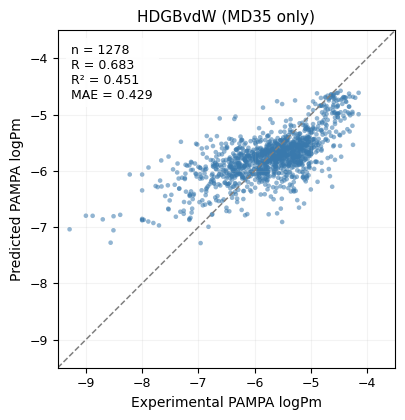


保存先:
/Users/teraimao/experiment/data/解析結果/conference_abstract_figures/HDGBvdW_MD35_seed0_scatter.png
/Users/teraimao/experiment/data/解析結果/conference_abstract_figures/HDGBvdW_MD35_seed0_scatter.pdf


In [49]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ==================================================
# 1. ファイル・設定
# ==================================================

PRED_CSV = (
    "/Users/teraimao/Downloads/"
    "ensemble_20seeds_by_source/"
    "test_predictions_all_seeds.csv"
)

OUT_DIR = (
    "/Users/teraimao/experiment/data/解析結果/"
    "conference_abstract_figures"
)

os.makedirs(OUT_DIR, exist_ok=True)

# ==================================================
# 2. CSV読み込み
# ==================================================

df = pd.read_csv(PRED_CSV)

# HDGBvdW / seed 0 / MD35 only
sub = df[
    (df["Model"].astype(str).str.lower() == "hdgbvdw")
    & (pd.to_numeric(df["seed"]) == 0)
].copy()

sub = sub.dropna(subset=["Observed", "MD_pred"])

if sub.empty:
    raise ValueError(
        "HDGBvdW / seed 0 の予測データがありません。"
    )

y_true = sub["Observed"].to_numpy(dtype=float)
y_pred = sub["MD_pred"].to_numpy(dtype=float)

# ==================================================
# 3. 性能評価
# ==================================================

R = np.corrcoef(y_true, y_pred)[0, 1]
R2 = r2_score(y_true, y_pred)
MAE = mean_absolute_error(y_true, y_pred)
RMSE = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"N = {len(sub)}")
print(f"R = {R:.4f}")
print(f"R² = {R2:.4f}")
print(f"MAE = {MAE:.4f}")
print(f"RMSE = {RMSE:.4f}")

# ==================================================
# 4. 学会要旨向け散布図
# ==================================================

fig, ax = plt.subplots(figsize=(4.6, 4.3))

ax.scatter(
    y_true,
    y_pred,
    s=11,
    alpha=0.55,
    color="#3979AD",
    edgecolors="none",
    rasterized=True
)

# 理想線 y=x
lims = [-9.5, -3.5]

ax.plot(
    lims,
    lims,
    "--",
    color="gray",
    linewidth=1.1
)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    "Experimental PAMPA logPm",
    fontsize=10
)
ax.set_ylabel(
    "Predicted PAMPA logPm",
    fontsize=10
)

ax.set_title(
    "HDGBvdW (MD35 only)",
    fontsize=11
)

# 指標表示
metrics_text = (
    f"n = {len(sub)}\n"
    f"R = {R:.3f}\n"
    f"R² = {R2:.3f}\n"
    f"MAE = {MAE:.3f}"
)

ax.text(
    0.04,
    0.96,
    metrics_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox=dict(
        facecolor="white",
        alpha=0.9,
        edgecolor="none"
    )
)

ax.tick_params(labelsize=9)
ax.grid(alpha=0.15)

fig.tight_layout()

# ==================================================
# 5. 保存
# ==================================================

png_path = os.path.join(
    OUT_DIR,
    "HDGBvdW_MD35_seed0_scatter.png"
)

pdf_path = os.path.join(
    OUT_DIR,
    "HDGBvdW_MD35_seed0_scatter.pdf"
)

fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("\n保存先:")
print(png_path)
print(pdf_path)

## 要旨ようの画像　PSA3D

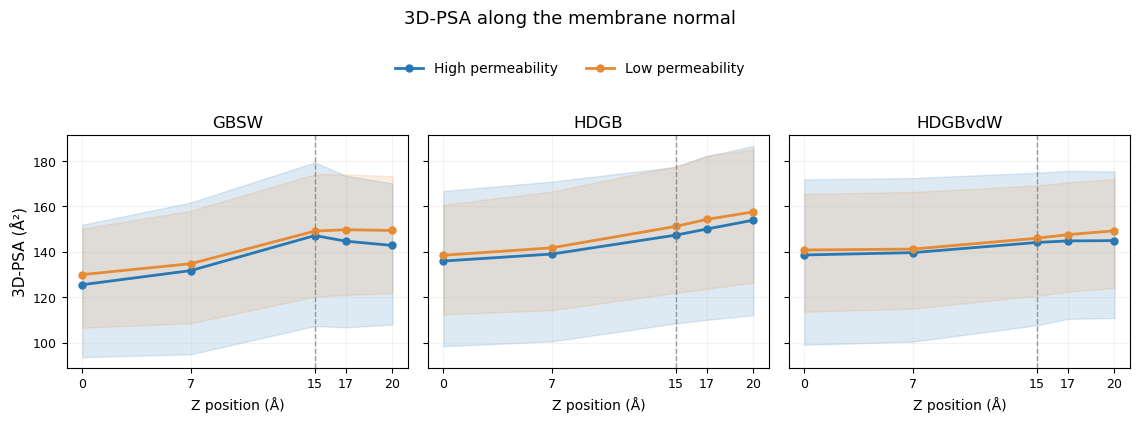

保存先:
/Users/teraimao/experiment/data/解析結果/conference_abstract_figures/3D_PSA_profile.png
/Users/teraimao/experiment/data/解析結果/conference_abstract_figures/3D_PSA_profile.pdf


In [51]:

# ==================================================
# 1. ファイル設定
# ==================================================

MD_CSV = (
    "/Users/teraimao/experiment/data/解析結果/"
    "membrane_position_analysis_top_bottom25/"
    "relative_PSA_analysis/"
    "relative_PSA_all_peptides.csv"
)

OUT_DIR = (
    "/Users/teraimao/experiment/data/解析結果/"
    "conference_abstract_figures"
)

os.makedirs(OUT_DIR, exist_ok=True)

# ==================================================
# 2. 描画する指標
# ==================================================

# 生の3D-PSAなら "PSA3D"
# TPSA規格化版なら "Relative_PSA"

VALUE_COL = "PSA3D"

if VALUE_COL == "PSA3D":
    YLABEL = "3D-PSA (Å²)"
    TITLE = "3D-PSA along the membrane normal"

elif VALUE_COL == "Relative_PSA":
    YLABEL = "3D-PSA / TPSA"
    TITLE = "Relative 3D-PSA along the membrane normal"

else:
    raise ValueError("Invalid VALUE_COL")

# ==================================================
# 3. CSV読み込み
# ==================================================

df = pd.read_csv(MD_CSV)

df["Model"] = df["Model"].astype(str).str.lower()

# 上下25%のみ
df = df[df["Group"].isin(["High", "Low"])].copy()

# 位置番号 → Z座標
position_to_z = {
    1: 0,
    2: 7,
    3: 15,
    4: 17,
    5: 20
}

df["Z"] = df["Position"].map(position_to_z)

# ==================================================
# 4. モデル・色の設定
# ==================================================

MODELS = ["gbsw", "hdgb", "hdgbvdw"]

MODEL_LABELS = {
    "gbsw": "GBSW",
    "hdgb": "HDGB",
    "hdgbvdw": "HDGBvdW"
}

COLORS = {
    "High": "#2878B5",
    "Low": "#E58B35"
}

# ==================================================
# 5. 平均・四分位点の集計
# ==================================================

summary = (
    df.groupby(["Model", "Group", "Z"])[VALUE_COL]
    .agg(
        Mean="mean",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

# ==================================================
# 6. 描画
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(11.5, 3.6),
    sharey=True
)

for ax, model in zip(axes, MODELS):

    for group in ["High", "Low"]:

        sub = summary[
            (summary["Model"] == model)
            & (summary["Group"] == group)
        ].sort_values("Z")

        x = sub["Z"].to_numpy()
        y = sub["Mean"].to_numpy()

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2,
            markersize=5,
            color=COLORS[group],
            label=group
        )

        ax.fill_between(
            x,
            sub["Q25"].to_numpy(),
            sub["Q75"].to_numpy(),
            color=COLORS[group],
            alpha=0.15
        )

    # 膜・水界面の目安
    ax.axvline(
        x=15,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8
    )

    ax.set_title(
        MODEL_LABELS[model],
        fontsize=12
    )

    ax.set_xticks([0, 7, 15, 17, 20])

    ax.set_xlabel(
        "Z position (Å)",
        fontsize=10
    )

    ax.tick_params(labelsize=9)
    ax.grid(alpha=0.15)

axes[0].set_ylabel(YLABEL, fontsize=11)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    ["High permeability", "Low permeability"],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.05),
    frameon=False,
    fontsize=10
)

fig.suptitle(
    TITLE,
    fontsize=13,
    y=1.16
)

fig.tight_layout()

# ==================================================
# 7. 保存
# ==================================================

filename = (
    "3D_PSA_profile"
    if VALUE_COL == "PSA3D"
    else "Relative_PSA_profile"
)

png_path = os.path.join(
    OUT_DIR, filename + ".png"
)

pdf_path = os.path.join(
    OUT_DIR, filename + ".pdf"
)

fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("保存先:")
print(png_path)
print(pdf_path)

## 要旨ようの画像　PSA3D

Common IDs: 6390
Saved summary: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/MD_position_mean_summary.csv


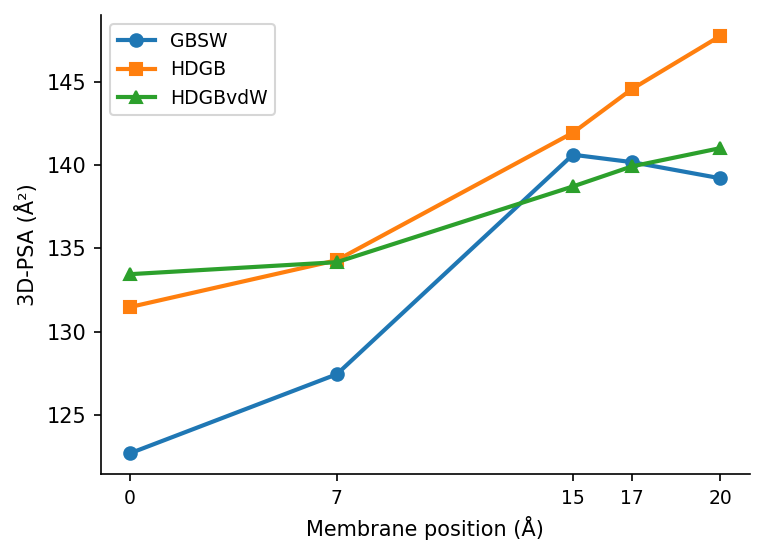

Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/Solv_Free_mean.png
Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/3D_PSA_mean.pdf


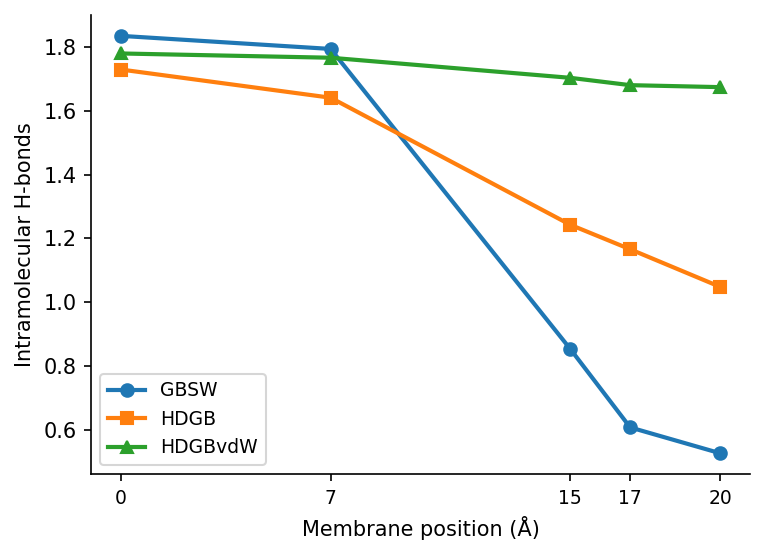

Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/Solv_Free_mean.png
Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/IMHB_mean.pdf


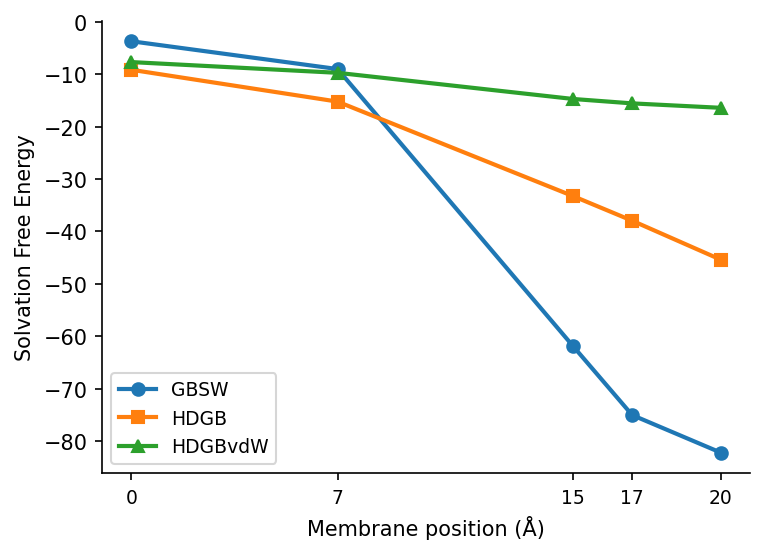

Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/Solv_Free_mean.png
Saved: /Users/teraimao/experiment/data/解析結果/conference_abstract_figures/Solv_Free_mean.pdf


In [61]:

# ==========================================================
# 1. 設定
# ==========================================================
BASE = "/Users/teraimao/experiment/data/解析結果"
OUT_DIR = os.path.join(BASE, "conference_abstract_figures")
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = ["gbsw", "hdgb", "hdgbvdw"]

MODEL_LABELS = {
    "gbsw": "GBSW",
    "hdgb": "HDGB",
    "hdgbvdw": "HDGBvdW"
}

# 膜位置（pos1～pos5）
POS_LABELS = ["pos1", "pos2", "pos3", "pos4", "pos5"]
Z_VALUES = [0, 7, 15, 17, 20]

# 描きたい特徴量
FEATURES = {
    "PSA3D": {
        "base": "PSA3D_Avg",
        "ylabel": "3D-PSA (Å²)",
        #"title": "Membrane-position dependence of 3D-PSA",
        "filename": "3D_PSA_mean"
    },
    "IMHB": {
        "base": "HB_Avg",
        "ylabel": "Intramolecular H-bonds",
        #"title": "Membrane-position dependence of IMHB",
        "filename": "IMHB_mean"
    },
    "Solv_Free": {
        "base": "Solv_Free_Avg",
        "ylabel": "Solvation Free Energy",
        #"title": "Membrane-position dependence of Solvation Free Energy",
        "filename": "Solv_Free_mean"
    }
}

# 色とマーカー（凡例で区別しやすくする）
STYLE = {
    "gbsw": {
        "color": "#1f77b4",   # blue
        "marker": "o"
    },
    "hdgb": {
        "color": "#ff7f0e",   # orange
        "marker": "s"
    },
    "hdgbvdw": {
        "color": "#2ca02c",   # green
        "marker": "^"
    }
}

# ==========================================================
# 2. データ読み込み
# ==========================================================
frames = {}

needed_cols = ["ID"]
for feature_name, conf in FEATURES.items():
    for i in range(1, 6):
        needed_cols.append(f"{conf['base']}_pos{i}")

needed_cols = list(dict.fromkeys(needed_cols))

for model in MODELS:
    path = os.path.join(
        BASE,
        f"{model}_common_successID_baselineB_strictPAMPA_psa3d.csv"
    )

    df = pd.read_csv(path, usecols=needed_cols, low_memory=False)

    # 数値化
    for col in needed_cols:
        if col != "ID":
            df[col] = pd.to_numeric(df[col], errors="coerce")

    df["ID"] = pd.to_numeric(df["ID"], errors="coerce")
    df = df.dropna(subset=["ID"]).copy()
    df["ID"] = df["ID"].astype(int)

    # 各特徴量列に欠損がある行を落とす
    value_cols = [c for c in needed_cols if c != "ID"]
    df = df.dropna(subset=value_cols).copy()

    # ID重複チェック
    if df["ID"].duplicated().any():
        raise ValueError(f"{model} に重複IDがあります")

    frames[model] = df.set_index("ID")

# ==========================================================
# 3. 3モデル共通IDにそろえる
# ==========================================================
common_ids = set(frames["gbsw"].index)
for model in MODELS[1:]:
    common_ids &= set(frames[model].index)

common_ids = sorted(common_ids)
print("Common IDs:", len(common_ids))

for model in MODELS:
    frames[model] = frames[model].loc[common_ids].copy()

# ==========================================================
# 4. 平均値を計算
# ==========================================================
rows = []

for model in MODELS:
    for feature_name, conf in FEATURES.items():
        for pos_idx, z in enumerate(Z_VALUES, start=1):
            col = f"{conf['base']}_pos{pos_idx}"

            rows.append({
                "Model": model,
                "Feature": feature_name,
                "Position": pos_idx,
                "Z": z,
                "Mean": frames[model][col].mean(),
                "N": len(frames[model])
            })

summary = pd.DataFrame(rows)

summary_path = os.path.join(OUT_DIR, "MD_position_mean_summary.csv")
summary.to_csv(summary_path, index=False)
print("Saved summary:", summary_path)

# ==========================================================
# 5. 特徴量ごとに1枚ずつ描画して保存
# ==========================================================
for feature_name, conf in FEATURES.items():

    fig, ax = plt.subplots(figsize=(5.2, 3.8), dpi=150)

    sub = summary[summary["Feature"] == feature_name].copy()

    for model in MODELS:
        d = sub[sub["Model"] == model].sort_values("Position")

        ax.plot(
            d["Z"],
            d["Mean"],
            color=STYLE[model]["color"],
            marker=STYLE[model]["marker"],
            linewidth=2.0,
            markersize=6,
            label=MODEL_LABELS[model]
        )

    #ax.set_title(conf["title"], fontsize=12)
    ax.set_xlabel("Membrane position (Å)", fontsize=10)
    ax.set_ylabel(conf["ylabel"], fontsize=10)

    ax.set_xticks(Z_VALUES)
    ax.set_xticklabels([str(z) for z in Z_VALUES], fontsize=9)

    # 点線・グリッドなし
    ax.grid(False)

    # 枠を少しすっきり
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 凡例を各画像に入れる
    ax.legend(frameon=True, fontsize=9, loc="best")

    plt.tight_layout()

    #out_png = os.path.join(OUT_DIR, conf["filename"] + ".png")
    out_pdf = os.path.join(OUT_DIR, conf["filename"] + ".pdf")

    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()

    print("Saved:", out_png)
    print("Saved:", out_pdf)